## Setup

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

# Show plots directly in the notebook instead of using the non-display Agg backend.
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

# ── project root (portable — override via THESIS_DATA_ROOT env var) ───────
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

# === EDIT ONLY IF YOUR PHASE 3 RUN FOLDER NAME DIFFERS ===
INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"         # optional, informational

# All figures now save under THESIS_DATA_ROOT rather than a path relative to
# wherever the notebook happens to be launched from.
figdir = THESIS_DATA_ROOT / "figures_extended"
figdir.mkdir(parents=True, exist_ok=True)

In [4]:
TARGET_LAMBDA = 0.977          # proposal Phase 3, ~30 bday half-life
SP_THRESHOLD  = 2.0            # |SP| threshold for EM-DAT coincidence
EMDAT_WINDOW  = 2              # +/- days around EM-DAT date
N_PERMUTATIONS = 5000          # permutation test draws
RANDOM_STATE  = 0

figdir = Path("./figures_extended")
figdir.mkdir(parents=True, exist_ok=True)

## Load data

### Index 

In [5]:
import os
from pathlib import Path

# ── project root (portable — override via THESIS_DATA_ROOT env var) ───────
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

# ── Submission Ready root (portable — override via SUBMISSION_ROOT env var) ──
# This is where your actual final-run data and outputs live, separate from
# the pipeline's own working directory above.
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "Submission Ready")
)).resolve()

# === EDIT ONLY IF YOUR PHASE 3 RUN FOLDER NAME DIFFERS ===
INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

# New figures folder, at Submission Ready level (not nested under Actual Run Data)
figdir = SUBMISSION_ROOT / "Visuals" / "Predeterminedness"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")

SUBMISSION_ROOT: /Users/adammcguire/Desktop/Submission Ready  ✓
  Indices: /Users/adammcguire/Desktop/Submission Ready/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adammcguire/Desktop/Submission Ready/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Figures: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness  ✓ created/exists


In [6]:
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])
if "DSP" in df.columns:
    df = df.rename(columns={"DSP": "CSP"})
print(f"✓ df loaded: {len(df):,} rows, columns: {list(df.columns)}")

✓ df loaded: 4,697 rows, columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'CSP']


In [7]:
from pathlib import Path

# Derived paths — now under Submission Ready, not THESIS_DATA_ROOT
EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name → ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adammcguire/Desktop/Submission Ready  ✓
  EM-DAT:    /Users/adammcguire/Desktop/Submission Ready/Financial Data/Disaster  ✓
  Other Idx: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices  ✓


In [8]:
# ── Path ──────────────────────────────────────────────────────────────────────
# Now under Submission Ready / Financial data / Other Indices (same folder as CPU)

EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )

# ── Load ──────────────────────────────────────────────────────────────────────

epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

# ── Build date from year + month + day ───────────────────────────────────────

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

# ── Clean + filter ────────────────────────────────────────────────────────────

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

# ── Summary ───────────────────────────────────────────────────────────────────

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


In [9]:
# =============================================================================
# EM-DAT EVENT LOADING — US
# =============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ── EM-DAT file (US only, under Submission Ready) ────────────────────────────
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

print(f"  EM-DAT US path: {EMDAT_FILES['US']}")
print(f"  Exists        : {'✓' if EMDAT_FILES['US'].exists() else '✗ NOT FOUND'}")

if not EMDAT_FILES["US"].exists():
    raise FileNotFoundError(
        f"EM-DAT file not found at {EMDAT_FILES['US']}\n"
        f"Files currently in EM-DAT folder:\n"
        + ("\n".join(f"  {f.name}" for f in EMDAT_DIR.iterdir())
           if EMDAT_DIR.exists() else f"  (folder itself doesn't exist: {EMDAT_DIR})")
    )

# ── Load US EM-DAT file ───────────────────────────────────────────────────────

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

# ── Identify date column ──────────────────────────────────────────────────────

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

# ── Filter to sample period + drop undated rows ───────────────────────────────

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")

# ── Build emdat_dates (used by the permutation test cell) ────────────────────

emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]

print(f"  emdat_dates ready : {len(emdat_dates):,} dates")

# ── Build EMDAT_EVENTS (label + acute/chronic classification) ────────────────
# Needed by the spike-proximity table cell below.

_desc_col = next(
    (c for c in ["Disaster Type", "Event Name", "Disaster Subtype", "Type"]
     if c in emdat_us.columns), None)

_type_col = next(
    (c for c in ["Disaster Subtype", "Disaster Type", "Event Type"]
     if c in emdat_us.columns), None)

_chronic_terms = [
    "drought", "sea level", "heat stress", "extreme temperature",
    "cold wave", "heat wave", "wildfire", "land fire"
]

def _classify_type(row):
    if _type_col is None:
        return "acute"
    val = str(row[_type_col]).lower()
    return "chronic" if any(t in val for t in _chronic_terms) else "acute"

emdat_us["etype"] = emdat_us.apply(_classify_type, axis=1)

if _desc_col:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        emdat_us[_desc_col].fillna("Unknown"),
        emdat_us["etype"]
    ))
else:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        ["Event"] * len(emdat_us),
        emdat_us["etype"]
    ))

print(f"  EMDAT_EVENTS ready: {len(EMDAT_EVENTS):,} entries "
      f"({emdat_us['etype'].eq('acute').sum():,} acute, "
      f"{emdat_us['etype'].eq('chronic').sum():,} chronic)")

  EM-DAT US path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Disaster/EMDAT_US.xlsx
  Exists        : ✓

✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date f

In [10]:
# ── Path ──────────────────────────────────────────────────────────────────────
# Now under Submission Ready / Financial data / Other Indices — same folder as EPU
CPU_PATH = EPU_DIR / "cpu_pu.xlsx"
print(f"  CPU path: {CPU_PATH}")
print(f"  Exists  : {'✓' if CPU_PATH.exists() else '✗ NOT FOUND'}")

if not CPU_PATH.exists():
    raise FileNotFoundError(
        f"CPU file not found at {CPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + ("\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
           if EPU_DIR.exists() else f"  (folder itself doesn't exist: {EPU_DIR})"))

# ── Inspect sheets ────────────────────────────────────────────────────────────
xl = pd.ExcelFile(CPU_PATH)
print(f"\n  Sheets available: {xl.sheet_names}")

# ── Load sheet 2 (data) — force date column as string ────────────────────────
cpu_raw = pd.read_excel(
    CPU_PATH,
    sheet_name=xl.sheet_names[1],
    dtype={"date": str})

print(f"\n✓ Loaded CPU from sheet: '{xl.sheet_names[1]}'")
print(f"  Rows              : {len(cpu_raw):,}")
print(f"  Columns           : {list(cpu_raw.columns)}")
print(f"  Date sample (raw) : {cpu_raw['date'].head(5).tolist()}")
display(cpu_raw.head(5))

# ── Build date — handle 1985M01 format ───────────────────────────────────────
cpu_raw["date"] = pd.to_datetime(
    cpu_raw["date"].astype(str).str.strip().str.replace("M", "-") + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)
print(f"\n  Date sample (parsed): {cpu_raw['date'].dropna().head(3).tolist()}")

# ── Select index columns ──────────────────────────────────────────────────────
cpu_value_cols = [c for c in cpu_raw.columns if c not in
                  ["year", "month", "day", "date"]]
print(f"  CPU value columns found: {cpu_value_cols}")

cpu_df = cpu_raw[["date"] + cpu_value_cols].copy()

# ── Standardise column names ──────────────────────────────────────────────────
rename_map = {}
for col in cpu_value_cols:
    col_lower = col.lower()
    if "narrow" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_narrow"
    elif "broad" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_broad"
    elif "gavriilidis" in col_lower or col_lower in ["cpu", "cpu_index"]:
        rename_map[col] = "cpu_index_gavriilidis"
    elif "news" in col_lower and "narrow" in col_lower:
        rename_map[col] = "cpnews_index_narrow"
    elif "news" in col_lower and "broad" in col_lower:
        rename_map[col] = "cpnews_index_broad"
    elif "sent" in col_lower:
        rename_map[col] = "cpsent_index"
    elif "instrument" in col_lower:
        rename_map[col] = "cpu_instrument"
    elif "shock" in col_lower:
        rename_map[col] = "cpu_shock"

if rename_map:
    cpu_df = cpu_df.rename(columns=rename_map)
    print(f"  Renamed columns: {rename_map}")

# ── Convert value columns to numeric ─────────────────────────────────────────
for col in cpu_df.columns:
    if col != "date":
        cpu_df[col] = pd.to_numeric(cpu_df[col], errors="coerce")

cpu_df = (cpu_df
    .dropna(subset=["date"])
    .loc[lambda d: (d["date"] >= "2008-01-01") & (d["date"] <= "2025-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\n✓ cpu_df ready")
print(f"  Observations : {len(cpu_df):,}")
print(f"  Date range   : {cpu_df['date'].min().date()} "
      f"→ {cpu_df['date'].max().date()}")
print(f"  Columns      : {list(cpu_df.columns)}")
for col in cpu_df.columns:
    if col != "date":
        non_null = cpu_df[col].dropna()
        if len(non_null) > 0:
            print(f"  {col:<30s} mean={non_null.mean():.2f}  "
                  f"max={non_null.max():.2f}  "
                  f"n={len(non_null):,}")
        else:
            print(f"  {col:<30s} all NaN")
display(cpu_df.head())

  CPU path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices/cpu_pu.xlsx
  Exists  : ✓

  Sheets available: ['readme', 'data']

✓ Loaded CPU from sheet: 'data'
  Rows              : 492
  Columns           : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Date sample (raw) : ['1985M01', '1985M02', '1985M03', '1985M04', '1985M05']


,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,1985M01,35.469868,67.558322,NaN,52.560527,54.654046,146.698243,NaN,NaN
1,1985M02,12.957033,16.960149,NaN,51.736757,51.679215,98.249098,NaN,NaN
2,1985M03,35.618421,61.085415,NaN,60.033463,58.400578,229.254864,NaN,NaN
3,1985M04,59.485346,48.462095,NaN,47.960487,51.492845,178.405419,NaN,NaN
4,1985M05,26.375457,34.621114,NaN,46.887293,49.883908,90.879046,NaN,NaN



  Date sample (parsed): [Timestamp('1985-01-01 00:00:00'), Timestamp('1985-02-01 00:00:00'), Timestamp('1985-03-01 00:00:00')]
  CPU value columns found: ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Renamed columns: {'cpu_index_narrow': 'cpu_index_narrow', 'cpu_index_broad': 'cpu_index_broad', 'cpu_index_gavriilidis': 'cpu_index_gavriilidis', 'cpnews_index_narrow': 'cpnews_index_narrow', 'cpnews_index_broad': 'cpnews_index_broad', 'cpsent_index': 'cpsent_index', 'cpu_instrument': 'cpu_instrument', 'cpu_shock': 'cpu_shock'}

✓ cpu_df ready
  Observations : 216
  Date range   : 2008-01-01 → 2025-12-01
  Columns      : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  cpu_index_narrow               mean=258.70  max=916.28  n=216
  cpu_index_broad               

,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613
1,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075
2,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754
3,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395
4,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724


### Sovereign

In [11]:

# Check INDICES_PATH
try:
    INDICES_PATH
    print(f"✓ INDICES_PATH: {INDICES_PATH}")
except NameError:
    INDICES_PATH = ROOT / "indices" / "US_daily_index.csv"
    print(f"  INDICES_PATH set to: {INDICES_PATH}")

# ── Yield configuration — TY.csv lives directly in Sovereign folder ──────────
SOVEREIGN_DIR = SUBMISSION_ROOT / "Financial Data" / "Sovereign"

if not SOVEREIGN_DIR.exists():
    raise FileNotFoundError(
        f"'Sovereign' folder not found at {SOVEREIGN_DIR}. "
        f"Contents of Financial Data:\n"
        + "\n".join(f"  {p.name}" for p in (SUBMISSION_ROOT / "Financial Data").iterdir())
    )

YIELDS_DIR    = SOVEREIGN_DIR
YIELD_TICKERS = {"US": "TY"}

print(f"✓ YIELDS_DIR: {YIELDS_DIR}")
print(f"✓ YIELD_TICKERS: {YIELD_TICKERS}")

# ── ACM term premium + MOVE index — confirmed filenames ───────────────────────
ACM_PATH  = SOVEREIGN_DIR / "ACMTermPremium.xls"
MOVE_PATH = SOVEREIGN_DIR / "MOVE Index.csv"

for _label, _path in [("ACM term premium", ACM_PATH), ("MOVE index", MOVE_PATH)]:
    print(f"{_label:<18s}: {_path}  {'✓' if _path.exists() else '✗ NOT FOUND'}")

if not ACM_PATH.exists() or not MOVE_PATH.exists():
    raise FileNotFoundError(
        f"One or more files not found. Actual contents of {SOVEREIGN_DIR}:\n"
        + "\n".join(f"  {p.name}" for p in SOVEREIGN_DIR.iterdir())
    )

✓ INDICES_PATH: /Users/adammcguire/Desktop/Submission Ready/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv
✓ YIELDS_DIR: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign
✓ YIELD_TICKERS: {'US': 'TY'}
ACM term premium  : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign/ACMTermPremium.xls  ✓
MOVE index        : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign/MOVE Index.csv  ✓


In [12]:
if "country" in df.columns:
    country = df["country"].dropna().iloc[0]
else:
    country = "US"

ticker     = YIELD_TICKERS[country]
yield_file = YIELDS_DIR / f"{ticker}.csv"

print(f"Country    : {country}")
print(f"Ticker     : {ticker}")
print(f"File       : {yield_file}")
print(f"Exists     : {'✓' if yield_file.exists() else '✗ NOT FOUND'}")

if not yield_file.exists():
    raise FileNotFoundError(f"Yield file not found: {yield_file}")

Country    : US
Ticker     : TY
File       : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign/TY.csv
Exists     : ✓


In [13]:
yield_df = pd.read_csv(yield_file)
print(f"\nColumns : {yield_df.columns.tolist()}")
display(yield_df.head(3))


Columns : ['Date', 'Time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Tick Count']


,Date,Time,Open,High,Low,Close,Volume,Tick Count
0,01/03/1983,08:01,30.779785,30.791172,30.779785,30.791172,0,2
1,01/03/1983,08:02,30.779785,30.813947,30.768398,30.813947,0,6
2,01/03/1983,08:03,30.802559,30.813947,30.802559,30.813947,0,2


In [14]:
# ── Load MOVE index ───────────────────────────────────────────────────────────

move_df = pd.read_csv(MOVE_PATH)
print(f"MOVE columns: {list(move_df.columns)}")
display(move_df.head(3))

MOVE columns: ['index', 'us']


,index,us
0,1980-01-01T00:00:00.000Z,NaN
1,1980-01-02T00:00:00.000Z,NaN
2,1980-01-03T00:00:00.000Z,NaN


In [15]:
# ── Load ACM term premium (Adrian-Crump-Moench decomposition) ────────────────
# .xls (old Excel format) — needs the 'xlrd' engine, not openpyxl.
# If this errors with "Missing optional dependency 'xlrd'", run:
#   pip install xlrd

acm_xl = pd.ExcelFile(ACM_PATH, engine="xlrd")
print(f"ACM sheets available: {acm_xl.sheet_names}")

acm_raw = pd.read_excel(ACM_PATH, sheet_name=acm_xl.sheet_names[0], engine="xlrd")
print(f"\nACM columns: {list(acm_raw.columns)}")
display(acm_raw.head(3))

ACM sheets available: ['ACM Monthly', 'ACM Daily']

ACM columns: ['DATE', 'ACMY01', 'ACMY02', 'ACMY03', 'ACMY04', 'ACMY05', 'ACMY06', 'ACMY07', 'ACMY08', 'ACMY09', 'ACMY10', 'ACMTP01', 'ACMTP02', 'ACMTP03', 'ACMTP04', 'ACMTP05', 'ACMTP06', 'ACMTP07', 'ACMTP08', 'ACMTP09', 'ACMTP10', 'ACMRNY01', 'ACMRNY02', 'ACMRNY03', 'ACMRNY04', 'ACMRNY05', 'ACMRNY06', 'ACMRNY07', 'ACMRNY08', 'ACMRNY09', 'ACMRNY10']


,DATE,ACMY01,ACMY02,ACMY03,ACMY04,ACMY05,ACMY06,ACMY07,ACMY08,ACMY09,...,ACMRNY01,ACMRNY02,ACMRNY03,ACMRNY04,ACMRNY05,ACMRNY06,ACMRNY07,ACMRNY08,ACMRNY09,ACMRNY10
0,30-Jun-1961,2.898392,3.269093,3.494273,3.629225,3.712136,3.765667,3.802552,3.829696,3.850697,...,2.978981,3.287989,3.445555,3.533875,3.588507,3.625226,3.651491,3.671104,3.686165,3.697927
1,31-Jul-1961,2.762469,3.222276,3.502939,3.677051,3.789403,3.865989,3.921442,3.963844,3.997574,...,2.747459,3.099852,3.283475,3.390455,3.459412,3.507572,3.543235,3.570739,3.592542,3.610151
2,31-Aug-1961,2.983958,3.388366,3.637993,3.789299,3.882975,3.943653,3.985372,4.015859,4.039223,...,3.033915,3.347697,3.507830,3.596935,3.651256,3.687002,3.711896,3.729903,3.743229,3.753195


In [16]:
# ── Inspect data_export.csv ───────────────────────────────────────────────────

DATA_EXPORT_PATH = SOVEREIGN_DIR / "data_export.csv"

print(f"data_export.csv: {DATA_EXPORT_PATH}  {'✓' if DATA_EXPORT_PATH.exists() else '✗ NOT FOUND'}")

if not DATA_EXPORT_PATH.exists():
    raise FileNotFoundError(
        f"'data_export.csv' not found at {DATA_EXPORT_PATH}. "
        f"Contents of Sovereign:\n"
        + "\n".join(f"  {p.name}" for p in SOVEREIGN_DIR.iterdir())
    )

data_export_raw = pd.read_csv(DATA_EXPORT_PATH)
print(f"\nRows    : {len(data_export_raw):,}")
print(f"Columns : {list(data_export_raw.columns)}")
display(data_export_raw.head(5))

data_export.csv: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign/data_export.csv  ✓

Rows    : 9,124
Columns : ["('index', '')", "('Bond_futures', 'EUR2Y')", "('Bond_futures', 'EUR5Y')", "('Bond_futures', 'EUR10Y')", "('Bond_futures', 'EUR30Y')", "('Bond_futures', 'USD2Y')", "('Bond_futures', 'USD5Y')", "('Bond_futures', 'USD10Y')", "('Bond_futures', 'USD30Y')", "('Bond_futures', 'JPY10Y')", "('Bond_futures', 'GBP10Y')", "('Bond_futures', 'CAD10Y')", "('Bond_futures', 'AUD10Y')", "('CDX', 'IG_US')", "('CDX', 'HY_US')", "('CDX', 'IG_EU')", "('CDX', 'HY_EU')", "('Equity_futures', 'FR')", "('Equity_futures', 'UK')", "('Equity_futures', 'US')", "('Equity_futures', 'SP')", "('Equity_futures', 'EU')", "('Equity_futures', 'AU')", "('Equity_futures', 'KO')", "('Equity_futures', 'IT')", "('Equity_futures', 'CA')", "('Equity_futures', 'CH')", "('Equity_futures', 'HK')", "('Equity_futures', 'TW')", "('Equity_futures', 'NL')", "('Equity_futures', 'JP')", "('Equity_futures', 'S

,"('index', '')","('Bond_futures', 'EUR2Y')","('Bond_futures', 'EUR5Y')","('Bond_futures', 'EUR10Y')","('Bond_futures', 'EUR30Y')","('Bond_futures', 'USD2Y')","('Bond_futures', 'USD5Y')","('Bond_futures', 'USD10Y')","('Bond_futures', 'USD30Y')","('Bond_futures', 'JPY10Y')",...,"('Commodity_futures', 'HO2')","('Commodity_futures', 'NG2')","('Commodity_futures', 'XBW2')","('Commodity_futures', 'GC2')","('Commodity_futures', 'SI2')","('Commodity_futures', 'LA2')","('Commodity_futures', 'LP2')","('Commodity_futures', 'LL2')","('Commodity_futures', 'LN2')","('Commodity_futures', 'LX2')"
0,1990-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1990-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1990-01-03,NaN,NaN,NaN,NaN,NaN,-0.000525,-0.000365,NaN,NaN,...,0.022354,NaN,0.025649,-0.014247,-0.006004,NaN,NaN,NaN,NaN,NaN
3,1990-01-04,NaN,NaN,NaN,NaN,NaN,0.000081,0.000104,NaN,NaN,...,-0.029749,NaN,-0.026665,0.011214,0.022084,NaN,NaN,NaN,NaN,NaN
4,1990-01-05,NaN,NaN,NaN,NaN,NaN,-0.000041,-0.000052,NaN,NaN,...,-0.045991,NaN,-0.030955,0.018975,0.009418,NaN,NaN,NaN,NaN,NaN


In [17]:
# ── Inspect data_export.csv ───────────────────────────────────────────────────

DATA_EXPORT_PATH = SOVEREIGN_DIR / "data_export.csv"

print(f"data_export.csv: {DATA_EXPORT_PATH}  {'✓' if DATA_EXPORT_PATH.exists() else '✗ NOT FOUND'}")

if not DATA_EXPORT_PATH.exists():
    raise FileNotFoundError(
        f"'data_export.csv' not found at {DATA_EXPORT_PATH}. "
        f"Contents of Sovereign:\n"
        + "\n".join(f"  {p.name}" for p in SOVEREIGN_DIR.iterdir())
    )

data_export_raw = pd.read_csv(DATA_EXPORT_PATH)
print(f"\nRows    : {len(data_export_raw):,}")
print(f"Columns : {list(data_export_raw.columns)}")
display(data_export_raw.head(5))
display(data_export_raw.tail(5))
print(f"\nDtypes:\n{data_export_raw.dtypes}")

data_export.csv: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Sovereign/data_export.csv  ✓

Rows    : 9,124
Columns : ["('index', '')", "('Bond_futures', 'EUR2Y')", "('Bond_futures', 'EUR5Y')", "('Bond_futures', 'EUR10Y')", "('Bond_futures', 'EUR30Y')", "('Bond_futures', 'USD2Y')", "('Bond_futures', 'USD5Y')", "('Bond_futures', 'USD10Y')", "('Bond_futures', 'USD30Y')", "('Bond_futures', 'JPY10Y')", "('Bond_futures', 'GBP10Y')", "('Bond_futures', 'CAD10Y')", "('Bond_futures', 'AUD10Y')", "('CDX', 'IG_US')", "('CDX', 'HY_US')", "('CDX', 'IG_EU')", "('CDX', 'HY_EU')", "('Equity_futures', 'FR')", "('Equity_futures', 'UK')", "('Equity_futures', 'US')", "('Equity_futures', 'SP')", "('Equity_futures', 'EU')", "('Equity_futures', 'AU')", "('Equity_futures', 'KO')", "('Equity_futures', 'IT')", "('Equity_futures', 'CA')", "('Equity_futures', 'CH')", "('Equity_futures', 'HK')", "('Equity_futures', 'TW')", "('Equity_futures', 'NL')", "('Equity_futures', 'JP')", "('Equity_futures', 'S

,"('index', '')","('Bond_futures', 'EUR2Y')","('Bond_futures', 'EUR5Y')","('Bond_futures', 'EUR10Y')","('Bond_futures', 'EUR30Y')","('Bond_futures', 'USD2Y')","('Bond_futures', 'USD5Y')","('Bond_futures', 'USD10Y')","('Bond_futures', 'USD30Y')","('Bond_futures', 'JPY10Y')",...,"('Commodity_futures', 'HO2')","('Commodity_futures', 'NG2')","('Commodity_futures', 'XBW2')","('Commodity_futures', 'GC2')","('Commodity_futures', 'SI2')","('Commodity_futures', 'LA2')","('Commodity_futures', 'LP2')","('Commodity_futures', 'LL2')","('Commodity_futures', 'LN2')","('Commodity_futures', 'LX2')"
0,1990-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1990-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1990-01-03,NaN,NaN,NaN,NaN,NaN,-0.000525,-0.000365,NaN,NaN,...,0.022354,NaN,0.025649,-0.014247,-0.006004,NaN,NaN,NaN,NaN,NaN
3,1990-01-04,NaN,NaN,NaN,NaN,NaN,0.000081,0.000104,NaN,NaN,...,-0.029749,NaN,-0.026665,0.011214,0.022084,NaN,NaN,NaN,NaN,NaN
4,1990-01-05,NaN,NaN,NaN,NaN,NaN,-0.000041,-0.000052,NaN,NaN,...,-0.045991,NaN,-0.030955,0.018975,0.009418,NaN,NaN,NaN,NaN,NaN


,"('index', '')","('Bond_futures', 'EUR2Y')","('Bond_futures', 'EUR5Y')","('Bond_futures', 'EUR10Y')","('Bond_futures', 'EUR30Y')","('Bond_futures', 'USD2Y')","('Bond_futures', 'USD5Y')","('Bond_futures', 'USD10Y')","('Bond_futures', 'USD30Y')","('Bond_futures', 'JPY10Y')",...,"('Commodity_futures', 'HO2')","('Commodity_futures', 'NG2')","('Commodity_futures', 'XBW2')","('Commodity_futures', 'GC2')","('Commodity_futures', 'SI2')","('Commodity_futures', 'LA2')","('Commodity_futures', 'LP2')","('Commodity_futures', 'LL2')","('Commodity_futures', 'LN2')","('Commodity_futures', 'LX2')"
9119,2024-12-13,-0.000626,-0.000644,-0.000652,-0.000527,-0.000495,-0.000678,-0.000769,-0.000687,0.000127,...,0.013621,-0.013257,0.005858,-0.012123,-0.018172,0.001985,-0.004513,0.001564,-0.019080,0.006712
9120,2024-12-16,0.000082,0.000118,0.000083,0.000007,0.000094,-0.000117,-0.000025,0.000080,-0.000265,...,-0.003801,-0.018882,-0.012241,-0.002150,0.001023,-0.015039,0.000487,-0.004783,-0.010450,-0.012807
9121,2024-12-17,-0.000055,0.000000,0.000102,0.000235,0.000141,0.000058,0.000074,0.000304,-0.000117,...,-0.014643,0.009623,-0.013492,-0.002898,-0.004343,-0.009784,-0.008082,-0.007649,-0.013134,-0.006632
9122,2024-12-18,0.000136,-0.000117,-0.000203,-0.000255,-0.001438,-0.001438,-0.001405,-0.000842,0.000181,...,0.010177,0.001833,-0.000304,-0.003055,-0.005613,-0.005302,0.004250,-0.002215,0.000201,-0.013409
9123,2024-12-19,-0.000273,-0.000509,-0.000656,-0.000577,0.000898,-0.000176,-0.000647,-0.000842,-0.000255,...,-0.007132,0.046103,-0.010539,-0.017006,-0.042962,-0.007871,-0.016151,-0.005192,-0.025359,-0.009448



Dtypes:
('index', '')                       str
('Bond_futures', 'EUR2Y')       float64
('Bond_futures', 'EUR5Y')       float64
('Bond_futures', 'EUR10Y')      float64
('Bond_futures', 'EUR30Y')      float64
                                 ...   
('Commodity_futures', 'LA2')    float64
('Commodity_futures', 'LP2')    float64
('Commodity_futures', 'LL2')    float64
('Commodity_futures', 'LN2')    float64
('Commodity_futures', 'LX2')    float64
Length: 68, dtype: object


## Helpers

In [18]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


results: list[CheckResult] = []


## Main Application

### Ensure Data Excistance and Guards

In [19]:
# ── Build yields_by_mat from data_export.csv (USD Bond_futures) ──────────────
# Columns are string-repr tuples like "('Bond_futures', 'USD10Y')" — parse
# them back into real tuples before doing any matching.

import ast

def _parse_col(c):
    if isinstance(c, str) and c.startswith("(") and c.endswith(")"):
        try:
            return ast.literal_eval(c)
        except (ValueError, SyntaxError):
            return c
    return c

data_export_raw.columns = [_parse_col(c) for c in data_export_raw.columns]

print(f"Sample parsed columns: {list(data_export_raw.columns)[:5]}")
print(f"Column types after parse: {set(type(c).__name__ for c in data_export_raw.columns)}")

date_col = ("index", "") if ("index", "") in data_export_raw.columns else "date"
if date_col not in data_export_raw.columns:
    raise RuntimeError(
        f"Expected a date-like column (\"index\" or \"date\") not found after "
        f"parsing. Columns: {list(data_export_raw.columns)[:5]}..."
    )

mat_col_map = {
    "2Y":  ("Bond_futures", "USD2Y"),
    "5Y":  ("Bond_futures", "USD5Y"),
    "10Y": ("Bond_futures", "USD10Y"),
    "30Y": ("Bond_futures", "USD30Y"),
}

missing = [m for m, c in mat_col_map.items() if c not in data_export_raw.columns]
if missing:
    raise RuntimeError(
        f"Expected USD Bond_futures columns missing for maturities: {missing}. "
        f"Available Bond_futures columns: "
        f"{[c for c in data_export_raw.columns if isinstance(c, tuple) and c[0] == 'Bond_futures']}"
    )

yields_by_mat = {}
for mat, col in mat_col_map.items():
    s = data_export_raw[[date_col, col]].copy()
    s.columns = ["date", "value"]
    s["date"] = pd.to_datetime(s["date"], errors="coerce")
    s["value"] = pd.to_numeric(s["value"], errors="coerce")
    s = s.dropna(subset=["date", "value"]).sort_values("date").reset_index(drop=True)
    yields_by_mat[mat] = s

    print(f"  {mat:<4s} ({col[1]}): {len(s):,} obs, "
          f"{s['date'].min().date()} → {s['date'].max().date()}, "
          f"mean={s['value'].mean():.3f}")

print(f"\n✓ yields_by_mat built for: {list(yields_by_mat.keys())}")

Sample parsed columns: [('index', ''), ('Bond_futures', 'EUR2Y'), ('Bond_futures', 'EUR5Y'), ('Bond_futures', 'EUR10Y'), ('Bond_futures', 'EUR30Y')]
Column types after parse: {'tuple'}


  2Y   (USD2Y): 8,998 obs, 1990-06-26 → 2024-12-19, mean=0.000
  5Y   (USD5Y): 9,122 obs, 1990-01-03 → 2024-12-19, mean=0.000
  10Y  (USD10Y): 9,122 obs, 1990-01-03 → 2024-12-19, mean=0.000
  30Y  (USD30Y): 3,917 obs, 2009-12-16 → 2024-12-19, mean=0.000

✓ yields_by_mat built for: ['2Y', '5Y', '10Y', '30Y']


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import statsmodels.api as sm
from pathlib import Path

H       = 20
NW_LAGS = H + 1

mat_order = ["2Y", "5Y", "10Y", "30Y"]

SPECS = {
    "baseline":      [],
    "+MOVE":         ["move"],
    "+CPU":          ["cpu"],
    "+EPU":          ["epu"],
    "+MOVE+CPU":     ["move", "cpu"],
    "+MOVE+EPU":     ["move", "epu"],
    "+MOVE+CPU+EPU": ["move", "cpu", "epu"],
}

# Guards
if "yields_by_mat" not in globals() or not yields_by_mat:
    raise RuntimeError(
        "yields_by_mat missing — run the yields_by_mat construction cell first."
    )
if "epu_df" not in globals() or epu_df.empty:
    raise RuntimeError("epu_df missing — run EPU loading cell first.")
if "cpu_df" not in globals() or cpu_df.empty:
    raise RuntimeError("cpu_df missing — run CPU loading cell first.")
if "move_df" not in globals() or move_df.empty:
    raise RuntimeError("move_df missing — run MOVE loading cell first.")
if "INDICES_PATH" not in globals():
    raise RuntimeError("INDICES_PATH not defined — run configuration cell first.")

available_mats = [m for m in mat_order if m in yields_by_mat]
print(f"✓ Maturities available : {available_mats}")
print(f"✓ H = {H}, NW_LAGS = {NW_LAGS}")

✓ Maturities available : ['2Y', '5Y', '10Y', '30Y']
✓ H = 20, NW_LAGS = 21


### Build Master Panel

In [21]:
# Guards
for _name in ("INDICES_PATH", "epu_df", "move_df"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its loading cell first.")

# Reload PCRA from file — df may be overwritten by other cells
_pcra = pd.read_csv(INDICES_PATH)
_pcra["date"] = pd.to_datetime(_pcra["date"], errors="coerce")

if "DSP" in _pcra.columns and "CSP" not in _pcra.columns:
    _pcra = _pcra.rename(columns={"DSP": "CSP"})

_required_pcra_cols = ["date", "S_daily", "SSI", "CSP"]
_missing_pcra = [c for c in _required_pcra_cols if c not in _pcra.columns]
if _missing_pcra:
    raise RuntimeError(
        f"PCRA file missing expected columns: {_missing_pcra}. "
        f"Actual columns: {list(_pcra.columns)}"
    )

pcra             = _pcra[_required_pcra_cols].copy()
pcra["SSI_lag1"] = pcra["SSI"].shift(1)
pcra             = pcra.sort_values("date").reset_index(drop=True)

print(f"✓ PCRA loaded: {len(pcra):,} obs  "
      f"({pcra['date'].min().date()} → {pcra['date'].max().date()})")

# EPU — forward-fill monthly to daily business days
epu_daily = (epu_df[["date", "epu"]]
    .copy()
    .set_index("date")
    .reindex(pd.date_range(epu_df["date"].min(),
                           epu_df["date"].max(), freq="B"))
    .ffill()
    .reset_index()
    .rename(columns={"index": "date"}))

# CPU — Gavriilidis variant, forward-filled monthly → daily business days
if "cpu_df" in globals() and cpu_df is not None and not cpu_df.empty:
    if "cpu_index_gavriilidis" not in cpu_df.columns:
        raise RuntimeError(
            f"cpu_df exists but 'cpu_index_gavriilidis' column not found. "
            f"Actual columns: {list(cpu_df.columns)}"
        )
    cpu_daily = (cpu_df[["date", "cpu_index_gavriilidis"]]
        .copy()
        .rename(columns={"cpu_index_gavriilidis": "cpu"})
        .set_index("date")
        .reindex(pd.date_range(cpu_df["date"].min(),
                               cpu_df["date"].max(), freq="B"))
        .ffill()
        .reset_index()
        .rename(columns={"index": "date"}))
    print(f"✓ CPU built (cpu_index_gavriilidis, ffilled to daily): {len(cpu_daily):,} obs")
else:
    cpu_daily = None
    print("⚠ cpu_df not in scope — run CPU loading cell first, then re-run this cell")

# MOVE — confirmed columns: 'index' (date) and 'us' (value)
_move_date_col  = "index"
_move_value_col = "us"

if _move_date_col not in move_df.columns or _move_value_col not in move_df.columns:
    raise RuntimeError(
        f"Expected MOVE columns '{_move_date_col}'/'{_move_value_col}' not found. "
        f"Actual columns: {list(move_df.columns)}"
    )

move_clean = (move_df[[_move_date_col, _move_value_col]]
    .copy()
    .rename(columns={_move_date_col: "date", _move_value_col: "move"}))
move_clean["date"] = pd.to_datetime(move_clean["date"], errors="coerce")

# Strip timezone if present — merge requires both sides to be tz-naive
if move_clean["date"].dt.tz is not None:
    move_clean["date"] = move_clean["date"].dt.tz_localize(None)

move_clean["move"] = pd.to_numeric(move_clean["move"], errors="coerce")
move_clean = move_clean.dropna(subset=["date", "move"]).sort_values("date").reset_index(drop=True)

print(f"✓ MOVE loaded: {len(move_clean):,} obs  "
      f"({move_clean['date'].min().date()} → {move_clean['date'].max().date()})")

# Merge controls onto base panel
panel_base = pcra.copy()
panel_base = panel_base.merge(epu_daily, on="date", how="left")
if cpu_daily is not None:
    panel_base = panel_base.merge(cpu_daily, on="date", how="left")
panel_base = panel_base.merge(move_clean, on="date", how="left")

available_controls = [c for c in ["move", "cpu", "epu"]
                      if c in panel_base.columns]
print(f"\n✓ Available controls : {available_controls}")

SPECS_AVAILABLE = {
    name: [c for c in controls if c in available_controls]
    for name, controls in SPECS.items()
    if all(c in available_controls for c in controls)
}
print(f"✓ Running specs      : {list(SPECS_AVAILABLE.keys())}")
print(f"✓ Panel base obs     : {len(panel_base):,}")

✓ PCRA loaded: 4,697 obs  (2008-01-01 → 2025-12-31)
✓ CPU built (cpu_index_gavriilidis, ffilled to daily): 4,675 obs
✓ MOVE loaded: 9,767 obs  (1988-04-04 → 2025-09-09)

✓ Available controls : ['move', 'cpu', 'epu']
✓ Running specs      : ['baseline', '+MOVE', '+CPU', '+EPU', '+MOVE+CPU', '+MOVE+EPU', '+MOVE+CPU+EPU']
✓ Panel base obs     : 4,697


### Local projection function

In [22]:
def local_projection(panel: pd.DataFrame,
                     dep_col: str,
                     h: int,
                     extra_controls: list,
                     nw_lags: int = NW_LAGS) -> dict:
    """
    Estimate one horizon of a local projection.
    Dependent variable: cumulative yield change from t-1 to t+h.
    Regressor of interest: CSP (position 1 in X matrix).
    """
    work = panel.copy()

    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)

    reg_cols = ["CSP", "SSI_lag1"] + extra_controls
    work     = work[["date", "dy"] + reg_cols].dropna()

    if len(work) < 30:
        return {"beta": np.nan, "se": np.nan,
                "tstat": np.nan, "pval": np.nan, "nobs": len(work)}

    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)

    try:
        res = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": nw_lags, "use_correction": True})
        return {
            "beta":  float(res.params[1]),
            "se":    float(res.bse[1]),
            "tstat": float(res.tvalues[1]),
            "pval":  float(res.pvalues[1]),
            "nobs":  int(res.nobs),
        }
    except Exception as e:
        print(f"    ⚠ LP failed h={h} {dep_col} {extra_controls}: {e}")
        return {"beta": np.nan, "se": np.nan,
                "tstat": np.nan, "pval": np.nan, "nobs": 0}

print("✓ local_projection function defined")

✓ local_projection function defined


### Baseline LP on 10Y Treasury yield

In [23]:
# Guards
for _name in ("yields_by_mat", "panel_base", "H", "SPECS", "local_projection"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")
if "10Y" not in yields_by_mat:
    raise RuntimeError(
        f"'10Y' not in yields_by_mat. Available maturities: {list(yields_by_mat.keys())}"
    )

# yields_by_mat columns are ["date", "value"] — not "yield"
y_10y = yields_by_mat["10Y"].rename(columns={"value": "y_10Y"})
if "y_10Y" not in y_10y.columns:
    raise RuntimeError(
        f"Rename failed — expected 'value' column not found. "
        f"Actual columns: {list(yields_by_mat['10Y'].columns)}"
    )

panel_10y = (panel_base
    .merge(y_10y, on="date", how="inner")
    .sort_values("date")
    .reset_index(drop=True))

if panel_10y.empty:
    raise RuntimeError(
        "panel_10y is empty after merge — check panel_base and yields_by_mat['10Y'] "
        "have overlapping dates."
    )

print(f"10Y panel obs: {len(panel_10y):,}")

# Run baseline and full specification
baseline_rows, full_rows = [], []
full_controls = [c for c in ["move", "cpu", "epu"] if c in panel_10y.columns]

for h in range(H + 1):
    r_base = local_projection(panel_10y, "y_10Y", h, [])
    r_full = local_projection(panel_10y, "y_10Y", h, full_controls)
    r_base["h"] = h
    r_full["h"] = h
    baseline_rows.append(r_base)
    full_rows.append(r_full)

lp_baseline = pd.DataFrame(baseline_rows)
lp_full     = pd.DataFrame(full_rows)

for lp in [lp_baseline, lp_full]:
    lp["ci_lo"] = lp["beta"] - 1.96 * lp["se"]
    lp["ci_hi"] = lp["beta"] + 1.96 * lp["se"]

print(f"\nBaseline — significant horizons: {(lp_baseline['pval'] < 0.05).sum()}/{H+1}")
print(f"Full spec — significant horizons: {(lp_full['pval'] < 0.05).sum()}/{H+1}")

print("\n── Baseline coefficient table ──")
print(f"{'h':>4} {'beta':>12} {'se':>12} {'p':>8}")
for _, r in lp_baseline.iterrows():
    sig = ("***" if r["pval"] < 0.01 else
           "**"  if r["pval"] < 0.05 else
           "*"   if r["pval"] < 0.10 else "")
    print(f"{int(r['h']):>4} {r['beta']:>12.4e} {r['se']:>12.4e} "
          f"{r['pval']:>8.4f} {sig}")


10Y panel obs: 4,428

Baseline — significant horizons: 0/21
Full spec — significant horizons: 1/21

── Baseline coefficient table ──
   h         beta           se        p
   0   1.4101e-06   9.0776e-06   0.8766 
   1   1.1378e-05   1.1774e-05   0.3339 
   2  -4.7813e-06   1.6359e-05   0.7701 
   3   1.8278e-05   1.1108e-05   0.0999 *
   4   5.1504e-06   1.0303e-05   0.6171 
   5  -1.5638e-06   1.1718e-05   0.8938 
   6   3.4859e-06   1.6128e-05   0.8289 
   7   7.7945e-06   1.2628e-05   0.5371 
   8   8.0296e-06   1.1082e-05   0.4687 
   9   3.0270e-06   1.2163e-05   0.8035 
  10   2.2379e-05   1.2370e-05   0.0704 *
  11  -8.8925e-06   1.3740e-05   0.5175 
  12   4.0746e-06   1.1255e-05   0.7173 
  13   1.4359e-05   1.0298e-05   0.1632 
  14   2.0707e-05   1.0687e-05   0.0527 *
  15   1.7093e-05   1.2297e-05   0.1645 
  16   6.2423e-07   1.2593e-05   0.9605 
  17  -4.0717e-06   1.0964e-05   0.7104 
  18   9.0302e-06   1.1285e-05   0.4236 
  19   4.2224e-06   1.2326e-05   0.7319 
  20

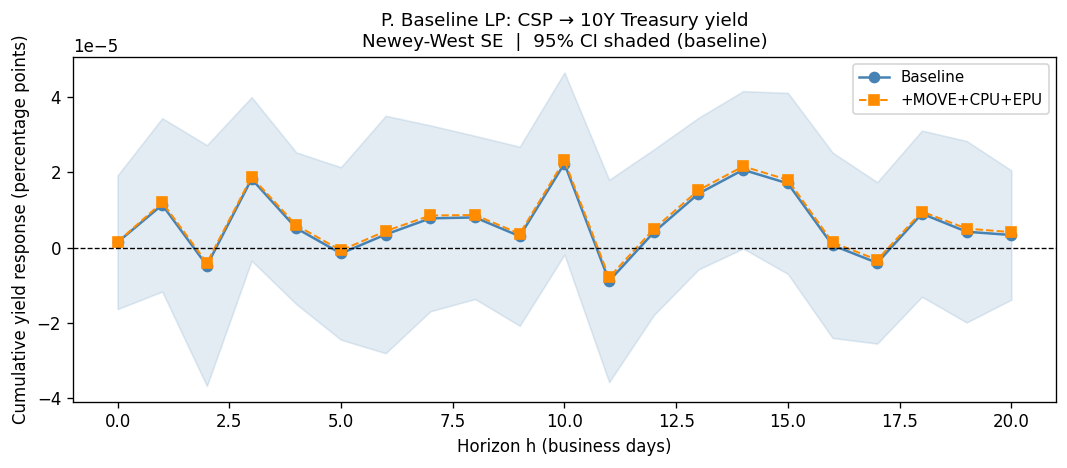

In [24]:
# Plot
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lp_baseline["h"], lp_baseline["beta"],
        "o-", lw=1.5, color="steelblue", label="Baseline")
ax.fill_between(lp_baseline["h"],
                lp_baseline["ci_lo"], lp_baseline["ci_hi"],
                alpha=0.15, color="steelblue")
ax.plot(lp_full["h"], lp_full["beta"],
        "s--", lw=1.2, color="darkorange", label="+MOVE+CPU+EPU")
ax.axhline(0, color="black", lw=0.8, linestyle="--")
ax.set_xlabel("Horizon h (business days)")
ax.set_ylabel("Cumulative yield response (percentage points)")
ax.set_title(
    "P. Baseline LP: CSP → 10Y Treasury yield\n"
    "Newey-West SE  |  95% CI shaded (baseline)",
    fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "LP_baseline_10Y.png", dpi=150, bbox_inches="tight")
plt.show()

### Long-horizon LP on SSI

In [25]:
long_horizons = [22, 63, 126, 252]
long_controls = [c for c in ["move", "cpu", "epu"] if c in panel_10y.columns]
rows_Q        = []

for h in long_horizons:
    work = panel_10y.copy()
    work["dy"] = work["y_10Y"].shift(-h) - work["y_10Y"].shift(1)
    reg_cols   = ["SSI", "SSI_lag1"] + long_controls
    work       = work[["dy"] + reg_cols].dropna()

    if len(work) < 30:
        rows_Q.append({
            "horizon": h, "n": len(work),
            "theta_SSI": np.nan, "se_NW": np.nan,
            "t": np.nan, "p": np.nan, "note": "insufficient obs"})
        continue

    y   = work["dy"].values
    X   = sm.add_constant(work[reg_cols].values)
    res = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": h + 1, "use_correction": True})

    rows_Q.append({
        "horizon":   h,
        "n":         int(res.nobs),
        "theta_SSI": round(float(res.params[1]), 4),
        "se_NW":     round(float(res.bse[1]),    4),
        "t":         round(float(res.tvalues[1]),4),
        "p":         round(float(res.pvalues[1]),4),
        "note":      "",
    })

lp_long = pd.DataFrame(rows_Q)
print("── Long-horizon SSI LP (10Y yield) ──")
display(lp_long)
print("\nNote: SSI is slow-moving and persistent.")
print("Negative theta_SSI consistent with flight-to-safety at long horizons.")

── Long-horizon SSI LP (10Y yield) ──


,horizon,n,theta_SSI,se_NW,t,p,note
0,22,4405,0.043000,0.061400,0.700000,0.484000,
1,63,4364,-0.022400,0.057300,-0.391100,0.695700,
2,126,4301,0.055200,0.048300,1.143300,0.252900,
3,252,4175,0.010100,0.051500,0.196400,0.844300,



Note: SSI is slow-moving and persistent.
Negative theta_SSI consistent with flight-to-safety at long horizons.


### Term structure LP across 2Y, 5Y, 10Y, 30Y

In [26]:
# Guards
for _name in ("yields_by_mat", "panel_base", "available_mats", "SPECS_AVAILABLE",
              "H", "local_projection"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

print("Running term structure local projections...")
results = {mat: {} for mat in available_mats}

for mat in available_mats:
    if mat not in yields_by_mat:
        print(f"  ⚠ {mat}: not in yields_by_mat, skipping")
        continue

    # yields_by_mat columns are ["date", "value"] — not "yield"
    y_mat = yields_by_mat[mat].rename(columns={"value": f"y_{mat}"})
    if f"y_{mat}" not in y_mat.columns:
        raise RuntimeError(
            f"Rename failed for {mat} — expected 'value' column not found. "
            f"Actual columns: {list(yields_by_mat[mat].columns)}"
        )

    panel = (panel_base
        .merge(y_mat, on="date", how="inner")
        .sort_values("date")
        .reset_index(drop=True))

    if panel.empty:
        print(f"  ⚠ {mat}: panel empty after merge, skipping")
        continue

    print(f"\n  {mat} ({len(panel):,} obs)")

    for spec_name, extra_controls in SPECS_AVAILABLE.items():
        rows = []
        for h in range(H + 1):
            res      = local_projection(panel, f"y_{mat}", h, extra_controls)
            res["h"] = h
            rows.append(res)

        lp_df          = pd.DataFrame(rows)
        lp_df["ci_lo"] = lp_df["beta"] - 1.96 * lp_df["se"]
        lp_df["ci_hi"] = lp_df["beta"] + 1.96 * lp_df["se"]
        lp_df["mat"]   = mat
        lp_df["spec"]  = spec_name
        results[mat][spec_name] = lp_df

        sig = (lp_df["pval"] < 0.05).sum()
        print(f"    {spec_name:<20s} {sig}/{H+1} horizons significant")

print("\n✓ Term structure LP complete")

Running term structure local projections...

  2Y (4,428 obs)
    baseline             0/21 horizons significant
    +MOVE                0/21 horizons significant
    +CPU                 0/21 horizons significant
    +EPU                 0/21 horizons significant
    +MOVE+CPU            0/21 horizons significant
    +MOVE+EPU            0/21 horizons significant
    +MOVE+CPU+EPU        0/21 horizons significant

  5Y (4,428 obs)
    baseline             1/21 horizons significant
    +MOVE                1/21 horizons significant
    +CPU                 1/21 horizons significant
    +EPU                 1/21 horizons significant
    +MOVE+CPU            1/21 horizons significant
    +MOVE+EPU            1/21 horizons significant
    +MOVE+CPU+EPU        1/21 horizons significant

  10Y (4,428 obs)
    baseline             0/21 horizons significant
    +MOVE                1/21 horizons significant
    +CPU                 0/21 horizons significant
    +EPU                 0/21 hori

### IRF plots

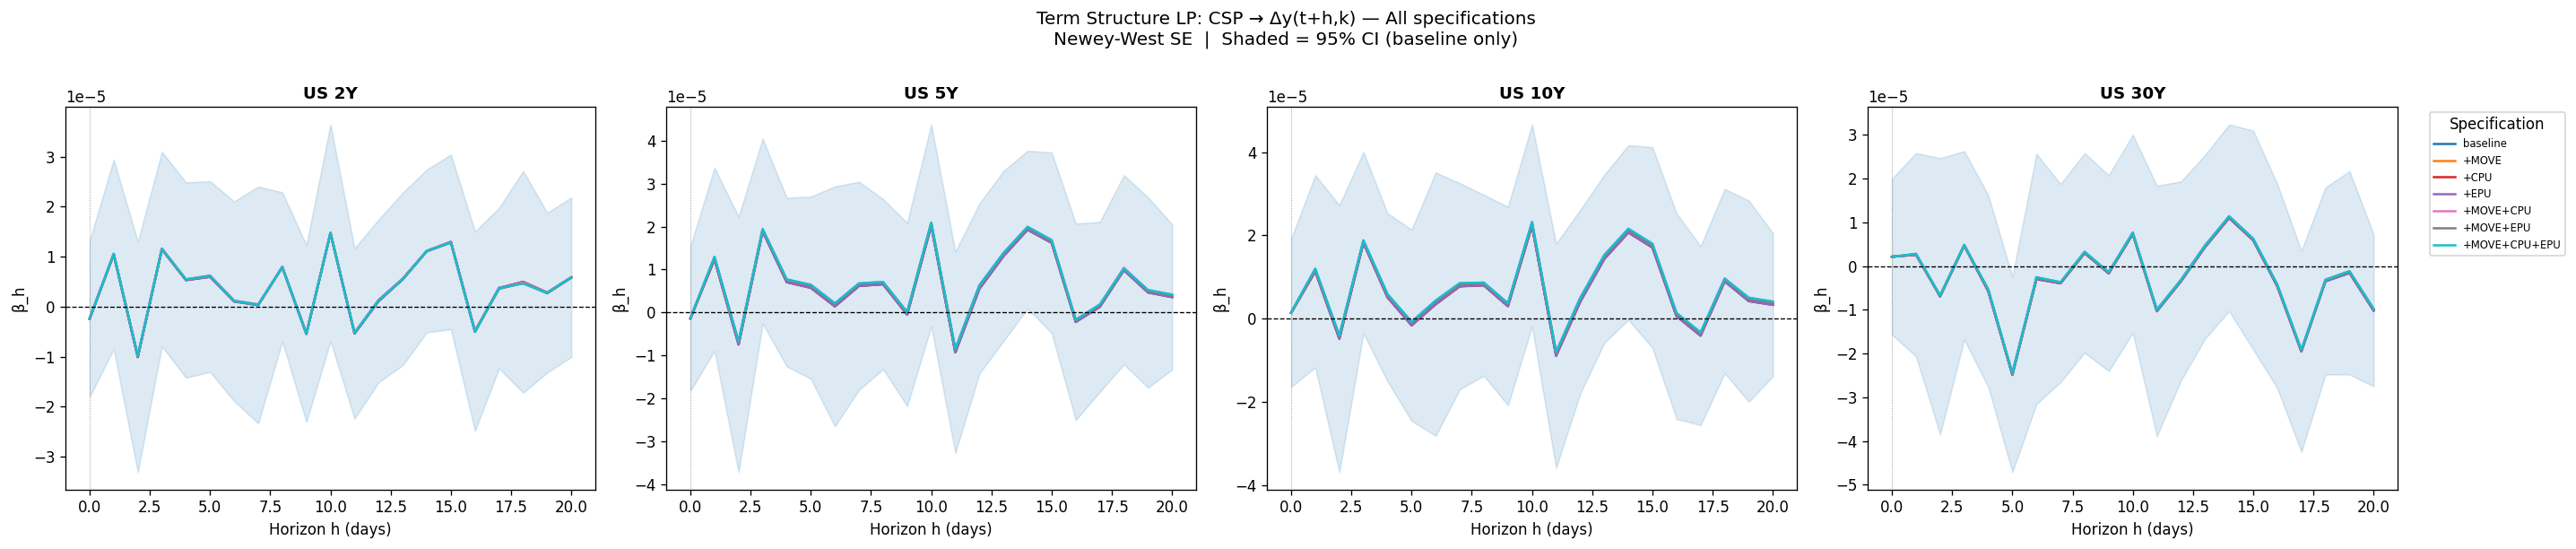

In [27]:
spec_colors = plt.cm.tab10(np.linspace(0, 0.9, len(SPECS_AVAILABLE)))

fig, axes = plt.subplots(1, len(available_mats),
                          figsize=(6 * len(available_mats), 5),
                          sharey=False)
axes = np.array(axes).flatten() if len(available_mats) > 1 else [axes]

for ax, mat in zip(axes, available_mats):
    for (spec_name, _), color in zip(SPECS_AVAILABLE.items(), spec_colors):
        lp_df = results[mat][spec_name]
        ax.plot(lp_df["h"], lp_df["beta"],
                linewidth=1.5, color=color, label=spec_name)
        if spec_name == "baseline":
            ax.fill_between(lp_df["h"], lp_df["ci_lo"], lp_df["ci_hi"],
                            alpha=0.15, color=color)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.axvline(0, color="grey",  linewidth=0.5, linestyle=":")
    ax.set_title(f"US {mat}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Horizon h (days)")
    ax.set_ylabel("β_h")

axes[-1].legend(title="Specification", fontsize=7,
                bbox_to_anchor=(1.05, 1), loc="upper left")
fig.suptitle(
    "Term Structure LP: CSP → Δy(t+h,k) — All specifications\n"
    "Newey-West SE  |  Shaded = 95% CI (baseline only)",
    fontsize=12, y=1.01)
fig.tight_layout()
fig.savefig(figdir / "LP_IRF_all_specs.png", dpi=150, bbox_inches="tight")
plt.show()

### Response surface heatmaps

all specifications

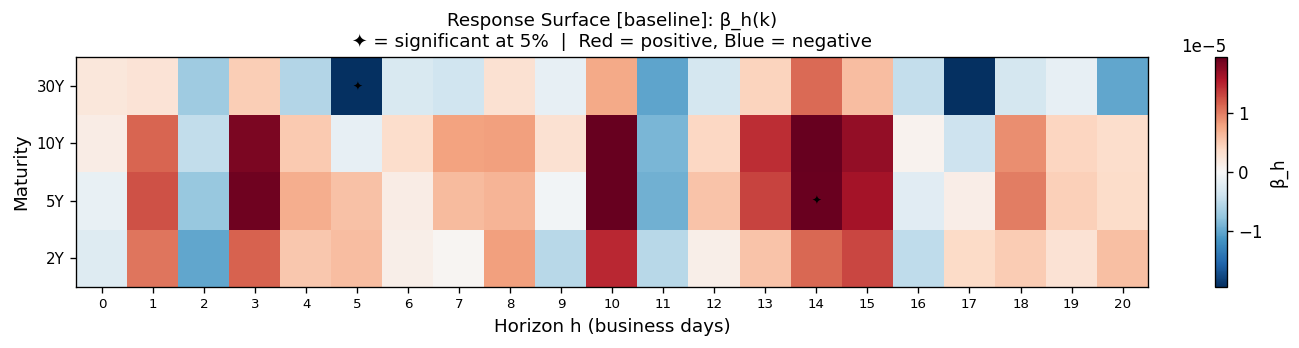

✓ Saved: LP_surface_baseline.png


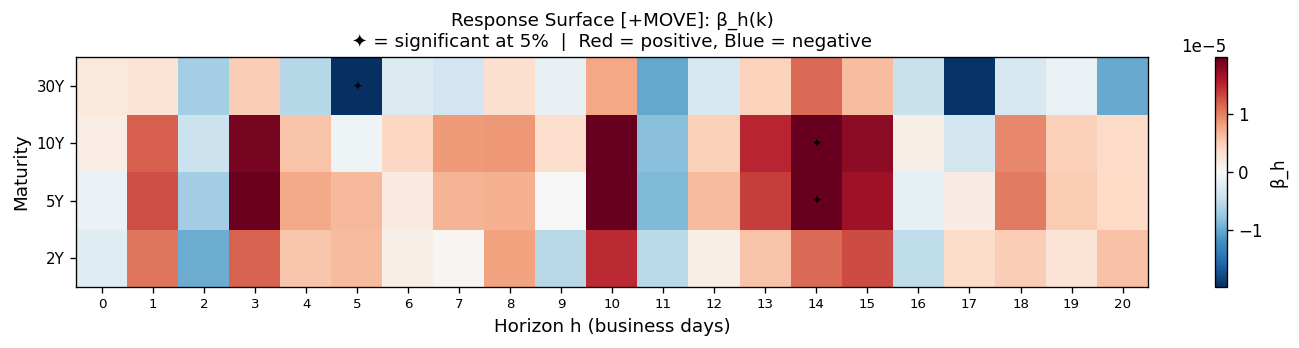

✓ Saved: LP_surface_MOVE.png


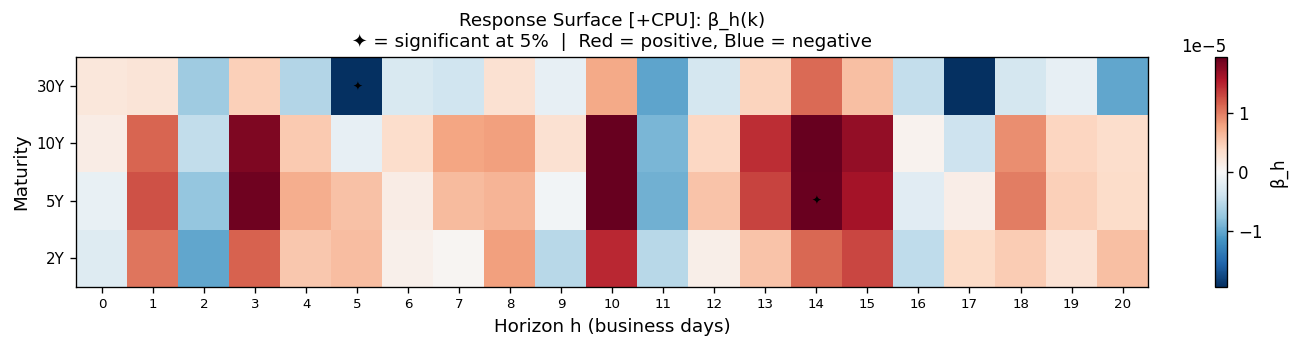

✓ Saved: LP_surface_CPU.png


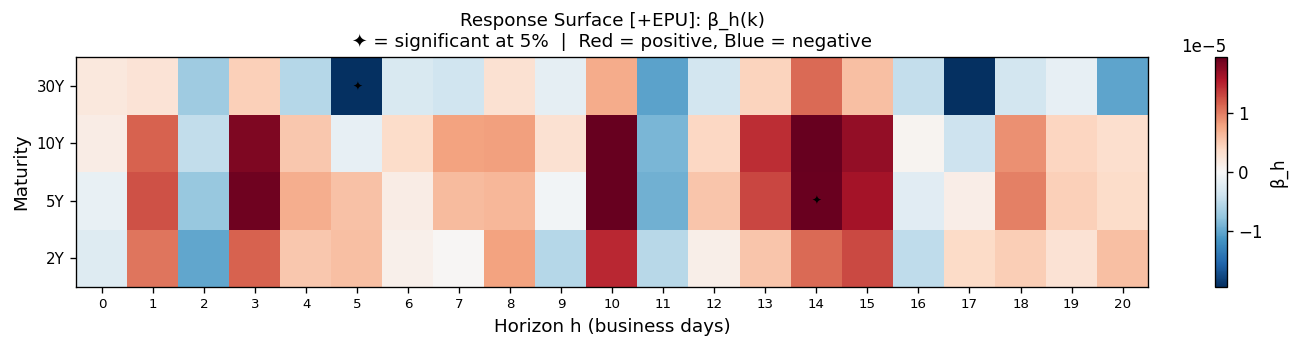

✓ Saved: LP_surface_EPU.png


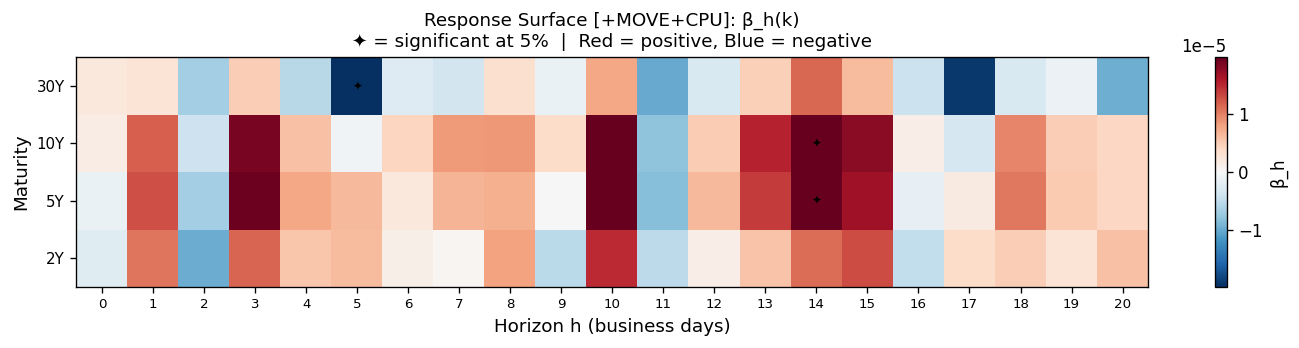

✓ Saved: LP_surface_MOVECPU.png


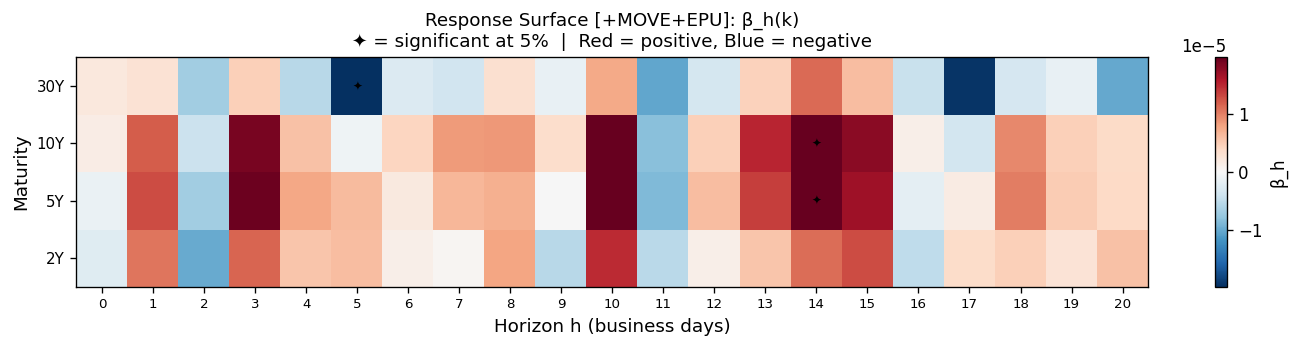

✓ Saved: LP_surface_MOVEEPU.png


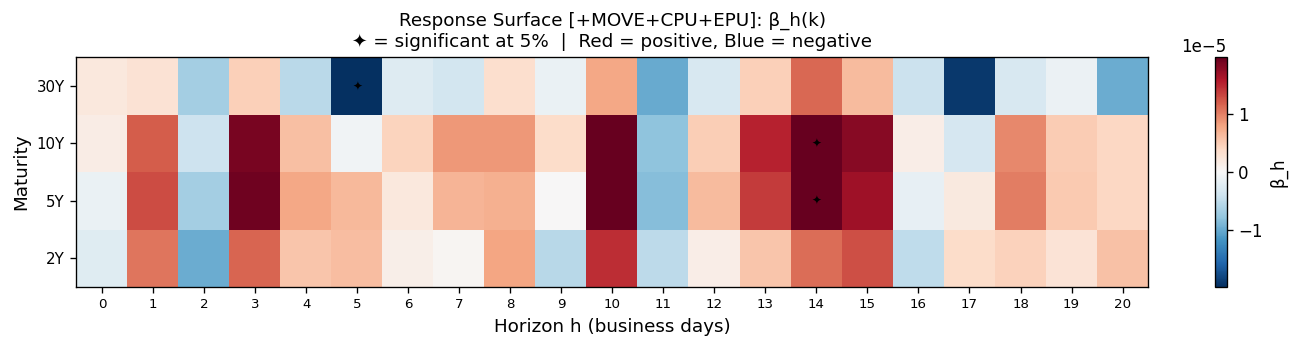

✓ Saved: LP_surface_MOVECPUEPU.png


In [28]:
for spec_name in SPECS_AVAILABLE.keys():

    beta_matrix = np.full((len(available_mats), H + 1), np.nan)
    for i, mat in enumerate(available_mats):
        beta_matrix[i, :] = results[mat][spec_name]["beta"].values

    fig, ax = plt.subplots(figsize=(12, 3))
    vmax = np.nanpercentile(np.abs(beta_matrix), 95)
    if vmax == 0 or np.isnan(vmax):
        vmax = 1e-6
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    im   = ax.imshow(beta_matrix, aspect="auto", cmap="RdBu_r",
                     norm=norm, origin="lower")

    ax.set_xticks(range(H + 1))
    ax.set_xticklabels(range(H + 1), fontsize=8)
    ax.set_yticks(range(len(available_mats)))
    ax.set_yticklabels(available_mats, fontsize=9)
    ax.set_xlabel("Horizon h (business days)", fontsize=11)
    ax.set_ylabel("Maturity", fontsize=11)
    ax.set_title(
        f"Response Surface [{spec_name}]: β_h(k)\n"
        "✦ = significant at 5%  |  Red = positive, Blue = negative",
        fontsize=11)

    for i, mat in enumerate(available_mats):
        for h in range(H + 1):
            pval = results[mat][spec_name].loc[
                results[mat][spec_name]["h"] == h, "pval"].values
            if len(pval) > 0 and not np.isnan(pval[0]) and pval[0] < 0.05:
                ax.text(h, i, "✦", ha="center", va="center",
                        fontsize=7, color="black")

    plt.colorbar(im, ax=ax, label="β_h")
    fig.tight_layout()
    fig.savefig(
        figdir / f"LP_surface_{spec_name.replace('+', '').replace(' ', '_')}.png",
        dpi=150, bbox_inches="tight")
    plt.show()
    print(f"✓ Saved: LP_surface_{spec_name.replace('+', '').replace(' ', '_')}.png")

### Maturity gradient — one panel per specification

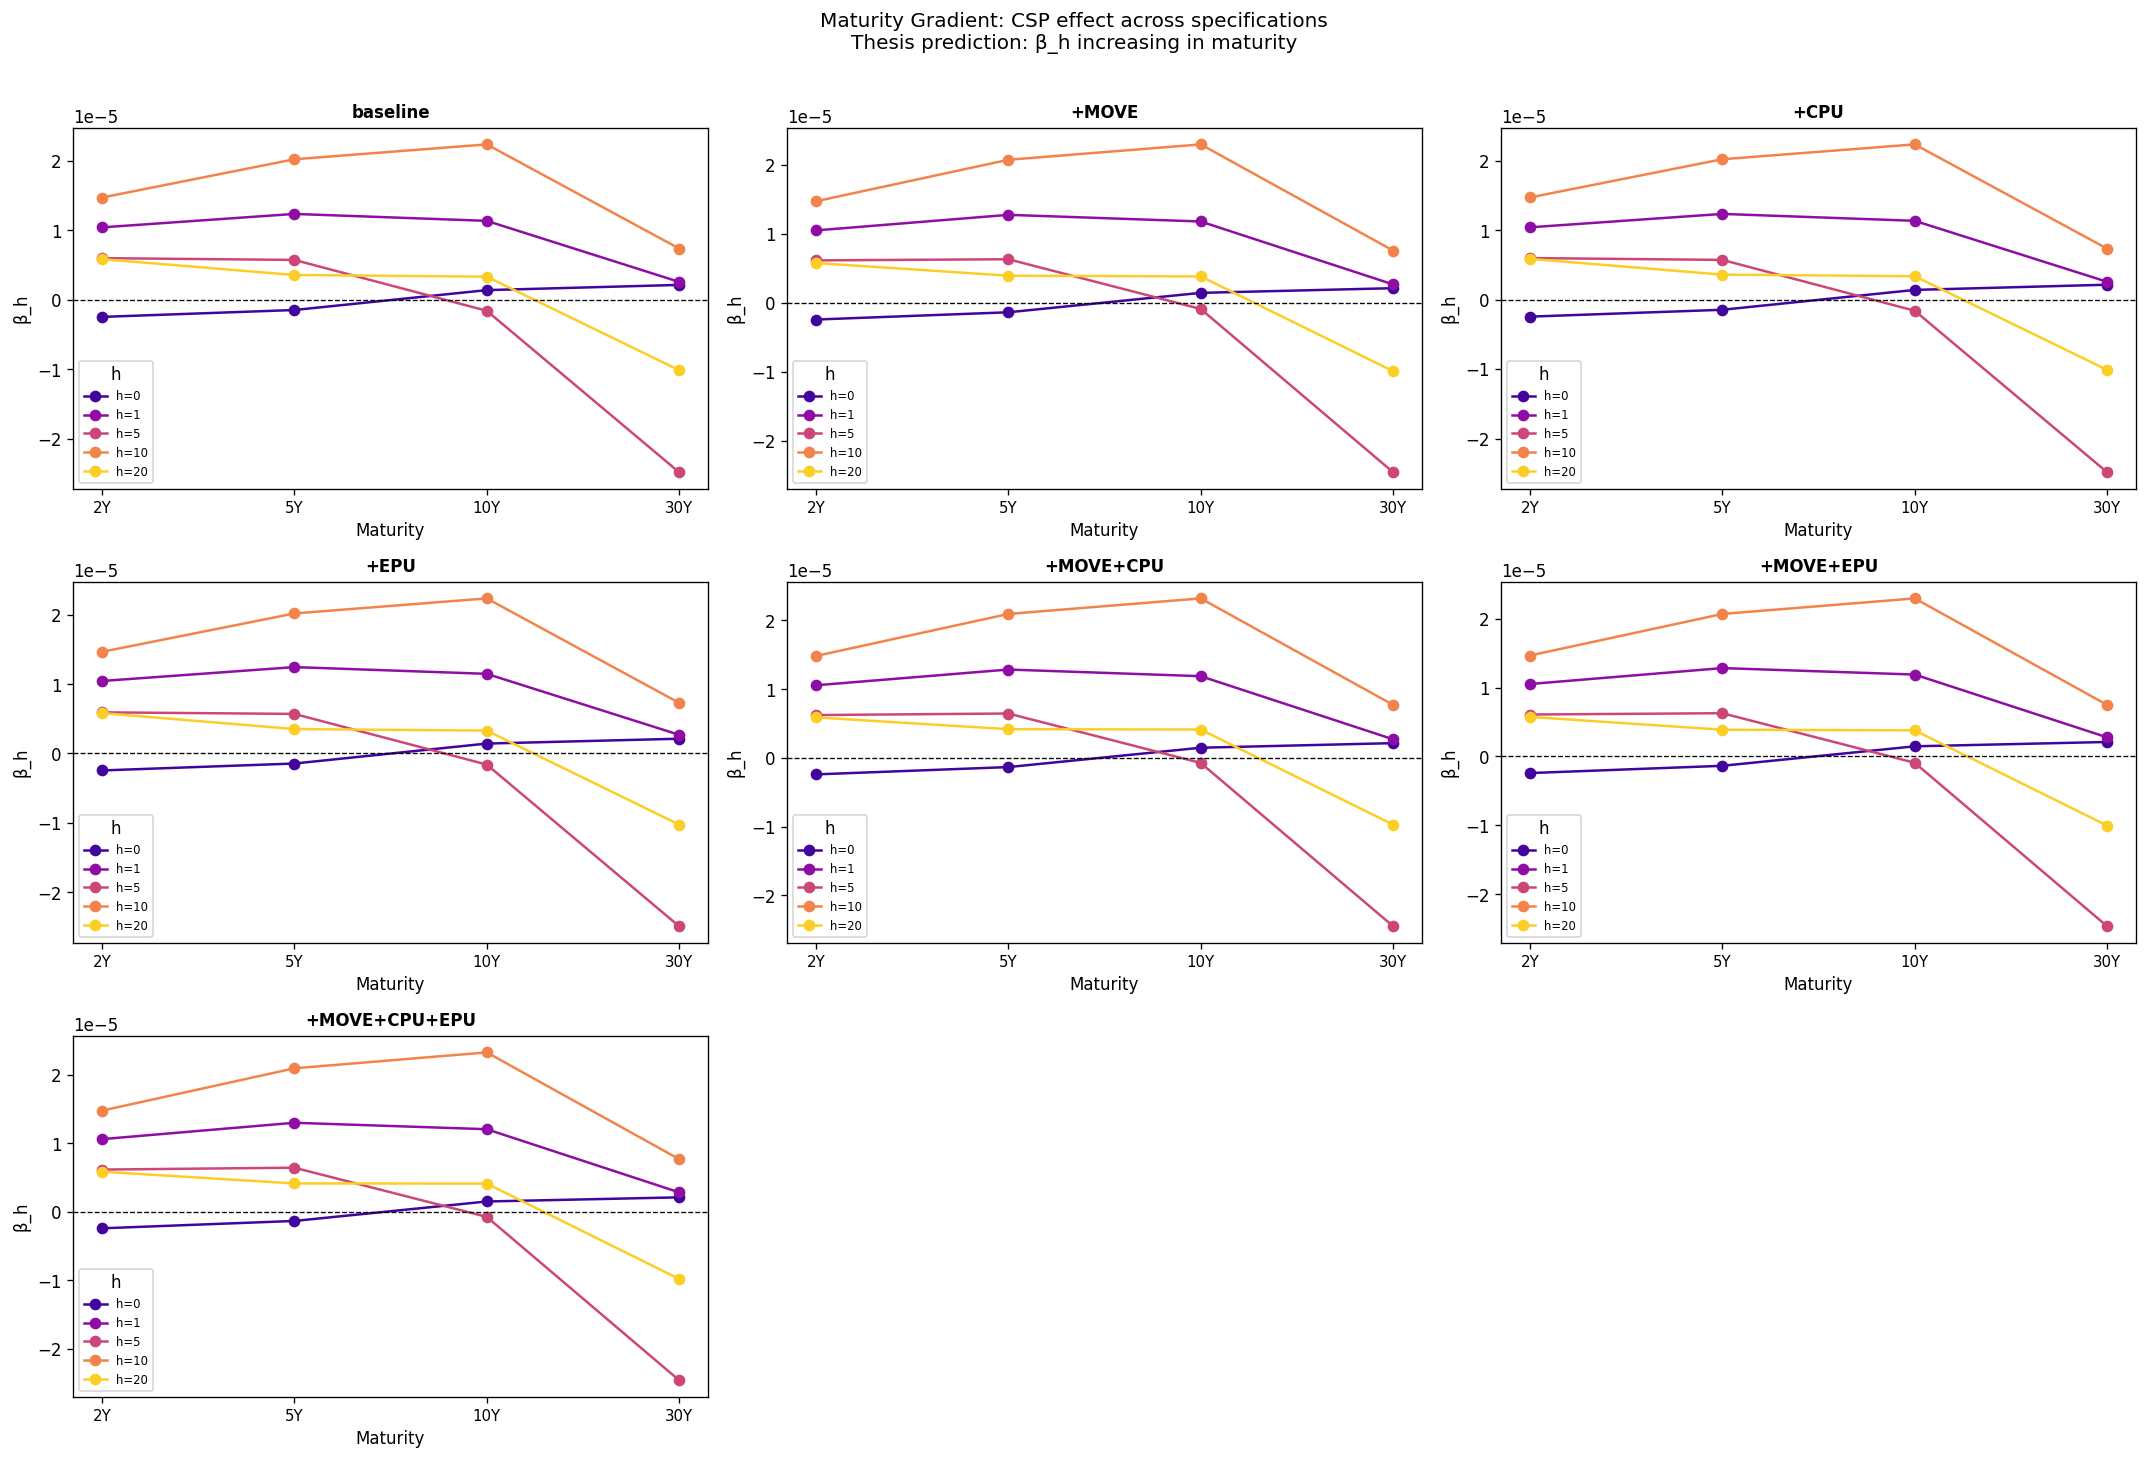

In [29]:
# =============================================================================
# Thesis prediction: β_h increasing in maturity
# =============================================================================

selected_horizons = [h for h in [0, 1, 5, 10, 20] if h <= H]
h_colors          = plt.cm.plasma(np.linspace(0.1, 0.9, len(selected_horizons)))

n_specs = len(SPECS_AVAILABLE)
ncols   = min(3, n_specs)
nrows   = int(np.ceil(n_specs / ncols))

fig, axes = plt.subplots(nrows, ncols,
                          figsize=(6 * ncols, 4 * nrows),
                          sharey=False)
axes = np.array(axes).flatten()

for ax, (spec_name, _) in zip(axes, SPECS_AVAILABLE.items()):
    for h, hcol in zip(selected_horizons, h_colors):
        betas = [results[mat][spec_name]
                 .loc[results[mat][spec_name]["h"] == h, "beta"]
                 .values[0]
                 for mat in available_mats]
        ax.plot(range(len(available_mats)), betas,
                marker="o", linewidth=1.5, color=hcol, label=f"h={h}")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(range(len(available_mats)))
    ax.set_xticklabels(available_mats, fontsize=9)
    ax.set_xlabel("Maturity")
    ax.set_ylabel("β_h")
    ax.set_title(spec_name, fontsize=10, fontweight="bold")
    ax.legend(title="h", fontsize=7)

for ax in axes[n_specs:]:
    ax.set_visible(False)

fig.suptitle(
    "Maturity Gradient: CSP effect across specifications\n"
    "Thesis prediction: β_h increasing in maturity",
    fontsize=12, y=1.01)
fig.tight_layout()
fig.savefig(figdir / "LP_maturity_gradient_all_specs.png",
            dpi=150, bbox_inches="tight")
plt.show()

### Beta summary table 

In [30]:
rows = []
for mat in available_mats:
    for spec_name in SPECS_AVAILABLE:
        lp_df = results[mat][spec_name].reset_index(drop=True)
        b     = lp_df.iloc[0]["beta"]
        p     = lp_df.iloc[0]["pval"]
        rows.append({
            "maturity": mat,
            "spec":     spec_name,
            "beta_0":   b,
            "pval":     p,
            "sig":      "✓" if (not np.isnan(p) and p < 0.05) else "",
        })

summary_df = pd.DataFrame(rows)

print("β_0 coefficients (scientific notation):")
beta_pivot = summary_df.pivot(
    index="spec", columns="maturity", values="beta_0")
print(beta_pivot.to_string(float_format=lambda x: f"{x:.3e}"))

print("\np-values:")
pval_pivot = summary_df.pivot(
    index="spec", columns="maturity", values="pval")
print(pval_pivot.to_string(float_format=lambda x: f"{x:.4f}"))

print("\nSignificant at 5% (✓ = yes):")
sig_pivot = summary_df.pivot(
    index="spec", columns="maturity", values="sig").fillna("")
print(sig_pivot.to_string())

# 30Y nobs diagnostic
print("\n── 30Y nobs across horizons (baseline) ──")
nobs_vals = results["30Y"]["baseline"]["nobs"].values
nobs_drop = nobs_vals[0] - nobs_vals[-1]
print(results["30Y"]["baseline"][
    ["h", "beta", "se", "pval", "nobs"]].to_string(index=False))
print(f"\nObservation count: h=0 → {nobs_vals[0]:,},  h={H} → {nobs_vals[-1]:,}")
print(f"Drop across horizons: {nobs_drop:,}")
if nobs_drop > 50:
    print("⚠ Meaningful nobs loss — long-horizon inversion may be boundary artefact")
else:
    print("✓ nobs stable — 30Y inversion is genuine")

β_0 coefficients (scientific notation):
maturity            10Y         2Y       30Y         5Y
spec                                                   
+CPU          1.405e-06 -2.444e-06 2.156e-06 -1.455e-06
+EPU          1.431e-06 -2.446e-06 2.128e-06 -1.449e-06
+MOVE         1.462e-06 -2.406e-06 2.139e-06 -1.353e-06
+MOVE+CPU     1.473e-06 -2.404e-06 2.140e-06 -1.341e-06
+MOVE+CPU+EPU 1.502e-06 -2.406e-06 2.107e-06 -1.334e-06
+MOVE+EPU     1.480e-06 -2.409e-06 2.109e-06 -1.352e-06
baseline      1.410e-06 -2.444e-06 2.160e-06 -1.451e-06

p-values:
maturity         10Y     2Y    30Y     5Y
spec                                     
+CPU          0.8770 0.7591 0.8127 0.8656
+EPU          0.8748 0.7587 0.8151 0.8662
+MOVE         0.8722 0.7630 0.8141 0.8751
+MOVE+CPU     0.8712 0.7632 0.8141 0.8762
+MOVE+CPU+EPU 0.8687 0.7629 0.8168 0.8769
+MOVE+EPU     0.8706 0.7627 0.8166 0.8753
baseline      0.8766 0.7591 0.8124 0.8659

Significant at 5% (✓ = yes):
maturity      10Y 2Y 30Y 5Y
spec     

### Yield spread LP — 30Y minus 2Y

Spread panel : 3,917 obs
Mean spread  : 0.0000
Std spread   : 0.0005

Significant horizons: 1/21

   h         beta           se        p
   0   6.9263e-06   9.1901e-06   0.4510 
   1  -3.7136e-06   9.9701e-06   0.7095 
   2   5.9002e-06   1.1044e-05   0.5932 
   3  -3.6674e-06   1.0243e-05   0.7203 
   4  -7.4384e-06   1.1257e-05   0.5087 
   5  -2.7302e-05   1.0533e-05   0.0095 ***
   6  -1.3298e-06   1.0739e-05   0.9015 
   7   7.4863e-07   9.9773e-06   0.9402 
   8  -2.6353e-06   1.0222e-05   0.7965 
   9   7.1984e-06   1.0647e-05   0.4990 
  10  -4.0862e-06   9.3716e-06   0.6628 
  11   1.1267e-07   1.2773e-05   0.9930 
  12  -5.6175e-07   9.6497e-06   0.9536 
  13   4.1655e-06   9.6273e-06   0.6652 
  14   4.3450e-06   8.6009e-06   0.6134 
  15  -4.5010e-06   1.1068e-05   0.6843 
  16   4.4573e-06   9.4843e-06   0.6384 
  17  -1.8053e-05   9.6110e-06   0.0603 *
  18  -3.9716e-06   9.4296e-06   0.6736 
  19  -2.6878e-06   8.7593e-06   0.7590 
  20  -1.2480e-05   8.9240e-06   0.162

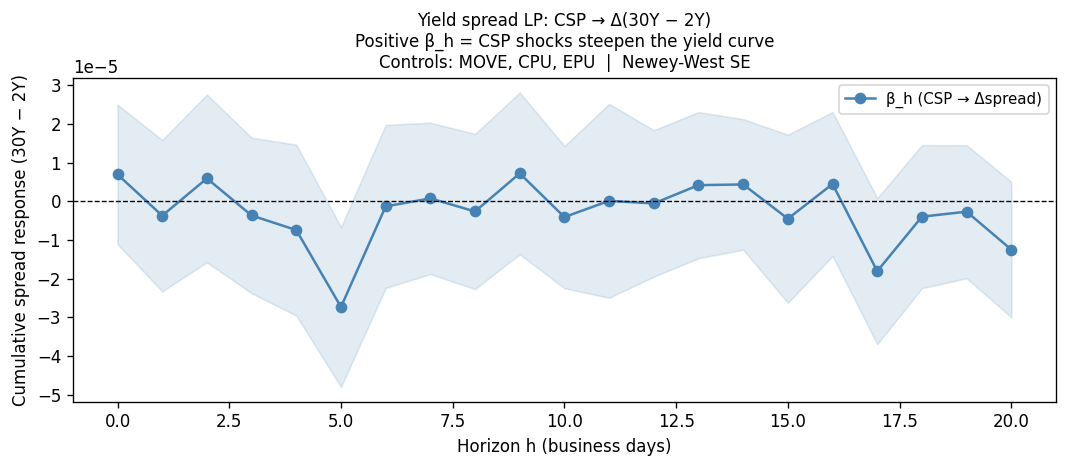

In [31]:
# =============================================================================
# Direct test of maturity gradient prediction
# A positive β_h means CSP shocks steepen the yield curve
# =============================================================================

for _name in ("yields_by_mat", "panel_base", "H", "NW_LAGS"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

if "2Y" not in yields_by_mat or "30Y" not in yields_by_mat:
    print("⚠ Both 2Y and 30Y yields required — skipping spread regression")
else:
    # yields_by_mat columns are ["date", "value"] — not "yield"
    y2  = yields_by_mat["2Y"].rename(columns={"value": "y_2Y"})
    y30 = yields_by_mat["30Y"].rename(columns={"value": "y_30Y"})

    if "y_2Y" not in y2.columns or "y_30Y" not in y30.columns:
        raise RuntimeError(
            f"Rename failed. 2Y columns: {list(yields_by_mat['2Y'].columns)}, "
            f"30Y columns: {list(yields_by_mat['30Y'].columns)}"
        )

    spread_panel = (panel_base
        .merge(y2,  on="date", how="inner")
        .merge(y30, on="date", how="inner")
        .sort_values("date")
        .reset_index(drop=True))
    spread_panel["spread"] = spread_panel["y_30Y"] - spread_panel["y_2Y"]

    if spread_panel.empty:
        raise RuntimeError("spread_panel is empty after merge — check date overlap.")

    print(f"Spread panel : {len(spread_panel):,} obs")
    print(f"Mean spread  : {spread_panel['spread'].mean():.4f}")
    print(f"Std spread   : {spread_panel['spread'].std():.4f}")

    spread_controls = [c for c in ["move", "cpu", "epu"]
                       if c in spread_panel.columns]
    rows_spread     = []

    for h in range(H + 1):
        work = spread_panel.copy()
        if h == 0:
            work["dy"] = work["spread"].diff()
        else:
            work["dy"] = work["spread"].shift(-h) - work["spread"].shift(1)

        reg_cols = ["CSP", "SSI_lag1"] + spread_controls
        work     = work[["dy"] + reg_cols].dropna()

        if len(work) < 30:
            rows_spread.append({"h": h, "beta": np.nan,
                                "se": np.nan, "pval": np.nan,
                                "nobs": len(work)})
            continue

        y   = work["dy"].values
        X   = sm.add_constant(work[reg_cols].values)
        res = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": NW_LAGS, "use_correction": True})
        rows_spread.append({
            "h":    h,
            "beta": float(res.params[1]),
            "se":   float(res.bse[1]),
            "pval": float(res.pvalues[1]),
            "nobs": int(res.nobs),
        })

    spread_lp         = pd.DataFrame(rows_spread)
    spread_lp["ci_lo"] = spread_lp["beta"] - 1.96 * spread_lp["se"]
    spread_lp["ci_hi"] = spread_lp["beta"] + 1.96 * spread_lp["se"]

    print(f"\nSignificant horizons: {(spread_lp['pval'] < 0.05).sum()}/{H+1}")
    print(f"\n{'h':>4} {'beta':>12} {'se':>12} {'p':>8}")
    for _, r in spread_lp.iterrows():
        sig = ("***" if r["pval"] < 0.01 else
               "**"  if r["pval"] < 0.05 else
               "*"   if r["pval"] < 0.10 else "")
        print(f"{int(r['h']):>4} {r['beta']:>12.4e} {r['se']:>12.4e} "
              f"{r['pval']:>8.4f} {sig}")

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(spread_lp["h"], spread_lp["beta"],
            "o-", lw=1.5, color="steelblue",
            label="β_h (CSP → Δspread)")
    ax.fill_between(spread_lp["h"],
                    spread_lp["ci_lo"], spread_lp["ci_hi"],
                    alpha=0.15, color="steelblue")
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.set_xlabel("Horizon h (business days)")
    ax.set_ylabel("Cumulative spread response (30Y − 2Y)")
    ax.set_title(
        "Yield spread LP: CSP → Δ(30Y − 2Y)\n"
        "Positive β_h = CSP shocks steepen the yield curve\n"
        "Controls: MOVE, CPU, EPU  |  Newey-West SE",
        fontsize=10)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(figdir / "LP_spread_30Y_2Y.png", dpi=150, bbox_inches="tight")
    plt.show()

### Temporal aggregation robustness

In [32]:
for _name in ("pcra", "yields_by_mat", "available_mats", "panel_base",
              "move_clean", "cpu_daily", "epu_df"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

def aggregate_pcra(df, freq):
    out = (df.set_index("date")
             .resample(freq)
             .agg(
                 CSP_mean = ("CSP", "mean"),
                 CSP_max  = ("CSP", lambda x: x.abs().max()),
                 SSI_last = ("SSI", "last"),
                 n_days   = ("CSP", "count"))
             .dropna(subset=["CSP_mean"])
             .reset_index())
    out["SSI_lag1"] = out["SSI_last"].shift(1)
    return out.dropna(subset=["SSI_lag1"]).reset_index(drop=True)

def aggregate_yield(yld_df, freq):
    # yields_by_mat columns are ["date", "value"] — not "yield"
    if "value" not in yld_df.columns:
        raise RuntimeError(
            f"Expected 'value' column not found. Actual columns: {list(yld_df.columns)}"
        )
    return (yld_df.set_index("date")["value"]
                  .resample(freq).last()
                  .dropna()
                  .reset_index())

def aggregate_control(df, col, freq):
    if col not in df.columns:
        raise RuntimeError(
            f"Expected '{col}' column not found. Actual columns: {list(df.columns)}"
        )
    return (df.set_index("date")[col]
               .resample(freq).mean()
               .dropna()
               .reset_index())

def build_agg_panel(pcra_agg, freq, mats, extra_controls):
    panels = {}
    for mat in mats:
        if mat not in yields_by_mat:
            print(f"    ⚠ {mat}: not in yields_by_mat, skipping")
            continue
        y_agg         = aggregate_yield(yields_by_mat[mat], freq)
        y_agg.columns = ["date", f"y_{mat}"]
        p             = pcra_agg.merge(y_agg, on="date", how="inner")
        if "move" in extra_controls and move_clean is not None:
            p = p.merge(aggregate_control(move_clean, "move", freq),
                        on="date", how="left")
        if "cpu" in extra_controls and cpu_daily is not None:
            p = p.merge(aggregate_control(cpu_daily, "cpu",  freq),
                        on="date", how="left")
        if "epu" in extra_controls:
            p = p.merge(aggregate_control(epu_df,    "epu",  freq),
                        on="date", how="left")
        panels[mat] = p.sort_values("date").reset_index(drop=True)
    return panels

def lp_agg(panel, dep_col, h, extra_controls, nw_lags):
    work = panel.copy()
    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)
    reg_cols = ["CSP_mean", "SSI_lag1"] + extra_controls
    work     = work[["dy"] + reg_cols].dropna()
    if len(work) < 20:
        return {"beta": np.nan, "se": np.nan,
                "pval": np.nan, "nobs": len(work)}
    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)
    try:
        res = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": nw_lags, "use_correction": True})
        return {
            "beta":  float(res.params[1]),
            "se":    float(res.bse[1]),
            "pval":  float(res.pvalues[1]),
            "nobs":  int(res.nobs),
        }
    except Exception:
        return {"beta": np.nan, "se": np.nan,
                "pval": np.nan, "nobs": 0}

# ── Aggregate PCRA ────────────────────────────────────────────────────────────
pcra_weekly  = aggregate_pcra(pcra, "W-FRI")
pcra_monthly = aggregate_pcra(pcra, "ME")
pcra_qtrly   = aggregate_pcra(pcra, "QE")

print(f"Weekly obs    : {len(pcra_weekly):,}")
print(f"Monthly obs   : {len(pcra_monthly):,}")
print(f"Quarterly obs : {len(pcra_qtrly):,}")

FREQ_CONFIG = {
    "weekly":    {"pcra": pcra_weekly,  "freq": "W-FRI",
                  "horizons": list(range(9)),  "nw": 4},
    "monthly":   {"pcra": pcra_monthly, "freq": "ME",
                  "horizons": list(range(7)),  "nw": 3},
    "quarterly": {"pcra": pcra_qtrly,   "freq": "QE",
                  "horizons": list(range(5)),  "nw": 2},
}

all_agg      = {}
agg_controls = [c for c in ["move", "cpu", "epu"]
                if c in panel_base.columns]

for freq_name, cfg in FREQ_CONFIG.items():
    print(f"\n{'='*50}\n{freq_name.upper()}\n{'='*50}")
    panels   = build_agg_panel(
        cfg["pcra"], cfg["freq"], available_mats, agg_controls)
    freq_res = {}

    for mat in available_mats:
        if mat not in panels:
            print(f"  ⚠ {mat}: no panel built, skipping")
            continue
        rows = []
        for h in cfg["horizons"]:
            r      = lp_agg(panels[mat], f"y_{mat}", h,
                            agg_controls, cfg["nw"])
            r["h"] = h
            rows.append(r)
        lp            = pd.DataFrame(rows)
        lp["ci_lo"]   = lp["beta"] - 1.96 * lp["se"]
        lp["ci_hi"]   = lp["beta"] + 1.96 * lp["se"]
        freq_res[mat] = lp
        sig = (lp["pval"] < 0.05).sum()
        print(f"  {mat}: {sig}/{len(cfg['horizons'])} horizons significant "
              f"(n={panels[mat].shape[0]})")

    all_agg[freq_name] = freq_res

Weekly obs    : 889
Monthly obs   : 204
Quarterly obs : 68

WEEKLY
  2Y: 0/9 horizons significant (n=835)
  5Y: 2/9 horizons significant (n=835)
  10Y: 2/9 horizons significant (n=835)
  30Y: 1/9 horizons significant (n=784)

MONTHLY
  2Y: 0/7 horizons significant (n=192)
  5Y: 1/7 horizons significant (n=192)
  10Y: 1/7 horizons significant (n=192)
  30Y: 2/7 horizons significant (n=181)

QUARTERLY
  2Y: 0/5 horizons significant (n=64)
  5Y: 0/5 horizons significant (n=64)
  10Y: 0/5 horizons significant (n=64)
  30Y: 0/5 horizons significant (n=61)


In [33]:
# ── Summary tables ────────────────────────────────────────────────────────────
for freq_name, freq_res in all_agg.items():
    print(f"\n── {freq_name.upper()} — β_h table ──")
    rows = []
    for mat in available_mats:
        lp = freq_res[mat]
        for _, row in lp.iterrows():
            rows.append({
                "maturity": mat,
                "h":        int(row["h"]),
                "beta":     row["beta"],
                "se":       row["se"],
                "pval":     row["pval"],
                "nobs":     row.get("nobs", np.nan),
                "sig":      "✓" if (not np.isnan(row["pval"])
                                    and row["pval"] < 0.05) else "",
            })
    tbl        = pd.DataFrame(rows)
    pivot_beta = tbl.pivot(index="h", columns="maturity", values="beta")
    pivot_pval = tbl.pivot(index="h", columns="maturity", values="pval")
    pivot_sig  = tbl.pivot(index="h", columns="maturity", values="sig").fillna("")
    print("β coefficients:")
    print(pivot_beta.to_string(float_format=lambda x: f"{x:.4e}"))
    print("\np-values:")
    print(pivot_pval.to_string(float_format=lambda x: f"{x:.3f}"))
    print("\nSignificant at 5%:")
    print(pivot_sig.to_string())



── WEEKLY — β_h table ──
β coefficients:
maturity         10Y          2Y         30Y          5Y
h                                                       
0        -1.3507e-05 -5.3820e-05  6.8416e-06 -4.0514e-05
1        -1.2393e-04 -7.9031e-05 -1.1080e-04 -1.2359e-04
2         2.8504e-06 -1.6298e-06  2.6798e-05 -1.0924e-06
3        -2.7410e-05 -7.5404e-06 -3.0429e-05 -3.8669e-05
4        -2.9215e-05 -3.5029e-05 -8.8110e-07 -4.3131e-05
5        -1.1410e-04 -8.0718e-05 -9.1393e-05 -1.1207e-04
6        -4.4608e-05 -8.0041e-05  3.3449e-06 -6.7853e-05
7        -2.1498e-05 -4.8980e-05  2.1521e-05 -4.0832e-05
8        -6.9765e-05 -7.4437e-05 -1.9973e-05 -8.7360e-05

p-values:
maturity   10Y    2Y   30Y    5Y
h                               
0        0.848 0.415 0.917 0.569
1        0.034 0.222 0.032 0.035
2        0.964 0.974 0.651 0.985
3        0.616 0.868 0.577 0.457
4        0.673 0.568 0.988 0.528
5        0.044 0.067 0.084 0.042
6        0.508 0.218 0.954 0.326
7        0.727 0.400 0.

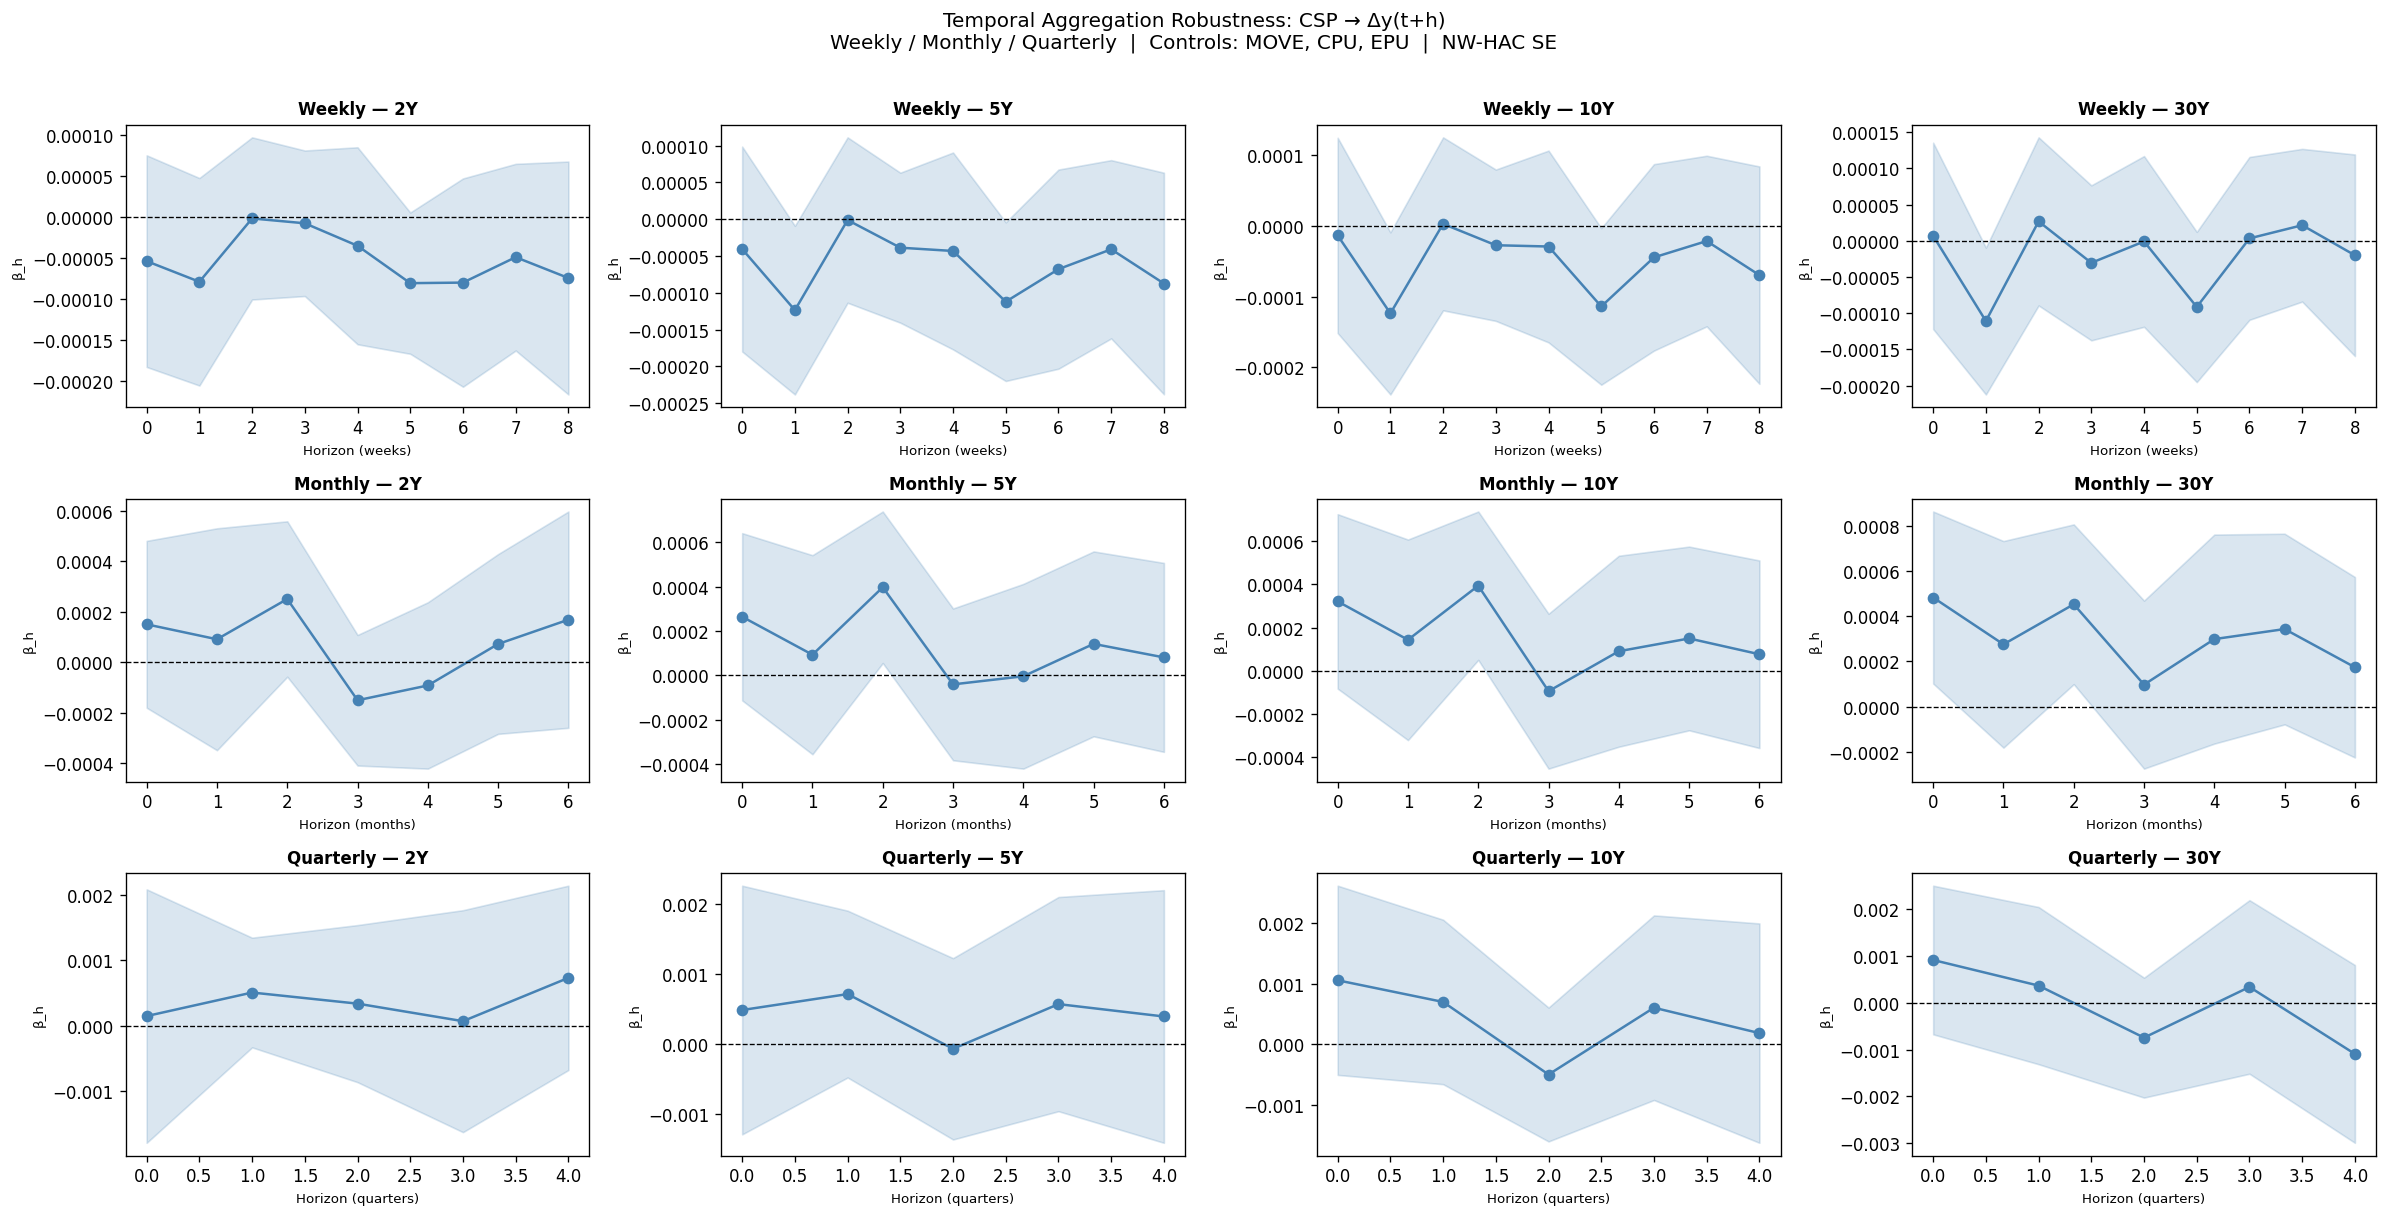


✓ Aggregation robustness complete
  Frequencies : weekly, monthly, quarterly
  Maturities  : ['2Y', '5Y', '10Y', '30Y']
  CSV saved   : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_aggregation_robustness.csv


In [34]:

# ── IRF plots ─────────────────────────────────────────────────────────────────
freq_labels = {"weekly":    "Weekly",
               "monthly":   "Monthly",
               "quarterly": "Quarterly"}
x_labels    = {"weekly":    "Horizon (weeks)",
               "monthly":   "Horizon (months)",
               "quarterly": "Horizon (quarters)"}

fig, axes = plt.subplots(3, len(available_mats),
                          figsize=(5 * len(available_mats), 10),
                          sharey=False)

for row_i, freq_name in enumerate(["weekly", "monthly", "quarterly"]):
    for col_i, mat in enumerate(available_mats):
        ax = axes[row_i, col_i]
        lp = all_agg[freq_name][mat]
        ax.plot(lp["h"], lp["beta"], "o-", lw=1.5, color="steelblue")
        ax.fill_between(lp["h"], lp["ci_lo"], lp["ci_hi"],
                        alpha=0.2, color="steelblue")
        ax.axhline(0, color="black", lw=0.8, linestyle="--")
        ax.set_title(f"{freq_labels[freq_name]} — {mat}",
                     fontsize=10, fontweight="bold")
        ax.set_xlabel(x_labels[freq_name], fontsize=8)
        ax.set_ylabel("β_h", fontsize=8)

fig.suptitle(
    "Temporal Aggregation Robustness: CSP → Δy(t+h)\n"
    "Weekly / Monthly / Quarterly  |  Controls: MOVE, CPU, EPU  |  NW-HAC SE",
    fontsize=12, y=1.01)
fig.tight_layout()
fig.savefig(figdir / "LP_aggregation_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Save ──────────────────────────────────────────────────────────────────────
agg_rows = []
for freq_name, freq_res in all_agg.items():
    for mat, lp in freq_res.items():
        lp          = lp.copy()
        lp["freq"]  = freq_name
        lp["mat"]   = mat
        agg_rows.append(lp)

pd.concat(agg_rows, ignore_index=True).to_csv(
    figdir / "LP_aggregation_robustness.csv", index=False)

print(f"\n✓ Aggregation robustness complete")
print(f"  Frequencies : weekly, monthly, quarterly")
print(f"  Maturities  : {available_mats}")
print(f"  CSV saved   : {figdir / 'LP_aggregation_robustness.csv'}")

### Sub-sample stability

In [35]:
# =============================================================================
# Addresses CUSUM structural break in SSI
# Focus: 10Y yield baseline specification
# =============================================================================

for _name in ("yields_by_mat", "panel_base", "H", "local_projection"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

SPLIT_DATES = {
    "2008–2015": ("2008-01-01", "2015-12-31"),
    "2016–2019": ("2016-01-01", "2019-12-31"),
    "2020–2025": ("2020-01-01", "2025-12-31"),
}

MAT_FOCUS = "10Y"
if MAT_FOCUS not in yields_by_mat:
    raise RuntimeError(
        f"'{MAT_FOCUS}' not in yields_by_mat. Available: {list(yields_by_mat.keys())}"
    )

# yields_by_mat columns are ["date", "value"] — not "yield"
y_mat = yields_by_mat[MAT_FOCUS].rename(columns={"value": f"y_{MAT_FOCUS}"})
if f"y_{MAT_FOCUS}" not in y_mat.columns:
    raise RuntimeError(
        f"Rename failed. Actual columns: {list(yields_by_mat[MAT_FOCUS].columns)}"
    )

full_panel = (panel_base
    .merge(y_mat, on="date", how="inner")
    .sort_values("date")
    .reset_index(drop=True))

if full_panel.empty:
    raise RuntimeError("full_panel is empty after merge — check date overlap.")

sub_controls   = [c for c in ["move", "cpu", "epu"] if c in full_panel.columns]
subsample_res  = {}

for label, (start, end) in SPLIT_DATES.items():
    sub = full_panel[
        (full_panel["date"] >= start) &
        (full_panel["date"] <= end)
    ].reset_index(drop=True)

    if sub.empty:
        print(f"{label}: ⚠ no observations in this window, skipping")
        continue

    rows = []
    for h in range(H + 1):
        r      = local_projection(sub, f"y_{MAT_FOCUS}", h, sub_controls)
        r["h"] = h
        rows.append(r)

    lp             = pd.DataFrame(rows)
    lp["ci_lo"]    = lp["beta"] - 1.96 * lp["se"]
    lp["ci_hi"]    = lp["beta"] + 1.96 * lp["se"]
    subsample_res[label] = lp

    sig = (lp["pval"] < 0.05).sum()
    print(f"{label}: n={len(sub):,}  significant={sig}/{H+1}  "
          f"max|β|={lp['beta'].abs().max():.4e}")

2008–2015: n=2,088  significant=2/21  max|β|=3.0729e-05
2016–2019: n=1,043  significant=1/21  max|β|=3.7452e-05
2020–2025: n=1,297  significant=0/21  max|β|=3.5533e-05


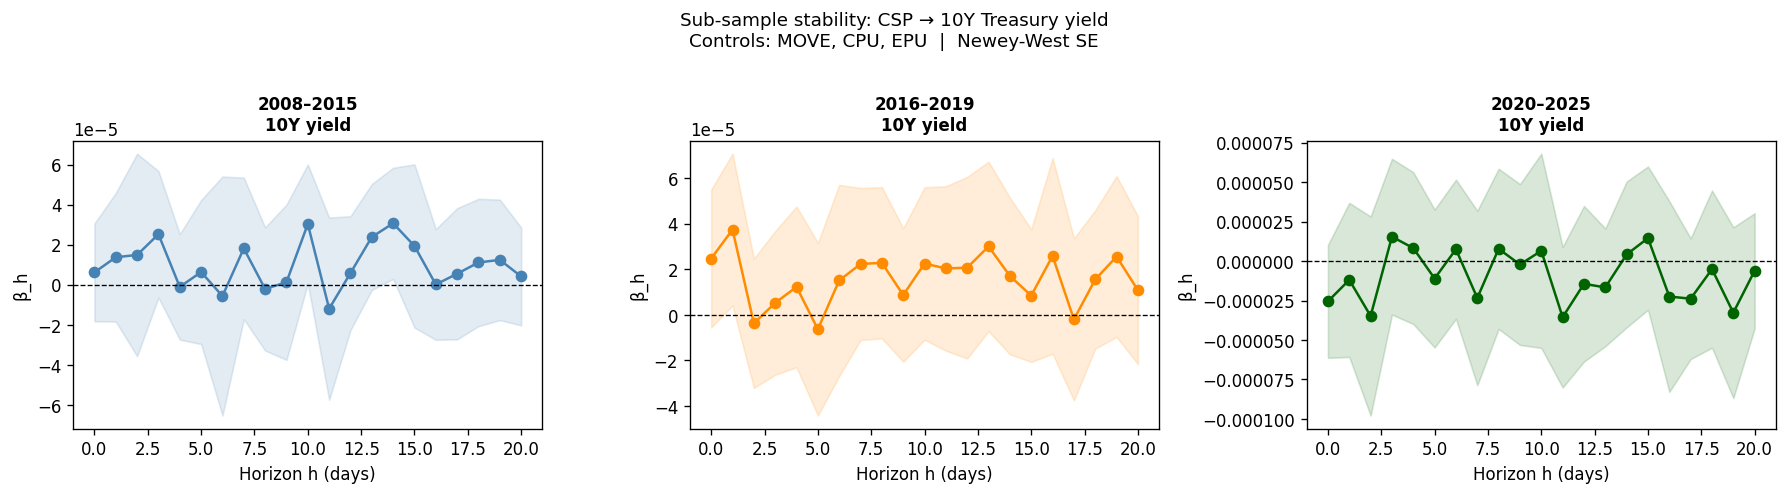

In [36]:
# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
colors = ["steelblue", "darkorange", "darkgreen"]

for ax, (label, lp), color in zip(axes, subsample_res.items(), colors):
    ax.plot(lp["h"], lp["beta"], "o-", lw=1.5, color=color)
    ax.fill_between(lp["h"], lp["ci_lo"], lp["ci_hi"],
                    alpha=0.15, color=color)
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.set_title(f"{label}\n{MAT_FOCUS} yield",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel("Horizon h (days)")
    ax.set_ylabel("β_h")

fig.suptitle(
    "Sub-sample stability: CSP → 10Y Treasury yield\n"
    "Controls: MOVE, CPU, EPU  |  Newey-West SE",
    fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(figdir / "LP_subsample_stability.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
# Summary
print("\n── Sub-sample summary ──")
print(f"{'Period':<15} {'n':>6} {'sig':>5} {'max|β|':>12} {'direction'}")
print("-" * 50)
for label, lp in subsample_res.items():
    n   = lp["nobs"].dropna().iloc[0] if not lp["nobs"].isna().all() else 0
    sig = (lp["pval"] < 0.05).sum()
    maxb = lp["beta"].abs().max()
    pos  = (lp["beta"].dropna() > 0).mean()
    direction = "mostly positive" if pos > 0.6 else "mixed"
    print(f"{label:<15} {int(n):>6} {sig:>5} {maxb:>12.4e} {direction}")


── Sub-sample summary ──
Period               n   sig       max|β| direction
--------------------------------------------------
2008–2015         1836     2   3.0729e-05 mostly positive
2016–2019         1042     1   3.7452e-05 mostly positive
2020–2025         1296     0   3.5533e-05 mixed


### Save all results

In [38]:
# ── Term structure results ────────────────────────────────────────────────────
all_ts = pd.concat(
    [results[mat][spec]
     for mat in available_mats
     for spec in SPECS_AVAILABLE],
    ignore_index=True)
all_ts.to_csv(figdir / "LP_term_structure_all_specs.csv", index=False)
print(f"✓ Term structure results : {figdir / 'LP_term_structure_all_specs.csv'}")

# ── Baseline 10Y ──────────────────────────────────────────────────────────────
lp_baseline.to_csv(figdir / "LP_baseline_10Y.csv", index=False)
print(f"✓ Baseline 10Y           : {figdir / 'LP_baseline_10Y.csv'}")

# ── Long-horizon SSI ──────────────────────────────────────────────────────────
lp_long.to_csv(figdir / "LP_long_horizon_SSI.csv", index=False)
print(f"✓ Long-horizon SSI       : {figdir / 'LP_long_horizon_SSI.csv'}")

# ── Spread ────────────────────────────────────────────────────────────────────
if "spread_lp" in globals() and spread_lp is not None:
    spread_lp.to_csv(figdir / "LP_spread_30Y_2Y.csv", index=False)
    print(f"✓ Spread LP              : {figdir / 'LP_spread_30Y_2Y.csv'}")
else:
    print("  Spread LP not computed — skipping")

# ── Aggregation robustness ────────────────────────────────────────────────────
if "all_agg" in globals() and all_agg:
    agg_rows = []
    for freq_name, freq_res in all_agg.items():
        for mat, lp in freq_res.items():
            lp_copy          = lp.copy()
            lp_copy["freq"]  = freq_name
            lp_copy["mat"]   = mat
            agg_rows.append(lp_copy)
    pd.concat(agg_rows, ignore_index=True).to_csv(
        figdir / "LP_aggregation_robustness.csv", index=False)
    print(f"✓ Aggregation robustness : {figdir / 'LP_aggregation_robustness.csv'}")
else:
    print("  Aggregation robustness not computed — skipping")

# ── Sub-sample stability ──────────────────────────────────────────────────────
if "subsample_res" in globals() and subsample_res:
    sub_rows = []
    for label, lp in subsample_res.items():
        lp_copy           = lp.copy()
        lp_copy["period"] = label
        sub_rows.append(lp_copy)
    pd.concat(sub_rows, ignore_index=True).to_csv(
        figdir / "LP_subsample_stability.csv", index=False)
    print(f"✓ Sub-sample stability   : {figdir / 'LP_subsample_stability.csv'}")
else:
    print("  Sub-sample stability not computed — skipping")

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\n✓ All sovereign bond application results saved")
print(f"  Maturities : {available_mats}")
print(f"  Specs      : {list(SPECS_AVAILABLE.keys())}")
print(f"  Horizons   : h = 0 → {H}")

✓ Term structure results : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_term_structure_all_specs.csv
✓ Baseline 10Y           : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_baseline_10Y.csv
✓ Long-horizon SSI       : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_long_horizon_SSI.csv
✓ Spread LP              : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_spread_30Y_2Y.csv
✓ Aggregation robustness : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_aggregation_robustness.csv
✓ Sub-sample stability   : /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_subsample_stability.csv

✓ All sovereign bond application results saved
  Maturities : ['2Y', '5Y', '10Y', '30Y']
  Specs      : ['baseline', '+MOVE', '+CPU', '+EPU', '+MOVE+CPU', '+MOVE+EPU', '+MOVE+CPU+EPU']
  Horizons   : h = 0 → 20


## Robustness

### SUR: Joint test of maturity gradient

In [39]:
# =============================================================================
# Tests H0: β_h(2Y) = β_h(5Y) = β_h(10Y) = β_h(30Y)
# =============================================================================
from linearmodels.system import SUR
import warnings

for _name in ("yields_by_mat", "panel_base", "available_mats"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

sur_results = {}

for h in [1, 5, 10, 20]:
    equations = {}
    work_dfs  = {}

    # ── Build each maturity equation ─────────────────────────────────────────
    skip_h = False
    for mat in available_mats:
        if mat not in yields_by_mat:
            print(f"h={h}: ⚠ '{mat}' not in yields_by_mat — skipping this h")
            skip_h = True
            break

        # yields_by_mat columns are ["date", "value"] — not "yield"
        y_mat = yields_by_mat[mat].rename(columns={"value": f"y_{mat}"})
        if f"y_{mat}" not in y_mat.columns:
            print(f"h={h}: ⚠ rename failed for '{mat}' — skipping this h")
            skip_h = True
            break

        panel = (panel_base
            .merge(y_mat, on="date", how="inner")
            .sort_values("date")
            .reset_index(drop=True))

        # h is always >= 1 here (loop only runs h in [1,5,10,20]) — this
        # branch is unreachable dead code, kept only for clarity/safety
        # in case the horizon list is ever extended to include 0.
        if h == 0:
            panel["dy"] = panel[f"y_{mat}"].diff()
        else:
            panel["dy"] = panel[f"y_{mat}"].shift(-h) - panel[f"y_{mat}"].shift(1)

        reg_cols = ["CSP", "SSI_lag1"] + [
            c for c in ["move", "cpu", "epu"] if c in panel.columns]

        work = panel[["date", "dy"] + reg_cols].dropna()
        work_dfs[mat] = work.set_index("date")

    if skip_h:
        continue

    # ── Align to common dates across all maturities ───────────────────────────
    common_dates = work_dfs[available_mats[0]].index
    for mat in available_mats[1:]:
        common_dates = common_dates.intersection(work_dfs[mat].index)

    print(f"h={h}: common dates = {len(common_dates):,}")

    if len(common_dates) < 30:
        print(f"  ⚠ Insufficient common dates — skipping h={h}")
        continue

    # ── Build aligned equations ───────────────────────────────────────────────
    for mat in available_mats:
        work_aligned = work_dfs[mat].loc[common_dates].reset_index(drop=True)
        reg_cols     = ["CSP", "SSI_lag1"] + [
            c for c in ["move", "cpu", "epu"]
            if c in work_aligned.columns]

        equations[mat] = {
            "dependent": work_aligned[["dy"]],
            "exog":      sm.add_constant(work_aligned[reg_cols])
        }

    # ── Run SUR ───────────────────────────────────────────────────────────────
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            mod = SUR(equations)
            res = mod.fit(cov_type="robust")

        # Extract CSP coefficients from each equation
        betas = {}
        ses   = {}
        pvals = {}
        for mat in available_mats:
            # linearmodels names params as {equation}_{variable}
            key = f"{mat}_CSP"
            if key in res.params.index:
                betas[mat] = float(res.params[key])
                ses[mat]   = float(res.std_errors[key])
                pvals[mat] = float(res.pvalues[key])

        sur_results[h] = {
            "betas":  betas,
            "ses":    ses,
            "pvals":  pvals,
            "result": res,
            "n":      len(common_dates),
        }

        print(f"\n── SUR results h={h} (n={len(common_dates):,}) ──")
        print(f"{'Maturity':<8} {'β_CSP':>12} {'SE':>12} {'p':>8}")
        for mat in available_mats:
            if mat in betas:
                sig = ("***" if pvals[mat] < 0.01 else
                       "**"  if pvals[mat] < 0.05 else
                       "*"   if pvals[mat] < 0.10 else "")
                print(f"{mat:<8} {betas[mat]:>12.4e} "
                      f"{ses[mat]:>12.4e} {pvals[mat]:>8.4f} {sig}")

        # Test whether gradient is increasing in maturity
        # Compare 30Y beta vs 2Y beta
        if "2Y" in betas and "30Y" in betas:
            diff = betas["30Y"] - betas["2Y"]
            print(f"\n  β(30Y) − β(2Y) = {diff:.4e}")
            print(f"  {'Positive gradient ✓' if diff > 0 else 'Negative gradient ✗'}")

    except Exception as e:
        print(f"h={h}: SUR failed — {e}")

h=1: common dates = 3,915

── SUR results h=1 (n=3,915) ──
Maturity        β_CSP           SE        p
2Y         6.5433e-06   8.9483e-06   0.4646 
5Y         9.0549e-06   1.0509e-05   0.3889 
10Y        8.4376e-06   1.1425e-05   0.4602 
30Y        2.8297e-06   1.1378e-05   0.8036 

  β(30Y) − β(2Y) = -3.7136e-06
  Negative gradient ✗
h=5: common dates = 3,911

── SUR results h=5 (n=3,911) ──
Maturity        β_CSP           SE        p
2Y         2.7517e-06   1.0712e-05   0.7973 
5Y         2.8425e-06   1.1780e-05   0.8093 
10Y       -5.8751e-06   1.2380e-05   0.6351 
30Y       -2.4550e-05   1.1584e-05   0.0341 **

  β(30Y) − β(2Y) = -2.7302e-05
  Negative gradient ✗
h=10: common dates = 3,906

── SUR results h=10 (n=3,906) ──
Maturity        β_CSP           SE        p
2Y         1.1760e-05   1.0146e-05   0.2464 
5Y         1.8025e-05   1.1460e-05   0.1157 
10Y        2.0555e-05   1.1971e-05   0.0860 *
30Y        7.6742e-06   1.1711e-05   0.5123 

  β(30Y) − β(2Y) = -4.0862e-06
  Nega

In [40]:
# ── Summary table ─────────────────────────────────────────────────────────────
if sur_results:
    print("\n── SUR maturity gradient summary ──")
    print(f"{'h':<6} " + " ".join(f"{mat:>12}" for mat in available_mats))
    print("-" * (6 + 13 * len(available_mats)))
    for h, res_h in sur_results.items():
        row = f"{h:<6} "
        for mat in available_mats:
            if mat in res_h["betas"]:
                b   = res_h["betas"][mat]
                sig = ("***" if res_h["pvals"][mat] < 0.01 else
                       "**"  if res_h["pvals"][mat] < 0.05 else
                       "*"   if res_h["pvals"][mat] < 0.10 else "")
                row += f"{b:>10.3e}{sig:>2} "
            else:
                row += f"{'N/A':>12} "
        print(row)
    print("*** p<0.01  ** p<0.05  * p<0.10")


── SUR maturity gradient summary ──
h                2Y           5Y          10Y          30Y
----------------------------------------------------------
1       6.543e-06    9.055e-06    8.438e-06    2.830e-06   
5       2.752e-06    2.842e-06   -5.875e-06   -2.455e-05** 
10      1.176e-05    1.803e-05    2.056e-05 *  7.674e-06   
20      2.691e-06   -6.958e-08   -5.703e-07   -9.789e-06   
*** p<0.01  ** p<0.05  * p<0.10


In [41]:
# =============================================================================
# VERIFY: is the SUR/univariate gradient discrepancy a bug, a horizon mismatch,
# or a sample-restriction artifact?
# =============================================================================

for _name in ("results", "yields_by_mat", "panel_base", "NW_LAGS"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

# [1] Compute univariate LP gradient (30Y - 2Y) at the SAME horizons SUR used
print("── Univariate LP gradient at h=1,5,10,20 (own-sample per maturity) ──")
for h in [1, 5, 10, 20]:
    b2  = results["2Y"]["baseline"].loc[results["2Y"]["baseline"]["h"]==h, "beta"].values[0]
    b30 = results["30Y"]["baseline"].loc[results["30Y"]["baseline"]["h"]==h, "beta"].values[0]
    grad = b30 - b2
    print(f"  h={h:>2}: β(2Y)={b2:.3e}  β(30Y)={b30:.3e}  gradient={grad:+.3e}  "
          f"{'✓ positive (steepens)' if grad > 0 else '✗ negative'}")

# [2] Compute univariate LP gradient at h=0 (the horizon the steepening claim uses)
print("\n── Univariate LP gradient at h=0 (the horizon your text actually cites) ──")
b2_0  = results["2Y"]["baseline"].loc[results["2Y"]["baseline"]["h"]==0, "beta"].values[0]
b30_0 = results["30Y"]["baseline"].loc[results["30Y"]["baseline"]["h"]==0, "beta"].values[0]
print(f"  h=0: β(2Y)={b2_0:.3e}  β(30Y)={b30_0:.3e}  gradient={b30_0-b2_0:+.3e}  "
      f"{'✓ positive (steepens)' if (b30_0-b2_0) > 0 else '✗ negative'}")

# [3] Re-run the SUR-style common-dates restriction, but as UNIVARIATE OLS,
#     at h=0, to isolate whether SAMPLE RESTRICTION alone explains the flip.
#     NOTE: no move/cpu/epu controls here (matches the "baseline" spec used in
#     [1]/[2]) — this isolates sample restriction only, NOT whether SUR's
#     inclusion of controls also contributes to the sign flip.
print("\n── Univariate OLS restricted to SUR's common-dates sample, h=0 ──")

if "2Y" not in yields_by_mat or "30Y" not in yields_by_mat:
    raise RuntimeError(
        f"'2Y'/'30Y' not both in yields_by_mat. Available: {list(yields_by_mat.keys())}"
    )

# yields_by_mat columns are ["date", "value"] — not "yield"
y2_0  = yields_by_mat["2Y"].rename(columns={"value": "y_2Y"})
y30_0 = yields_by_mat["30Y"].rename(columns={"value": "y_30Y"})

common = (panel_base
    .merge(y2_0,  on="date", how="inner")
    .merge(y30_0, on="date", how="inner")
    .sort_values("date").reset_index(drop=True))
common["dy_2Y"]  = common["y_2Y"].diff()
common["dy_30Y"] = common["y_30Y"].diff()
common = common[["dy_2Y", "dy_30Y", "CSP", "SSI_lag1"]].dropna()

if common.empty:
    raise RuntimeError("common panel is empty after dropna — check date overlap.")

r2  = sm.OLS(common["dy_2Y"].values,
             sm.add_constant(common[["CSP","SSI_lag1"]].values)).fit(
             cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True})
r30 = sm.OLS(common["dy_30Y"].values,
             sm.add_constant(common[["CSP","SSI_lag1"]].values)).fit(
             cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True})

print(f"  common-sample n={len(common)} (vs 30Y-only n={results['30Y']['baseline']['nobs'].iloc[0]})")
print(f"  β(2Y)={r2.params[1]:.3e}  β(30Y)={r30.params[1]:.3e}  "
      f"gradient={r30.params[1]-r2.params[1]:+.3e}  "
      f"{'✓ positive' if (r30.params[1]-r2.params[1])>0 else '✗ negative'}")
print(f"\n  If this sign matches SUR's h=1/5/10/20 pattern (negative), the flip is a")
print(f"  sample-restriction artifact, not a SUR-vs-OLS estimator difference.")
print(f"  If this sign matches the h=0 steepening claim (positive), the flip is")
print(f"  purely a horizon-mismatch — SUR and OLS agree once compared properly.")

── Univariate LP gradient at h=1,5,10,20 (own-sample per maturity) ──
  h= 1: β(2Y)=1.044e-05  β(30Y)=2.594e-06  gradient=-7.846e-06  ✗ negative
  h= 5: β(2Y)=6.011e-06  β(30Y)=-2.480e-05  gradient=-3.081e-05  ✗ negative
  h=10: β(2Y)=1.473e-05  β(30Y)=7.398e-06  gradient=-7.332e-06  ✗ negative
  h=20: β(2Y)=5.868e-06  β(30Y)=-1.011e-05  gradient=-1.598e-05  ✗ negative

── Univariate LP gradient at h=0 (the horizon your text actually cites) ──
  h=0: β(2Y)=-2.444e-06  β(30Y)=2.160e-06  gradient=+4.603e-06  ✓ positive (steepens)

── Univariate OLS restricted to SUR's common-dates sample, h=0 ──
  common-sample n=3916 (vs 30Y-only n=3916)
  β(2Y)=-4.784e-06  β(30Y)=2.160e-06  gradient=+6.944e-06  ✓ positive

  If this sign matches SUR's h=1/5/10/20 pattern (negative), the flip is a
  sample-restriction artifact, not a SUR-vs-OLS estimator difference.
  If this sign matches the h=0 steepening claim (positive), the flip is
  purely a horizon-mismatch — SUR and OLS agree once compared prope

### Joint signifcance test

In [42]:
# =============================================================================
# Uses a simple F-test on the stacked system
# =============================================================================

from scipy.stats import chi2

print("── Joint test: β_h = 0 for all h, by maturity ──\n")
for mat in available_mats:
    lp_df = results[mat]["baseline"].dropna(subset=["beta", "se"])
    if len(lp_df) == 0:
        continue

    # Wald-style: sum of squared t-statistics / df
    tstats  = lp_df["tstat"].dropna().values
    chi2_stat = float(np.sum(tstats ** 2))
    df        = len(tstats)
    p_joint   = float(1 - chi2.cdf(chi2_stat, df))

    print(f"  {mat}: chi2({df}) = {chi2_stat:.2f}, p = {p_joint:.4f} "
          f"{'✓ jointly significant' if p_joint < 0.05 else '✗ not jointly significant'}")

── Joint test: β_h = 0 for all h, by maturity ──

  2Y: chi2(21) = 13.21, p = 0.9012 ✗ not jointly significant
  5Y: chi2(21) = 19.13, p = 0.5766 ✗ not jointly significant
  10Y: chi2(21) = 17.53, p = 0.6785 ✗ not jointly significant
  30Y: chi2(21) = 12.43, p = 0.9272 ✗ not jointly significant


### CSP vs SSI Pricing Comparison

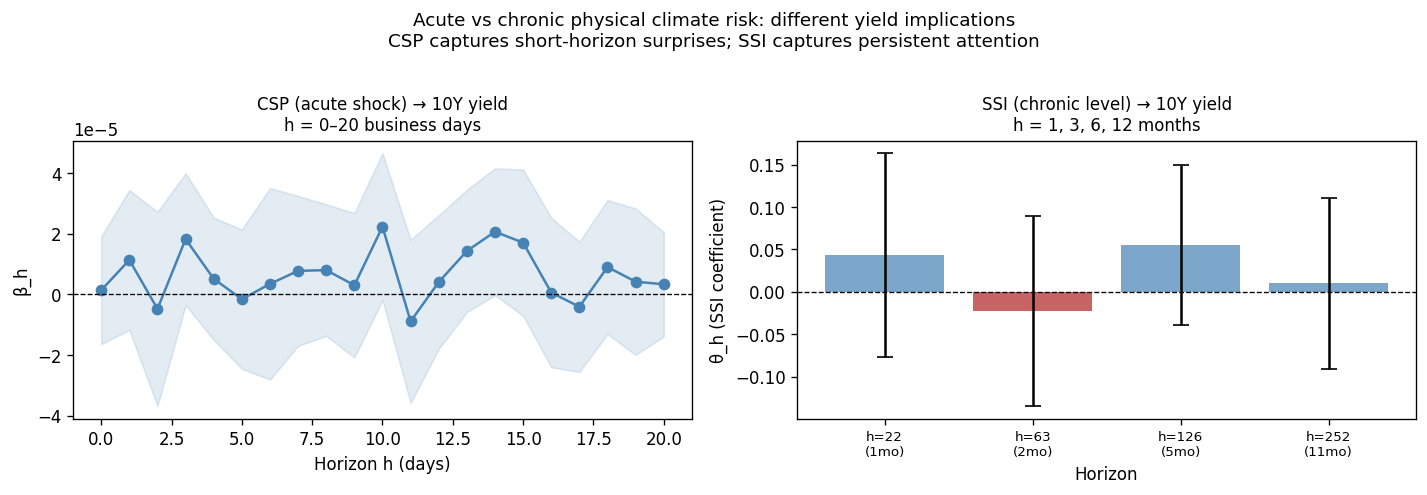

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: CSP short-horizon
ax = axes[0]
ax.plot(lp_baseline["h"], lp_baseline["beta"],
        "o-", lw=1.5, color="steelblue")
ax.fill_between(lp_baseline["h"],
                lp_baseline["ci_lo"], lp_baseline["ci_hi"],
                alpha=0.15, color="steelblue")
ax.axhline(0, color="black", lw=0.8, linestyle="--")
ax.set_title("CSP (acute shock) → 10Y yield\nh = 0–20 business days",
             fontsize=10)
ax.set_xlabel("Horizon h (days)")
ax.set_ylabel("β_h")

# Right: SSI long-horizon
ax = axes[1]
lp_long_plot = lp_long.dropna(subset=["theta_SSI", "se_NW"])
ax.bar(range(len(lp_long_plot)),
       lp_long_plot["theta_SSI"],
       color=["steelblue" if v > 0 else "firebrick"
              for v in lp_long_plot["theta_SSI"]],
       alpha=0.7)
ax.errorbar(range(len(lp_long_plot)),
            lp_long_plot["theta_SSI"],
            yerr=1.96 * lp_long_plot["se_NW"],
            fmt="none", color="black", capsize=5)
ax.set_xticks(range(len(lp_long_plot)))
ax.set_xticklabels(
    [f"h={int(h)}\n({int(h/22)}mo)" for h in lp_long_plot["horizon"]],
    fontsize=8)
ax.axhline(0, color="black", lw=0.8, linestyle="--")
ax.set_title("SSI (chronic level) → 10Y yield\nh = 1, 3, 6, 12 months",
             fontsize=10)
ax.set_xlabel("Horizon")
ax.set_ylabel("θ_h (SSI coefficient)")

fig.suptitle(
    "Acute vs chronic physical climate risk: different yield implications\n"
    "CSP captures short-horizon surprises; SSI captures persistent attention",
    fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(figdir / "LP_acute_vs_chronic.png", dpi=150, bbox_inches="tight")
plt.show()

### Yield Level Panel Regression ~ Persistence

In [44]:
# =============================================================================
# ADF STATIONARITY CHECK — is the level regression above at spurious-regression risk?
#
# H0 (null): the series has a unit root (non-stationary)
# Reject H0 (p < 0.05) → series is stationary → level regression is safer
# Fail to reject → series is non-stationary → level regression risks spurious
#   correlation from shared trends, not a genuine relationship
# =============================================================================

from statsmodels.tsa.stattools import adfuller

for _name in ("yields_by_mat", "panel_base", "available_mats"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

def run_adf(series, label, maxlag=None, autolag="AIC"):
    s = pd.Series(series).dropna()
    if len(s) < 20:
        return {"series": label, "n": len(s), "adf_stat": np.nan,
                "p_value": np.nan, "n_lags": np.nan,
                "verdict": "⚠ too few obs"}
    result = adfuller(s.values, maxlag=maxlag, autolag=autolag)
    adf_stat, p_value, n_lags = result[0], result[1], result[2]
    verdict = "stationary ✓" if p_value < 0.05 else "NON-stationary ✗"
    return {"series": label, "n": len(s), "adf_stat": round(adf_stat, 4),
            "p_value": round(p_value, 4), "n_lags": n_lags, "verdict": verdict}

adf_rows = []

# ── Yield levels, per maturity ────────────────────────────────────────────────
for mat in available_mats:
    if mat not in yields_by_mat:
        continue
    if "value" not in yields_by_mat[mat].columns:
        print(f"  ⚠ {mat}: 'value' column not found, skipping ADF")
        continue
    adf_rows.append(run_adf(yields_by_mat[mat]["value"], f"y_{mat} (level)"))

# ── SSI (the persistent EWMA smoother) ────────────────────────────────────────
if "SSI" in panel_base.columns:
    adf_rows.append(run_adf(panel_base["SSI"], "SSI"))
if "SSI_lag1" in panel_base.columns:
    adf_rows.append(run_adf(panel_base["SSI_lag1"], "SSI_lag1"))

# ── CSP, as a sanity check — should already be stationary by construction ────
if "CSP" in panel_base.columns:
    adf_rows.append(run_adf(panel_base["CSP"], "CSP"))

# ── Yield first differences, for comparison — should be stationary ───────────
for mat in available_mats:
    if mat not in yields_by_mat or "value" not in yields_by_mat[mat].columns:
        continue
    dy = yields_by_mat[mat]["value"].diff()
    adf_rows.append(run_adf(dy, f"Δy_{mat} (first difference)"))

adf_df = pd.DataFrame(adf_rows)
print("── ADF stationarity results ──")
display(adf_df)

n_nonstat_levels = adf_df.loc[
    adf_df["series"].str.contains(r"^y_|^SSI", regex=True),
    "verdict"
].eq("NON-stationary ✗").sum()

print(f"\n{'─'*70}")
if n_nonstat_levels > 0:
    print(f"⚠ {n_nonstat_levels} level series are non-stationary.")
    print("  The level regression (CSP/SSI on yield levels) is at real risk of")
    print("  spurious regression — its coefficients and R² may reflect shared")
    print("  trends rather than a genuine relationship. Prefer the differenced")
    print("  (Δy) local projection results elsewhere in this notebook as the")
    print("  primary evidence; treat the level regression as exploratory only,")
    print("  or consider a formal cointegration test (e.g. Engle-Granger) if")
    print("  you want to defend it as a levels-relationship claim.")
else:
    print("✓ All level series tested stationary — the level regression is on")
    print("  firmer ground, though this is still worth citing as a check you")
    print("  performed rather than assuming.")

── ADF stationarity results ──


,series,n,adf_stat,p_value,n_lags,verdict
0,y_2Y (level),8998,-23.701400,0.000000,13,stationary ✓
1,y_5Y (level),9122,-29.571800,0.000000,9,stationary ✓
2,y_10Y (level),9122,-20.790900,0.000000,17,stationary ✓
3,y_30Y (level),3917,-15.463100,0.000000,14,stationary ✓
4,SSI,4697,-4.243700,0.000600,1,stationary ✓
5,SSI_lag1,4696,-4.245000,0.000600,1,stationary ✓
6,CSP,4445,-64.202400,0.000000,0,stationary ✓
7,Δy_2Y (first difference),8997,-26.890300,0.000000,37,stationary ✓
8,Δy_5Y (first difference),9121,-26.328200,0.000000,37,stationary ✓
9,Δy_10Y (first difference),9121,-25.524100,0.000000,38,stationary ✓



──────────────────────────────────────────────────────────────────────
✓ All level series tested stationary — the level regression is on
  firmer ground, though this is still worth citing as a check you
  performed rather than assuming.


### Event Study — Yield response around top-10 CSP spikes

In [45]:
top10_dates = (pcra.nlargest(10, "CSP")[["date", "CSP"]]
               .reset_index(drop=True))

print("Top-10 CSP spike dates:")
display(top10_dates)

Top-10 CSP spike dates:


,date,CSP
0,2010-11-29,14.542452
1,2010-06-15,13.655174
2,2023-12-06,13.629554
3,2013-02-12,12.806961
4,2010-02-02,12.499966
5,2012-07-20,11.116678
6,2022-04-28,11.057461
7,2017-01-04,9.862149
8,2016-05-26,9.755041
9,2017-07-18,9.158245


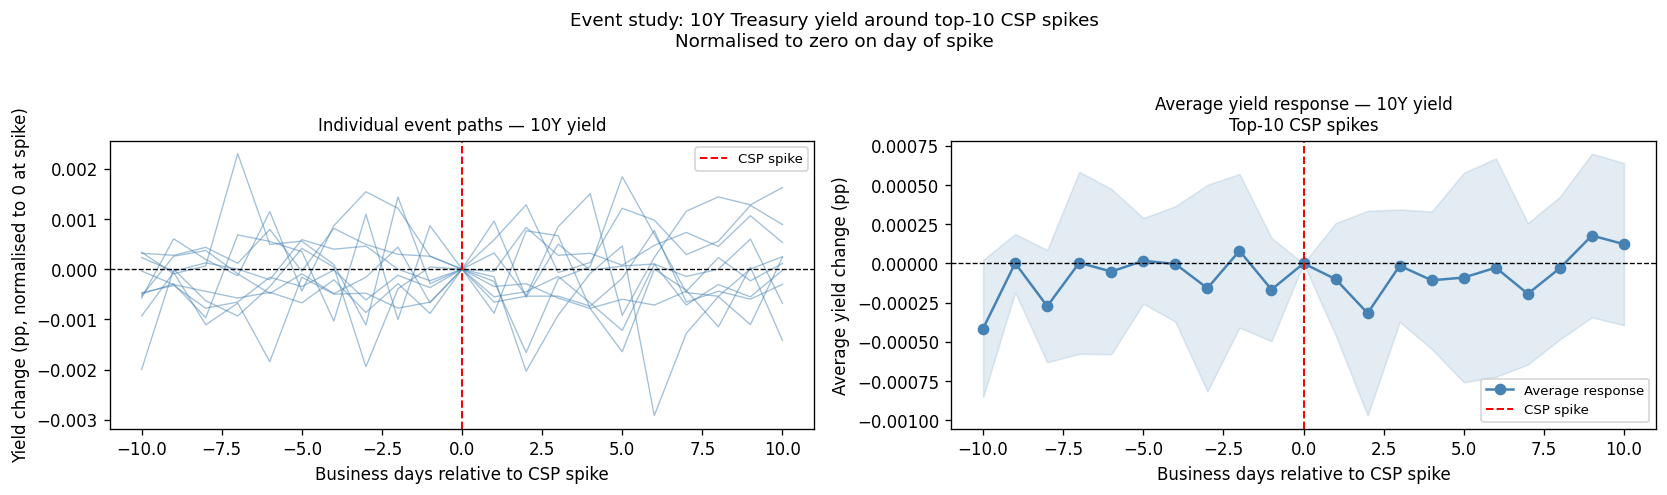

In [46]:
window    = 10  # ±10 business days
mat_focus = "10Y"

for _name in ("yields_by_mat", "top10_dates", "figdir"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

if mat_focus not in yields_by_mat:
    raise RuntimeError(
        f"'{mat_focus}' not in yields_by_mat. Available: {list(yields_by_mat.keys())}"
    )

# yields_by_mat columns are ["date", "value"] — not "yield"
y_10y = yields_by_mat[mat_focus].rename(columns={"value": "y_10Y"})
if "y_10Y" not in y_10y.columns:
    raise RuntimeError(
        f"Rename failed. Actual columns: {list(yields_by_mat[mat_focus].columns)}"
    )

event_panels = []
for _, spike in top10_dates.iterrows():
    edate = spike["date"]
    mask  = ((y_10y["date"] >= edate - pd.Timedelta(days=window * 2)) &
             (y_10y["date"] <= edate + pd.Timedelta(days=window * 2)))
    sub   = y_10y[mask].copy().sort_values("date").reset_index(drop=True)

    if len(sub) == 0:
        continue

    # Find index of event date
    event_idx = sub["date"].searchsorted(edate)
    if event_idx >= len(sub):
        continue

    sub["rel_day"]    = range(-event_idx, len(sub) - event_idx)
    sub["y_norm"]     = sub["y_10Y"] - sub.loc[event_idx, "y_10Y"]
    sub["event_date"] = edate
    sub["csp_val"]    = spike["CSP"]

    # Trim to the actual ±window business days claimed by the plot labels —
    # the mask above pulls in a wider calendar-day range (2x window) to
    # guarantee enough business days on each side after weekends/holidays.
    sub = sub[sub["rel_day"].between(-window, window)].reset_index(drop=True)

    event_panels.append(sub)

if event_panels:
    events_df = pd.concat(event_panels, ignore_index=True)

    # Average cumulative yield change across all events
    avg_response = (events_df
        .groupby("rel_day")["y_norm"]
        .agg(["mean", "std", "count"])
        .reset_index())
    avg_response["ci_lo"] = (avg_response["mean"]
                              - 1.96 * avg_response["std"]
                              / avg_response["count"] ** 0.5)
    avg_response["ci_hi"] = (avg_response["mean"]
                              + 1.96 * avg_response["std"]
                              / avg_response["count"] ** 0.5)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Left: individual event paths
    ax = axes[0]
    for _, spike in top10_dates.iterrows():
        sub = events_df[events_df["event_date"] == spike["date"]]
        ax.plot(sub["rel_day"], sub["y_norm"],
                lw=0.8, alpha=0.5, color="steelblue")
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.axvline(0, color="red",   lw=1.2, linestyle="--", label="CSP spike")
    ax.set_xlabel("Business days relative to CSP spike")
    ax.set_ylabel("Yield change (pp, normalised to 0 at spike)")
    ax.set_title(f"Individual event paths — {mat_focus} yield", fontsize=10)
    ax.legend(fontsize=8)

    # Right: average response
    ax = axes[1]
    ax.plot(avg_response["rel_day"], avg_response["mean"],
            "o-", lw=1.5, color="steelblue", label="Average response")
    ax.fill_between(avg_response["rel_day"],
                    avg_response["ci_lo"], avg_response["ci_hi"],
                    alpha=0.15, color="steelblue")
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.axvline(0, color="red",   lw=1.2, linestyle="--", label="CSP spike")
    ax.set_xlabel("Business days relative to CSP spike")
    ax.set_ylabel("Average yield change (pp)")
    ax.set_title(f"Average yield response — {mat_focus} yield\n"
                 f"Top-10 CSP spikes", fontsize=10)
    ax.legend(fontsize=8)

    fig.suptitle(
        "Event study: 10Y Treasury yield around top-10 CSP spikes\n"
        "Normalised to zero on day of spike",
        fontsize=11, y=1.02)
    fig.tight_layout()
    fig.savefig(figdir / "event_study_top10_CSP_yield.png",
                dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("⚠ No event panels built — check top10_dates and y_10y have overlapping dates.")

### Asymmetry test — positive vs negative CSP shocks

In [47]:
panel_asym = (panel_base
    .merge(y_10y, on="date", how="inner")
    .sort_values("date")
    .reset_index(drop=True))

panel_asym["CSP_pos"] = panel_asym["CSP"].clip(lower=0)
panel_asym["CSP_neg"] = panel_asym["CSP"].clip(upper=0)

asym_rows = []
asym_controls = [c for c in ["move", "cpu", "epu"]
                 if c in panel_asym.columns]

for h in range(H + 1):
    work = panel_asym.copy()
    if h == 0:
        work["dy"] = work["y_10Y"].diff()
    else:
        work["dy"] = work["y_10Y"].shift(-h) - work["y_10Y"].shift(1)

    reg_cols = ["CSP_pos", "CSP_neg", "SSI_lag1"] + asym_controls
    work     = work[["dy"] + reg_cols].dropna()

    if len(work) < 30:
        asym_rows.append({"h": h, "beta_pos": np.nan,
                          "beta_neg": np.nan, "pval_pos": np.nan,
                          "pval_neg": np.nan})
        continue

    y   = work["dy"].values
    X   = sm.add_constant(work[reg_cols].values)
    res = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": NW_LAGS, "use_correction": True})

    asym_rows.append({
        "h":        h,
        "beta_pos": round(float(res.params[1]), 6),
        "se_pos":   round(float(res.bse[1]),    6),
        "pval_pos": round(float(res.pvalues[1]),4),
        "beta_neg": round(float(res.params[2]), 6),
        "se_neg":   round(float(res.bse[2]),    6),
        "pval_neg": round(float(res.pvalues[2]),4),
    })

asym_df = pd.DataFrame(asym_rows)
asym_df["ci_pos_lo"] = asym_df["beta_pos"] - 1.96 * asym_df["se_pos"]
asym_df["ci_pos_hi"] = asym_df["beta_pos"] + 1.96 * asym_df["se_pos"]
asym_df["ci_neg_lo"] = asym_df["beta_neg"] - 1.96 * asym_df["se_neg"]
asym_df["ci_neg_hi"] = asym_df["beta_neg"] + 1.96 * asym_df["se_neg"]

print(f"Positive CSP — significant: {(asym_df['pval_pos'] < 0.05).sum()}/{H+1}")
print(f"Negative CSP — significant: {(asym_df['pval_neg'] < 0.05).sum()}/{H+1}")


Positive CSP — significant: 2/21
Negative CSP — significant: 1/21


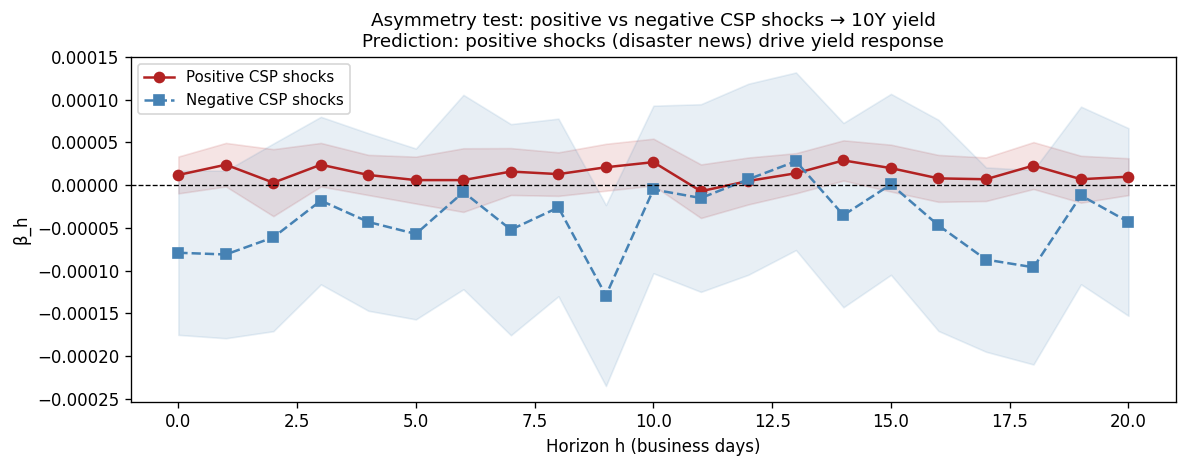

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(asym_df["h"], asym_df["beta_pos"],
        "o-", lw=1.5, color="firebrick", label="Positive CSP shocks")
ax.fill_between(asym_df["h"],
                asym_df["ci_pos_lo"], asym_df["ci_pos_hi"],
                alpha=0.12, color="firebrick")
ax.plot(asym_df["h"], asym_df["beta_neg"],
        "s--", lw=1.5, color="steelblue", label="Negative CSP shocks")
ax.fill_between(asym_df["h"],
                asym_df["ci_neg_lo"], asym_df["ci_neg_hi"],
                alpha=0.12, color="steelblue")
ax.axhline(0, color="black", lw=0.8, linestyle="--")
ax.set_xlabel("Horizon h (business days)")
ax.set_ylabel("β_h")
ax.set_title(
    "Asymmetry test: positive vs negative CSP shocks → 10Y yield\n"
    "Prediction: positive shocks (disaster news) drive yield response",
    fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "LP_asymmetry_pos_neg_CSP.png", dpi=150, bbox_inches="tight")
plt.show()

### Damage Control Robustness

In [49]:
# =============================================================================
# DAMAGE CONTROL ROBUSTNESS
# Add EM-DAT monthly total damages as control
# If CSP survives, it captures information beyond realised damages
# =============================================================================

for _name in ("emdat_us", "pcra", "yields_by_mat"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

if "Total Deaths" not in emdat_us.columns:
    raise RuntimeError(
        f"'Total Deaths' column not found in emdat_us. "
        f"Actual columns: {list(emdat_us.columns)}"
    )
if "10Y" not in yields_by_mat:
    raise RuntimeError(
        f"'10Y' not in yields_by_mat. Available: {list(yields_by_mat.keys())}"
    )

emdat_damages = (emdat_us
    .assign(date=lambda d: pd.to_datetime(d["event_date"])
            .dt.to_period("M").dt.to_timestamp())
    .groupby("date")
    .agg(emdat_count=("event_date", "count"),
         emdat_deaths=("Total Deaths", "sum"))
    .reset_index()
    .fillna(0))

# Merge onto monthly aggregated panel
pcra_m = (pcra
    .assign(date=lambda d: pd.to_datetime(d["date"])
            .dt.to_period("M").dt.to_timestamp())
    .groupby("date")
    .agg(CSP_mean=("CSP", "mean"), SSI_last=("SSI", "last"))
    .reset_index()
    .assign(SSI_lag1=lambda d: d["SSI_last"].shift(1))
    .dropna())

# yields_by_mat columns are ["date", "value"] — not "yield"
y_10y_m = (yields_by_mat["10Y"]
    .rename(columns={"value": "yield"})
    .assign(date=lambda d: pd.to_datetime(d["date"])
            .dt.to_period("M").dt.to_timestamp())
    .groupby("date").last()
    .reset_index())

damage_panel = (pcra_m
    .merge(y_10y_m, on="date", how="inner")
    .merge(emdat_damages, on="date", how="left")
    .fillna({"emdat_count": 0, "emdat_deaths": 0})
    .sort_values("date")
    .reset_index(drop=True))

if "yield" not in damage_panel.columns:
    raise RuntimeError(
        f"'yield' column missing from damage_panel after merge. "
        f"Columns present: {list(damage_panel.columns)}"
    )

damage_panel["dy"] = damage_panel["yield"].diff()
damage_panel       = damage_panel.dropna(subset=["dy", "CSP_mean", "SSI_lag1"])

if len(damage_panel) < 30:
    raise RuntimeError(
        f"damage_panel has only {len(damage_panel)} rows after dropna — "
        f"too few observations for a monthly regression with HAC SEs."
    )

# Without damage control
reg_base = ["CSP_mean", "SSI_lag1"]
res_base = sm.OLS(
    damage_panel["dy"].values,
    sm.add_constant(damage_panel[reg_base].values)
).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

# With damage count control
reg_dmg  = ["CSP_mean", "SSI_lag1", "emdat_count"]
res_dmg  = sm.OLS(
    damage_panel["dy"].values,
    sm.add_constant(damage_panel[reg_dmg].values)
).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

print("── Damage control robustness (monthly, 10Y yield) ──\n")
print(f"{'':25} {'Without damages':>18} {'With damage count':>18}")
print("-" * 65)
for i, label in enumerate(["const", "CSP_mean", "SSI_lag1"]):
    b1 = res_base.params[i]
    p1 = res_base.pvalues[i]
    b2 = res_dmg.params[i]
    p2 = res_dmg.pvalues[i]
    s1 = "***" if p1<0.01 else "**" if p1<0.05 else "*" if p1<0.10 else ""
    s2 = "***" if p2<0.01 else "**" if p2<0.05 else "*" if p2<0.10 else ""
    print(f"  {label:<23} {b1:>10.4e}{s1:<3}    {b2:>10.4e}{s2:<3}")

b_dmg = res_dmg.params[3]
p_dmg = res_dmg.pvalues[3]
s_dmg = "***" if p_dmg<0.01 else "**" if p_dmg<0.05 else "*" if p_dmg<0.10 else ""
print(f"  {'emdat_count':<23} {'—':>13}    {b_dmg:>10.4e}{s_dmg:<3}")
print(f"\n  R² without damages : {res_base.rsquared:.4f}")
print(f"  R² with damages    : {res_dmg.rsquared:.4f}")
print(f"\nInterpretation:")
if abs(res_dmg.params[1]) >= abs(res_base.params[1]) * 0.8:
    print("  ✓ CSP coefficient survives damage control — captures information")
    print("    beyond realised EM-DAT damage counts.")
else:
    print("  ⚠ CSP coefficient attenuated by damage control — review.")

── Damage control robustness (monthly, 10Y yield) ──

                             Without damages  With damage count
-----------------------------------------------------------------
  const                   2.8559e-05       1.0102e-04   
  CSP_mean                3.0951e-04       3.4798e-04*  
  SSI_lag1                -6.2814e-03       -1.9095e-03   
  emdat_count                         —    -4.2488e-05   

  R² without damages : 0.0095
  R² with damages    : 0.0176

Interpretation:
  ✓ CSP coefficient survives damage control — captures information
    beyond realised EM-DAT damage counts.


## Risk and Term Premiums


In [50]:
from pathlib import Path
import pandas as pd
import statsmodels.api as sm

# =============================================================================
# FIXED LOCAL PROJECTION FUNCTION
# =============================================================================

def run_lp(y, X, h, shock_var):
    """
    Local projection:
        y_{t+h} - y_{t-1} = alpha + beta * shock_var_t + controls_t + error

    Returns coefficient, SE, and p-value for shock_var.
    """
    dep = (y.shift(-h) - y.shift(1)).dropna()

    Xs = sm.add_constant(X, has_constant="add").loc[dep.index]

    m = sm.OLS(dep, Xs).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": h + 1}
    )

    if shock_var not in m.params.index:
        raise KeyError(
            f"'{shock_var}' is not in the regression. "
            f"Available regressors are: {list(m.params.index)}"
        )

    return m.params[shock_var], m.bse[shock_var], m.pvalues[shock_var], m


# =============================================================================
# 0. GUARDS
# =============================================================================

for _name in ("pcra_monthly", "panel_base"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")


# =============================================================================
# 1. MONTHLY CSP + SSI
# =============================================================================

csp_m = (
    pcra_monthly
    .rename(columns={"CSP_mean": "CSP", "SSI_lag1": "SSI"})
    [["date", "CSP", "SSI"]]
    .copy()
)

csp_m["date"] = pd.to_datetime(csp_m["date"]) + pd.offsets.MonthEnd(0)


# =============================================================================
# 2. MONTHLY CPU
# =============================================================================

if "cpu" not in panel_base.columns:
    raise RuntimeError(
        f"'cpu' column not found in panel_base. "
        f"Actual columns: {list(panel_base.columns)}"
    )

cpu_m = panel_base.copy()
cpu_m["date"] = pd.to_datetime(cpu_m["date"]) + pd.offsets.MonthEnd(0)

cpu_m = (
    cpu_m
    .groupby("date", as_index=False)["cpu"]
    .mean()
    .rename(columns={"cpu": "CPU"})
)


# =============================================================================
# 3. ACM TERM PREMIUM DATA
# =============================================================================

# ⚠ RISK_PATH was referenced but never defined in this session — using the
# confirmed ACM_PATH from earlier (SOVEREIGN_DIR / "ACMTermPremium.xls").
# Confirm this is right; rename to RISK_PATH properly if that's meant to be
# a distinct/separate config variable elsewhere in your notebook.
if "ACM_PATH" not in dir():
    raise NameError("'ACM_PATH' is not defined. Run the Sovereign config cell first.")

_risk_path = ACM_PATH

if not _risk_path.exists():
    raise FileNotFoundError(f"ACM file not found at {_risk_path}")

acm = (
    pd.read_excel(_risk_path, engine="xlrd", parse_dates=["DATE"])
    .set_index("DATE")[["ACMTP10", "ACMRNY10"]]
    .sort_index()
    .resample("ME")
    .last()
    .dropna()
    .reset_index()
    .rename(columns={"DATE": "date"})
)

acm["date"] = pd.to_datetime(acm["date"]) + pd.offsets.MonthEnd(0)


# =============================================================================
# 4. MERGE
# =============================================================================

d = (
    csp_m
    .merge(cpu_m, on="date", how="inner")
    .merge(acm, on="date", how="inner")
    .set_index("date")
    .sort_index()
    .dropna()
)

print("merged:", list(d.columns), "| obs:", len(d))

if d.empty:
    raise RuntimeError("Merged panel 'd' is empty — check date overlap across csp_m/cpu_m/acm.")

assert "CSP" in d.columns and d["CSP"].std() > 0, "CSP missing or constant"
assert "SSI" in d.columns and d["SSI"].std() > 0, "SSI missing or constant"


# =============================================================================
# 5A. RESPONSE TO CSP SHOCK, CONTROLLING FOR SSI
# =============================================================================

SHOCK = "CSP"
CTRL = ["SSI"]
X = d[[SHOCK] + CTRL]

print("\nResponse to a CSP shock, controlling for SSI")
for comp in ["ACMTP10", "ACMRNY10"]:
    print(f"\n{comp}")
    for h in (0, 1, 5):
        b, se, p, m = run_lp(d[comp], X, h, shock_var=SHOCK)
        print(f"   h={h}: β={b:+.3e}  se={se:.3e}  p={p:.3f} {'*' if p < 0.10 else ''}")


# =============================================================================
# 5B. RESPONSE TO SSI SHOCK, CONTROLLING FOR CSP
# =============================================================================

SHOCK = "SSI"
CTRL = ["CSP"]
X = d[[SHOCK] + CTRL]

print("\nResponse to an SSI shock, controlling for CSP")
for comp in ["ACMTP10", "ACMRNY10"]:
    print(f"\n{comp}")
    for h in (0, 1, 5):
        b, se, p, m = run_lp(d[comp], X, h, shock_var=SHOCK)
        print(f"   h={h}: β={b:+.3e}  se={se:.3e}  p={p:.3f} {'*' if p < 0.10 else ''}")


# =============================================================================
# 5C. SSI ONLY, NO CONTROLS
# =============================================================================

SHOCK = "SSI"
X = d[[SHOCK]]

print("\nResponse to an SSI shock, no controls")
for comp in ["ACMTP10", "ACMRNY10"]:
    print(f"\n{comp}")
    for h in (0, 1, 5):
        b, se, p, m = run_lp(d[comp], X, h, shock_var=SHOCK)
        print(f"   h={h}: β={b:+.3e}  se={se:.3e}  p={p:.3f} {'*' if p < 0.10 else ''}")

merged: ['CSP', 'SSI', 'CPU', 'ACMTP10', 'ACMRNY10'] | obs: 204

Response to a CSP shock, controlling for SSI

ACMTP10
   h=0: β=-5.785e-02  se=7.385e-02  p=0.433 
   h=1: β=-3.158e-02  se=1.002e-01  p=0.753 
   h=5: β=-7.463e-03  se=1.930e-01  p=0.969 

ACMRNY10
   h=0: β=-4.057e-02  se=3.975e-02  p=0.307 
   h=1: β=-6.638e-03  se=5.669e-02  p=0.907 
   h=5: β=+1.338e-02  se=1.147e-01  p=0.907 

Response to an SSI shock, controlling for CSP

ACMTP10
   h=0: β=-5.671e+00  se=1.089e+01  p=0.602 
   h=1: β=-7.555e+00  se=1.845e+01  p=0.682 
   h=5: β=-1.312e+01  se=3.489e+01  p=0.707 

ACMRNY10
   h=0: β=+5.789e+00  se=5.209e+00  p=0.266 
   h=1: β=+1.374e+01  se=9.211e+00  p=0.136 
   h=5: β=+3.468e+01  se=3.388e+01  p=0.306 

Response to an SSI shock, no controls

ACMTP10
   h=0: β=-3.545e+00  se=1.063e+01  p=0.739 
   h=1: β=-6.368e+00  se=1.713e+01  p=0.710 
   h=5: β=-1.285e+01  se=3.223e+01  p=0.690 

ACMRNY10
   h=0: β=+7.280e+00  se=5.159e+00  p=0.158 
   h=1: β=+1.398e+01  se=8.

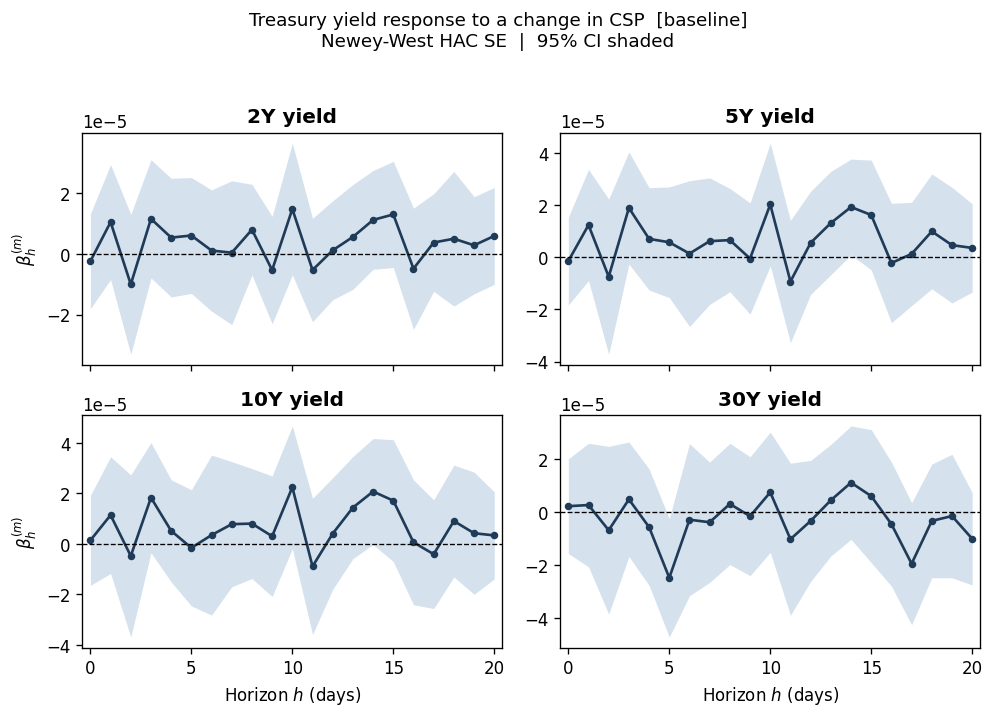

✓ Saved: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/treasury_lp_response.png


In [51]:
import numpy as np
import matplotlib.pyplot as plt

# Pull from results dict (already populated by term structure LP cell)
# Uses baseline spec — change "baseline" to any key in SPECS_AVAILABLE
SPEC    = "baseline"
H_PLOT  = H  # uses H defined in configuration cell

maturities = [m for m in ["2Y", "5Y", "10Y", "30Y"] if m in results]
z = 1.96

horizons = np.arange(H_PLOT + 1)
coef = {m: results[m][SPEC]["beta"].values[:H_PLOT + 1] for m in maturities}
se   = {m: results[m][SPEC]["se"].values[:H_PLOT + 1]   for m in maturities}

fig, axes = plt.subplots(2, 2, figsize=(8.4, 6.0), sharex=True, sharey=False)
for ax, m in zip(axes.ravel(), maturities):
    b, s = coef[m], se[m]
    ax.fill_between(horizons, b - z * s, b + z * s,
                    color="#5B8DB8", alpha=0.25, linewidth=0)
    ax.plot(horizons, b, color="#1f3b57", linewidth=1.6, marker="o",
            markersize=3.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(f"{m} yield", fontweight="bold")
    ax.margins(x=0.02)

for ax in axes[-1, :]:
    ax.set_xlabel("Horizon $h$ (days)")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\beta^{(m)}_h$")

fig.suptitle(
    f"Treasury yield response to a change in CSP  [{SPEC}]\n"
    "Newey-West HAC SE  |  95% CI shaded",
    fontsize=11, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figdir / "treasury_lp_response.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'treasury_lp_response.png'}")

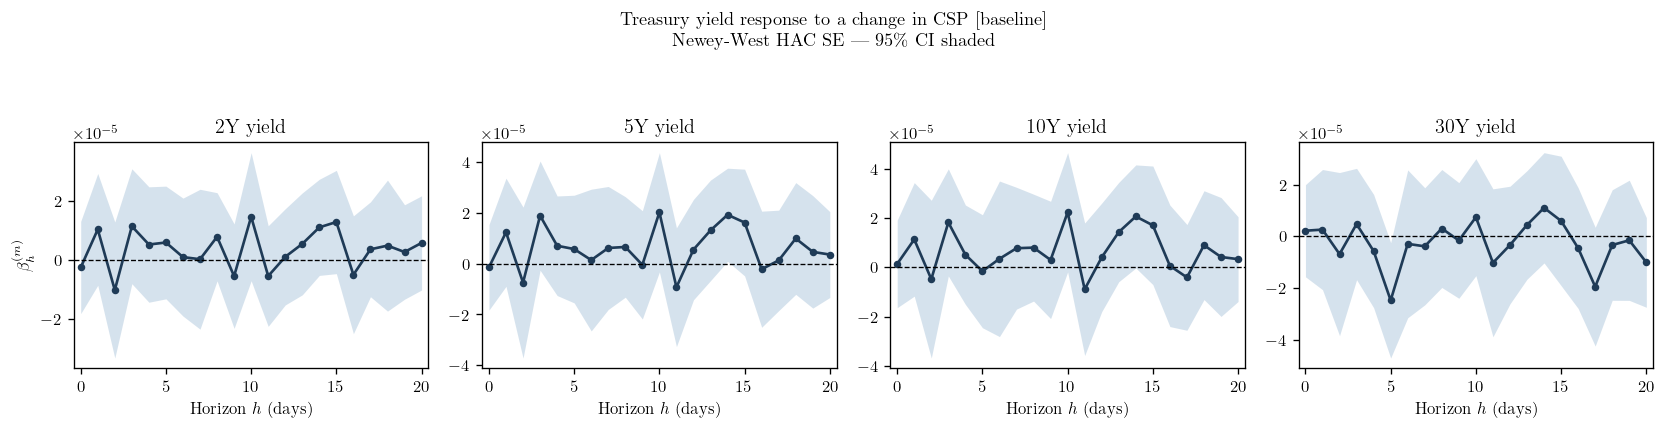

✓ Saved: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/treasury_lp_response.png


In [52]:
import numpy as np
import matplotlib.pyplot as plt

# Match LaTeX document fonts (uses your local LaTeX installation to render text)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
})

# Pull from results dict (already populated by term structure LP cell)
# Uses baseline spec — change "baseline" to any key in SPECS_AVAILABLE
SPEC    = "baseline"
H_PLOT  = H  # uses H defined in configuration cell
maturities = [m for m in ["2Y", "5Y", "10Y", "30Y"] if m in results]
z = 1.96
horizons = np.arange(H_PLOT + 1)
coef = {m: results[m][SPEC]["beta"].values[:H_PLOT + 1] for m in maturities}
se   = {m: results[m][SPEC]["se"].values[:H_PLOT + 1]   for m in maturities}

fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.4), sharex=True, sharey=False)
for ax, m in zip(axes.ravel(), maturities):
    b, s = coef[m], se[m]
    ax.fill_between(horizons, b - z * s, b + z * s,
                    color="#5B8DB8", alpha=0.25, linewidth=0)
    ax.plot(horizons, b, color="#1f3b57", linewidth=1.6, marker="o",
            markersize=3.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(f"{m} yield", fontweight="bold")
    ax.margins(x=0.02)
for ax in axes:
    ax.set_xlabel("Horizon $h$ (days)")
axes[0].set_ylabel(r"$\beta^{(m)}_h$")

fig.suptitle(
    f"Treasury yield response to a change in CSP  [{SPEC}]\n"
    "Newey-West HAC SE  |  95\\% CI shaded",
    fontsize=11, y=1.04)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figdir / "treasury_lp_response.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'treasury_lp_response.png'}")

## Lag Exploration

── β at h=0 and significance across h=0..10 ──

mat    csp          ssi                β(h=0)   p(h=0)  sig/total
----------------------------------------------------------------
2Y     CSP          no_SSI         -2.435e-06       0.784     0/11
2Y     CSP          with_SSI       -2.406e-06       0.787     0/11
2Y     CSP_lag1     no_SSI          1.258e-05       0.175     0/11
2Y     CSP_lag1     with_SSI        1.262e-05       0.177     0/11
2Y     CSP_lag2     no_SSI         -2.035e-05*      0.061     1/11
2Y     CSP_lag2     with_SSI       -2.053e-05*      0.061     1/11
2Y     CSP_lag5     no_SSI          5.509e-07       0.969     0/11
2Y     CSP_lag5     with_SSI        5.127e-07       0.972     0/11
5Y     CSP          no_SSI         -1.472e-06       0.874     0/11
5Y     CSP          with_SSI       -1.334e-06       0.886     0/11
5Y     CSP_lag1     no_SSI          1.365e-05       0.196     0/11
5Y     CSP_lag1     with_SSI        1.357e-05       0.201     0/11
5Y     CSP_lag2  

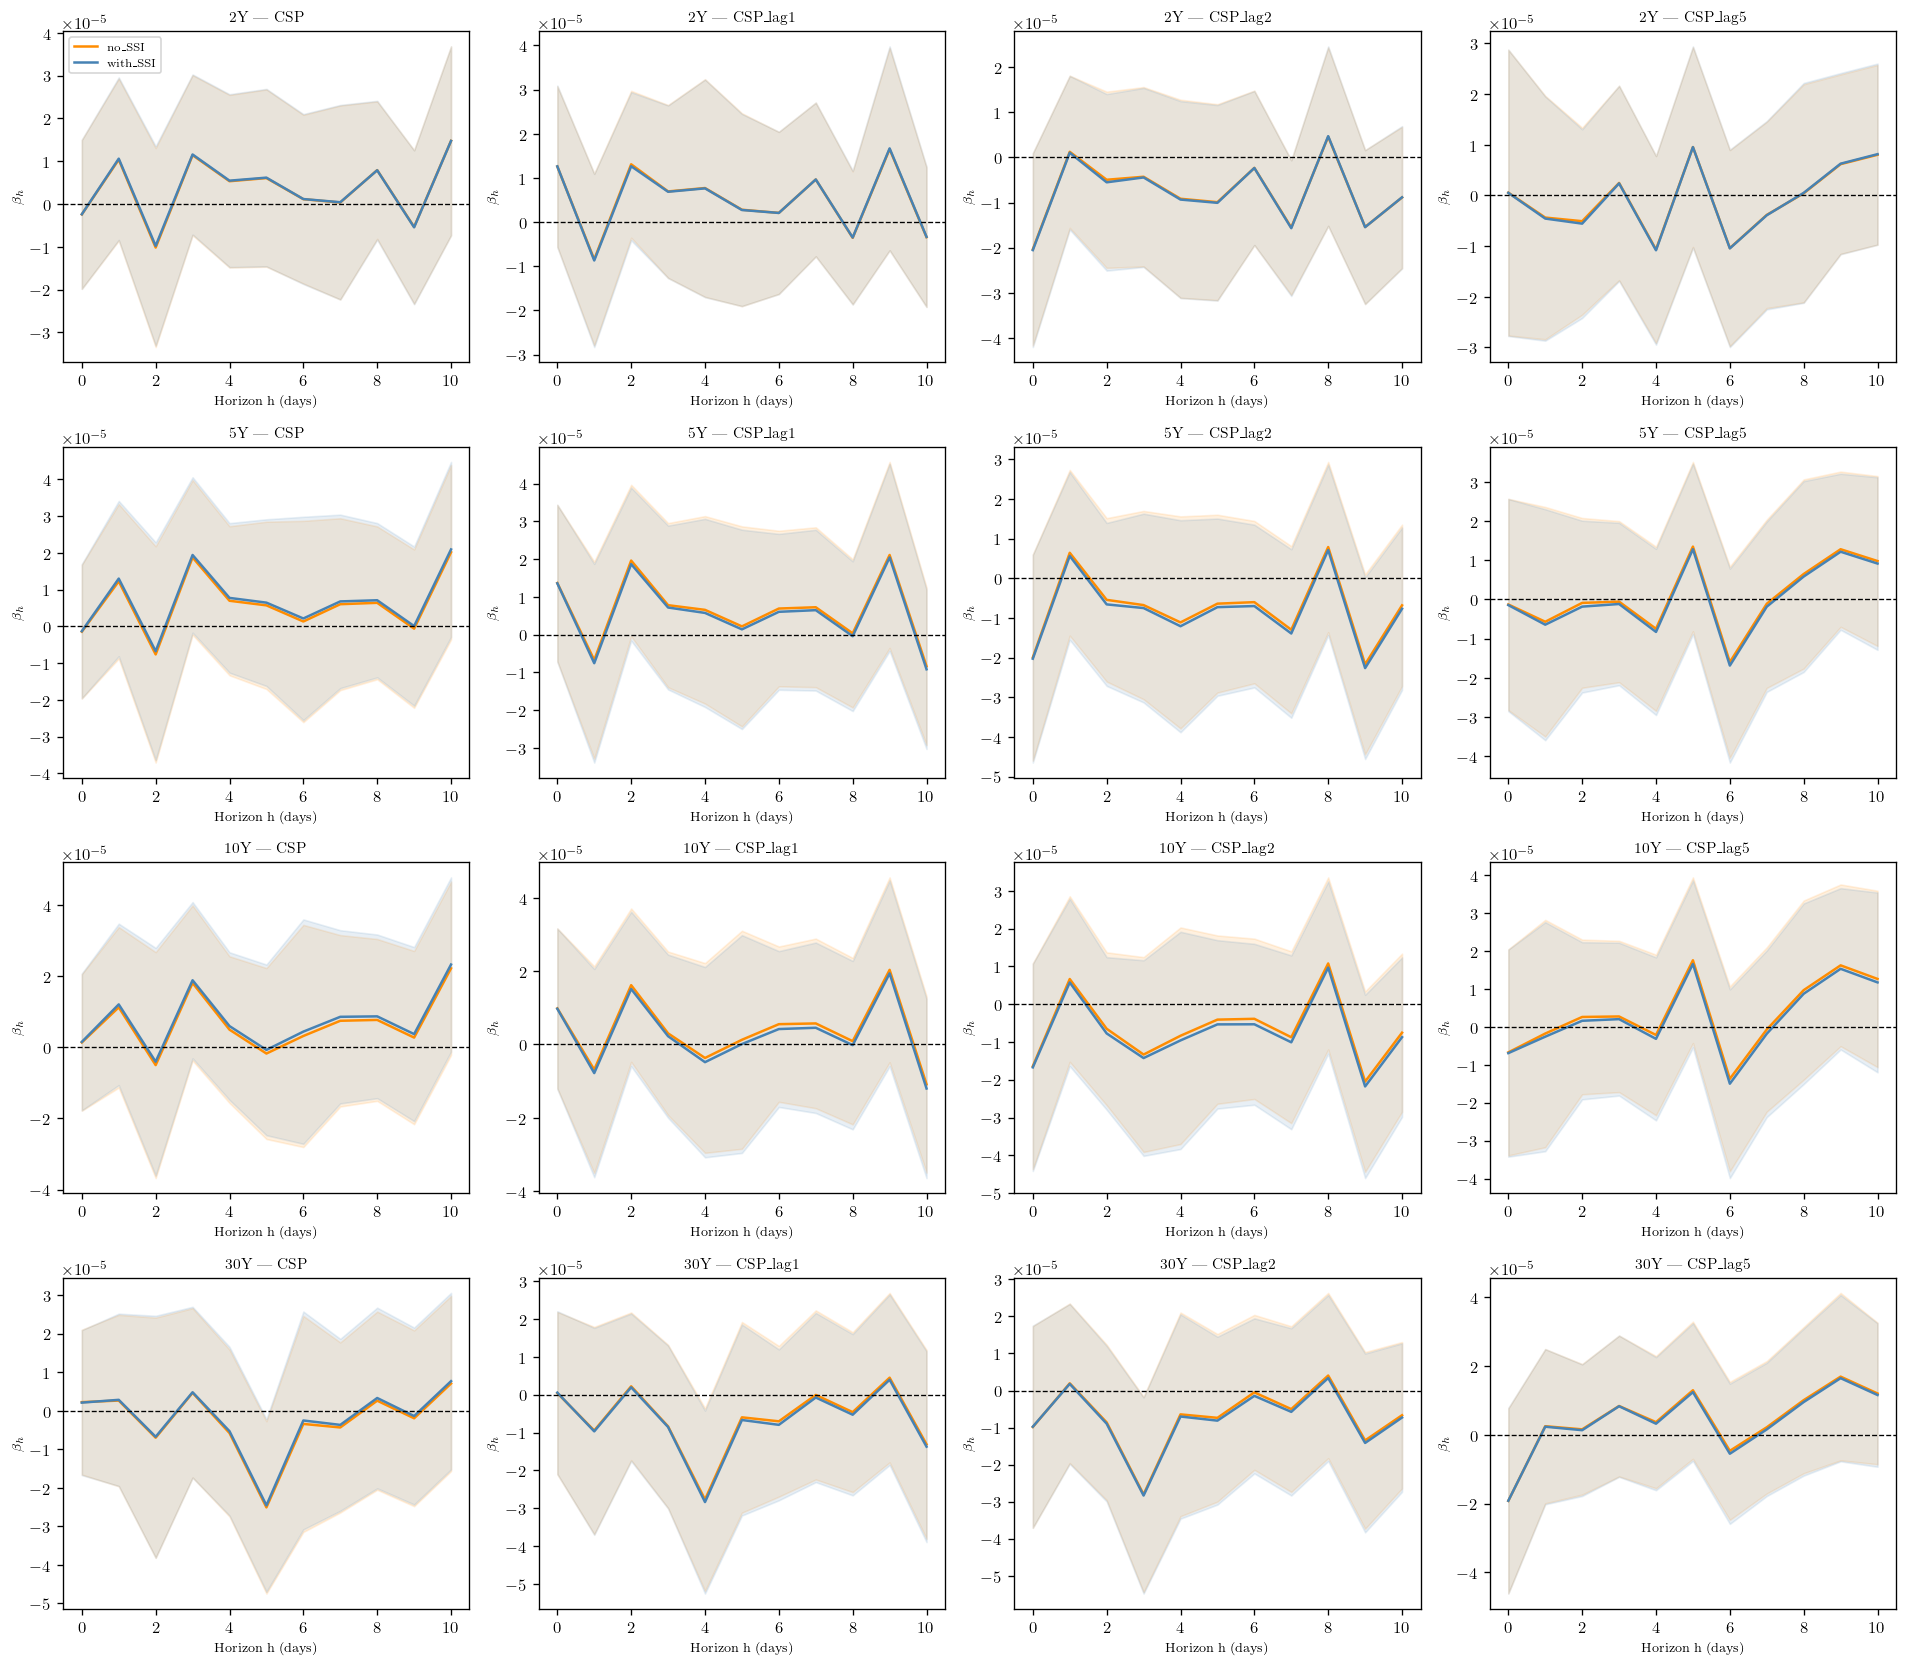

✓ Saved: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/lag_explorer_IRF.png


In [57]:
# =============================================================================
# LAG EXPLORER — paste at bottom of Sovereign_Bonds.ipynb
# Addresses Annika's feedback:
#   1. Try CSP with lags (leading indicator)
#   2. Industry-specific beta and theta (SSI combinations)
# Edit the CONFIG block only.
# =============================================================================

for _name in ("yields_by_mat", "panel_base", "available_mats", "figdir"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

# ── CONFIG ────────────────────────────────────────────────────────────────────

CSP_LAGS    = [0, 1, 2, 5]   # lags of CSP to test (0 = contemporaneous)
SSI_SPECS   = {
    "no_SSI":      False,     # drop SSI control entirely
    "with_SSI":    True,      # keep SSI_lag1 as control (baseline)
}
MATS        = available_mats  # or e.g. ["10Y"] to narrow
H_LAG       = 10              # max horizon

# ─────────────────────────────────────────────────────────────────────────────

# Build lagged CSP columns
for lag in CSP_LAGS:
    col = f"CSP_lag{lag}" if lag > 0 else "CSP"
    if col not in panel_base.columns:
        panel_base[col] = panel_base["CSP"].shift(lag)

csp_cols = [f"CSP_lag{lag}" if lag > 0 else "CSP" for lag in CSP_LAGS]
extra    = [c for c in ["move", "cpu", "epu"] if c in panel_base.columns]

def _lp_lag(panel, dep_col, h, csp_col, use_ssi):
    work = panel.copy()
    work["dy"] = (work[dep_col].shift(-h) - work[dep_col].shift(1)
                  if h > 0 else work[dep_col].diff())
    regs = [csp_col] + (["SSI_lag1"] if use_ssi else []) + extra
    work = work[["dy"] + regs].dropna()
    if len(work) < 30:
        return dict(beta=np.nan, se=np.nan, pval=np.nan, nobs=len(work))
    res = sm.OLS(work["dy"], sm.add_constant(work[regs])).fit(
        cov_type="HAC", cov_kwds={"maxlags": h + 1, "use_correction": True})
    return dict(beta=float(res.params[csp_col]),
                se=float(res.bse[csp_col]),
                pval=float(res.pvalues[csp_col]),
                nobs=int(res.nobs))

# Run all combinations
lag_results = {}   # (mat, csp_col, ssi_label) -> DataFrame over h

for mat in MATS:
    if mat not in yields_by_mat:
        print(f"  ⚠ {mat}: not in yields_by_mat, skipping")
        continue

    # yields_by_mat columns are ["date", "value"] — not "yield"
    y_mat = yields_by_mat[mat].rename(columns={"value": f"y_{mat}"})
    if f"y_{mat}" not in y_mat.columns:
        print(f"  ⚠ {mat}: rename failed, skipping")
        continue

    panel = (panel_base.merge(y_mat, on="date", how="inner")
             .sort_values("date").reset_index(drop=True))

    if panel.empty:
        print(f"  ⚠ {mat}: empty panel after merge, skipping")
        continue

    for csp_col in csp_cols:
        for ssi_label, use_ssi in SSI_SPECS.items():
            rows = []
            for h in range(H_LAG + 1):
                r = _lp_lag(panel, f"y_{mat}", h, csp_col, use_ssi)
                r.update(h=h, mat=mat, csp=csp_col, ssi=ssi_label)
                rows.append(r)
            df = pd.DataFrame(rows)
            df["ci_lo"] = df["beta"] - 1.96 * df["se"]
            df["ci_hi"] = df["beta"] + 1.96 * df["se"]
            lag_results[(mat, csp_col, ssi_label)] = df

if not lag_results:
    raise RuntimeError("lag_results is empty — no maturity produced a valid panel.")

# ── Summary: β at h=0 and significance count ──────────────────────────────────
print(f"── β at h=0 and significance across h=0..{H_LAG} ──\n")
print(f"{'mat':<6} {'csp':<12} {'ssi':<12} {'β(h=0)':>12} {'p(h=0)':>8} {'sig/total':>10}")
print("-" * 64)
for (mat, csp_col, ssi_label), df in lag_results.items():
    b0   = df.loc[df["h"] == 0, "beta"].values[0]
    p0   = df.loc[df["h"] == 0, "pval"].values[0]
    nsig = (df["pval"] < 0.05).sum()
    ntot = df["pval"].notna().sum()
    star = "***" if p0 < 0.01 else "**" if p0 < 0.05 else "*" if p0 < 0.10 else ""
    print(f"{mat:<6} {csp_col:<12} {ssi_label:<12} {b0:>12.3e}{star:<3} "
          f"{p0:>8.3f} {nsig:>5}/{ntot}")

# ── IRF plots ─────────────────────────────────────────────────────────────────
present_mats = sorted({k[0] for k in lag_results.keys()}, key=MATS.index)
n_rows = len(present_mats)
n_cols = len(csp_cols)
fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(4 * n_cols, 3.5 * n_rows),
                          sharey=False, squeeze=False)

colors = {"no_SSI": "darkorange", "with_SSI": "steelblue"}

for ri, mat in enumerate(present_mats):
    for ci, csp_col in enumerate(csp_cols):
        ax = axes[ri][ci]
        for ssi_label in SSI_SPECS:
            key = (mat, csp_col, ssi_label)
            if key not in lag_results:
                continue
            df = lag_results[key]
            ax.plot(df["h"], df["beta"], lw=1.5,
                    color=colors[ssi_label], label=ssi_label)
            ax.fill_between(df["h"], df["ci_lo"], df["ci_hi"],
                            alpha=0.12, color=colors[ssi_label])
        ax.axhline(0, color="black", lw=0.8, linestyle="--")
        ax.set_title(f"{mat} | {csp_col}", fontsize=9, fontweight="bold")
        ax.set_xlabel("Horizon h (days)", fontsize=8)
        ax.set_ylabel(r"$\beta_h$", fontsize=8)

axes[0][0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(figdir / "lag_explorer_IRF.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'lag_explorer_IRF.png'}")

### Check Frequencies

✓ Weekly controls available: ['move', 'cpu', 'epu']
2Y: 0/9 weeks significant
5Y: 2/9 weeks significant
10Y: 2/9 weeks significant
30Y: 1/9 weeks significant


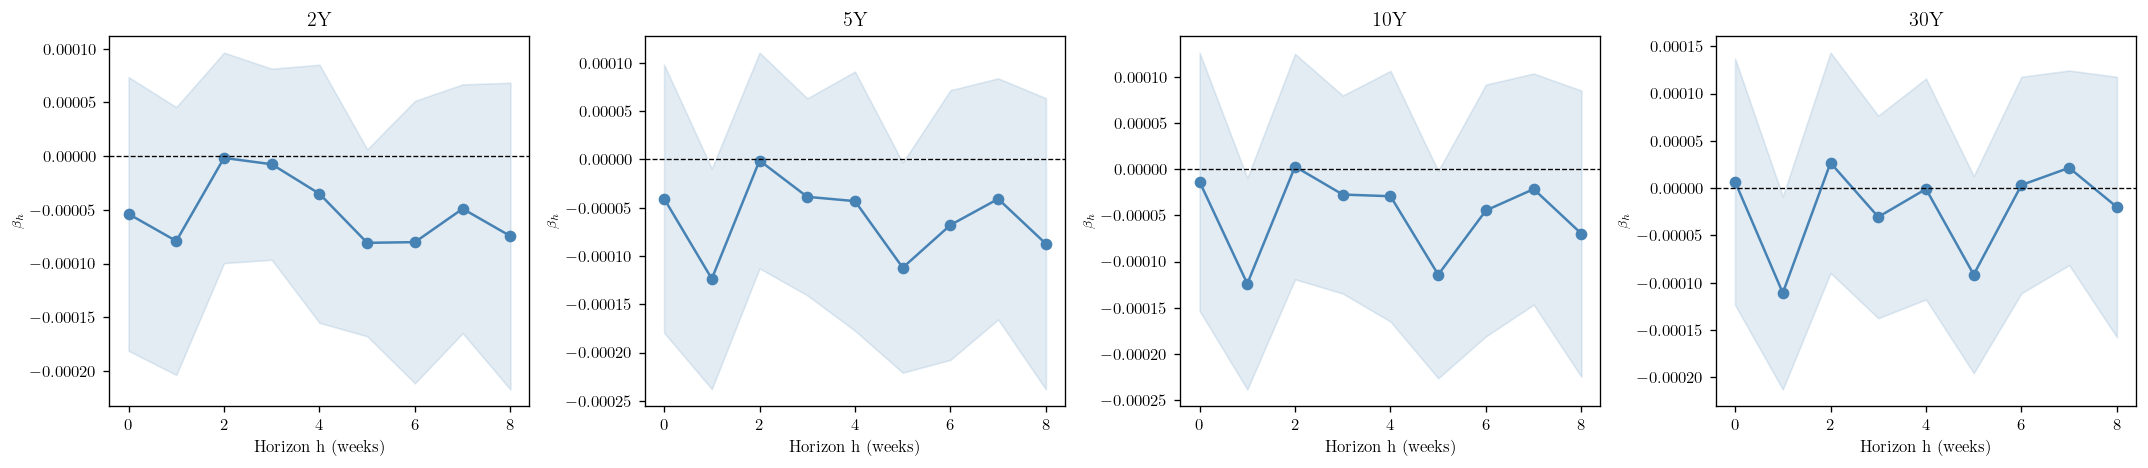

✓ Saved: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/LP_weekly_term_structure.png


In [60]:
for _name in ("pcra", "yields_by_mat", "available_mats", "epu_df", "figdir"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

H_WEEKLY = 8   # 8 weeks ~ 2 months

def to_weekly(df, date_col="date"):
    return (df.set_index(date_col)
              .resample("W-FRI")
              .last()
              .dropna()
              .reset_index())

# Aggregate index
pcra_w = (pcra[["date", "CSP", "SSI"]]
          .set_index("date")
          .resample("W-FRI")
          .agg({"CSP": "mean", "SSI": "last"})
          .dropna()
          .reset_index())
pcra_w["SSI_lag1"] = pcra_w["SSI"].shift(1)
pcra_w = pcra_w.dropna().reset_index(drop=True)

# Aggregate controls
def agg_control_w(df, col):
    if col not in df.columns:
        raise RuntimeError(
            f"Expected '{col}' column not found. Actual columns: {list(df.columns)}"
        )
    return (df.set_index("date")[col]
              .resample("W-FRI").mean()
              .dropna()
              .reset_index())

ctrl_w = pcra_w.copy()

# move_clean, not raw move_df — move_df has columns ['index','us'], not
# ['date','move'], and would fail agg_control_w immediately.
if "move_clean" in dir() and move_clean is not None:
    ctrl_w = ctrl_w.merge(agg_control_w(move_clean, "move"), on="date", how="left")
else:
    print("⚠ move_clean not in scope — omitting MOVE from weekly controls")

if "cpu_daily" in dir() and cpu_daily is not None:
    ctrl_w = ctrl_w.merge(agg_control_w(cpu_daily, "cpu"), on="date", how="left")
else:
    print("⚠ cpu_daily not in scope — omitting CPU from weekly controls")

ctrl_w = ctrl_w.merge(agg_control_w(epu_df, "epu"), on="date", how="left")

extra_w = [c for c in ["move", "cpu", "epu"] if c in ctrl_w.columns]
print(f"✓ Weekly controls available: {extra_w}")

def lp_weekly(panel, dep_col, h, extra_controls):
    work = panel.copy()
    work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1) if h > 0 else work[dep_col].diff()
    regs = ["CSP", "SSI_lag1"] + extra_controls
    work = work[["dy"] + regs].dropna()
    if len(work) < 20:
        return dict(beta=np.nan, se=np.nan, pval=np.nan, nobs=len(work))
    res = sm.OLS(work["dy"], sm.add_constant(work[regs])).fit(
        cov_type="HAC", cov_kwds={"maxlags": h + 1, "use_correction": True})
    return dict(beta=float(res.params["CSP"]),
                se=float(res.bse["CSP"]),
                pval=float(res.pvalues["CSP"]),
                nobs=int(res.nobs))

weekly_results = {}
for mat in available_mats:
    if mat not in yields_by_mat:
        print(f"  ⚠ {mat}: not in yields_by_mat, skipping")
        continue

    y_w = to_weekly(yields_by_mat[mat])
    y_w.columns = ["date", f"y_{mat}"]
    panel = ctrl_w.merge(y_w, on="date", how="inner").sort_values("date").reset_index(drop=True)

    if panel.empty:
        print(f"  ⚠ {mat}: empty panel after merge, skipping")
        continue

    rows = []
    for h in range(H_WEEKLY + 1):
        r = lp_weekly(panel, f"y_{mat}", h, extra_w)
        r["h"] = h
        rows.append(r)
    df = pd.DataFrame(rows)
    df["ci_lo"] = df["beta"] - 1.96 * df["se"]
    df["ci_hi"] = df["beta"] + 1.96 * df["se"]
    weekly_results[mat] = df
    sig = (df["pval"] < 0.05).sum()
    print(f"{mat}: {sig}/{H_WEEKLY+1} weeks significant")

if not weekly_results:
    raise RuntimeError("weekly_results is empty — no maturity produced a valid panel.")

# Plot
present_mats = [m for m in available_mats if m in weekly_results]
fig, axes = plt.subplots(1, len(present_mats),
                          figsize=(4.5 * len(present_mats), 4), sharey=False)
axes = np.array(axes).flatten()
for ax, mat in zip(axes, present_mats):
    df = weekly_results[mat]
    ax.plot(df["h"], df["beta"], "o-", lw=1.5, color="steelblue")
    ax.fill_between(df["h"], df["ci_lo"], df["ci_hi"], alpha=0.15, color="steelblue")
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.set_title(f"{mat}", fontweight="bold")
    ax.set_xlabel("Horizon h (weeks)")
    ax.set_ylabel(r"$\beta_h$", fontsize=8)

fig.tight_layout()
fig.savefig(figdir / "LP_weekly_term_structure.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'LP_weekly_term_structure.png'}")

In [62]:
# ─────────────────────────────────────────────────────────────────────────────
# Bare single-index specs
# ─────────────────────────────────────────────────────────────────────────────

for _name in ("yields_by_mat", "panel_base", "available_mats", "H", "figdir"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

BARE_SPECS = {
    "CSP only":          [],               # no SSI, no controls
    "CSP + SSI":         ["SSI_lag1"],     # add SSI
    "CSP + SSI + MOVE":  ["SSI_lag1", "move"],
    "CSP + SSI + CPU":   ["SSI_lag1", "cpu"],
    "CSP + SSI + all":   ["SSI_lag1", "move", "cpu", "epu"],
}

def lp_bare(panel, dep_col, h, regs):
    work = panel.copy()
    work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1) if h > 0 else work[dep_col].diff()
    keep = ["CSP"] + regs
    work = work[["dy"] + keep].dropna()
    if len(work) < 30:
        return dict(beta=np.nan, se=np.nan, pval=np.nan)
    res = sm.OLS(work["dy"], sm.add_constant(work[keep])).fit(
        cov_type="HAC", cov_kwds={"maxlags": h + 1, "use_correction": True})
    return dict(beta=float(res.params["CSP"]),
                se=float(res.bse["CSP"]),
                pval=float(res.pvalues["CSP"]))

bare_results = {mat: {} for mat in available_mats}
for mat in available_mats:
    if mat not in yields_by_mat:
        print(f"  ⚠ {mat}: not in yields_by_mat, skipping")
        continue

    # yields_by_mat columns are ["date", "value"] — not "yield"
    y_mat = yields_by_mat[mat].rename(columns={"value": f"y_{mat}"})
    if f"y_{mat}" not in y_mat.columns:
        print(f"  ⚠ {mat}: rename failed, skipping")
        continue

    panel = (panel_base.merge(y_mat, on="date", how="inner")
             .sort_values("date").reset_index(drop=True))

    if panel.empty:
        print(f"  ⚠ {mat}: empty panel after merge, skipping")
        continue

    for spec_name, regs in BARE_SPECS.items():
        regs_avail = [r for r in regs if r in panel.columns]
        if len(regs_avail) != len(regs):
            missing = set(regs) - set(regs_avail)
            print(f"  ⚠ {mat}/{spec_name}: missing controls {missing}, "
                  f"running with {regs_avail} instead")
        rows = []
        for h in range(H + 1):
            r = lp_bare(panel, f"y_{mat}", h, regs_avail)
            r["h"] = h
            rows.append(r)
        df = pd.DataFrame(rows)
        df["ci_lo"] = df["beta"] - 1.96 * df["se"]
        df["ci_hi"] = df["beta"] + 1.96 * df["se"]
        bare_results[mat][spec_name] = df

present_mats = [m for m in available_mats if bare_results.get(m)]
if not present_mats:
    raise RuntimeError("No maturity produced results — check yields_by_mat/panel_base.")

# Summary table at h=0
print("\n── Bare spec β at h=0 ──")
print(f"{'spec':<25} " + " ".join(f"{m:>10}" for m in present_mats))
print("-" * (25 + 11 * len(present_mats)))
for spec_name in BARE_SPECS:
    row = f"{spec_name:<25} "
    for mat in present_mats:
        df  = bare_results[mat][spec_name]
        b   = df.loc[df["h"] == 0, "beta"].values[0]
        p   = df.loc[df["h"] == 0, "pval"].values[0]
        sig = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
        row += f"{b:>8.2e}{sig:<2} "
    print(row)

# Plot
colors = plt.cm.tab10(np.linspace(0, 0.8, len(BARE_SPECS)))
fig, axes = plt.subplots(1, len(present_mats),
                          figsize=(4.5 * len(present_mats), 4), sharey=False)
axes = np.array(axes).flatten()
for ax, mat in zip(axes, present_mats):
    for (spec_name, _), color in zip(BARE_SPECS.items(), colors):
        df = bare_results[mat][spec_name]
        ax.plot(df["h"], df["beta"], lw=1.4, color=color, label=spec_name)
    ax.axhline(0, color="black", lw=0.8, linestyle="--")
    ax.set_title(f"{mat}", fontweight="bold")
    ax.set_xlabel("Horizon h (days)")
    ax.set_ylabel(r"$\beta_h$", fontsize=8)

axes[-1].legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
fig.suptitle("Nested specs: CSP → Δy\nFrom bare single-index to full controls",
             fontsize=11, y=1.01)
fig.tight_layout()
fig.savefig(figdir / "LP_bare_specs.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'LP_bare_specs.png'}")



── Bare spec β at h=0 ──
spec                              2Y         5Y        10Y        30Y
---------------------------------------------------------------------
CSP only                  -2.43e-06   -1.45e-06   1.38e-06   2.25e-06   
CSP + SSI                 -2.44e-06   -1.45e-06   1.41e-06   2.16e-06   
CSP + SSI + MOVE          -2.41e-06   -1.35e-06   1.46e-06   2.14e-06   
CSP + SSI + CPU           -2.44e-06   -1.45e-06   1.41e-06   2.16e-06   
CSP + SSI + all           -2.41e-06   -1.33e-06   1.50e-06   2.11e-06   


RuntimeError: latex was not able to process the following string:
b'Nested specs: CSP \\u2192 \\u0394y'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2022-11-01> patch level 1
L3 programming layer <2023-02-22>
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/article.cls
Document Class: article 2022/07/02 v1.4n Standard LaTeX document class
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/size10.clo))
(/usr/local/texlive/2023/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/cm-super/type1ec.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/t1cmr.fd))
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/gra

Error in callback <function _draw_all_if_interactive at 0x13e32a7a0> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: latex was not able to process the following string:
b'Nested specs: CSP \\u2192 \\u0394y'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2022-11-01> patch level 1
L3 programming layer <2023-02-22>
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/article.cls
Document Class: article 2022/07/02 v1.4n Standard LaTeX document class
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/size10.clo))
(/usr/local/texlive/2023/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/cm-super/type1ec.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/t1cmr.fd))
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/gra

RuntimeError: latex was not able to process the following string:
b'Nested specs: CSP \\u2192 \\u0394y'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2022-11-01> patch level 1
L3 programming layer <2023-02-22>
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/article.cls
Document Class: article 2022/07/02 v1.4n Standard LaTeX document class
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/size10.clo))
(/usr/local/texlive/2023/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/cm-super/type1ec.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/t1cmr.fd))
(/usr/local/texlive/2023/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/local/texlive/2023/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/local/texlive/2023/texmf-dist/tex/latex/gra

<Figure size 2160x480 with 4 Axes>

### Lag-Structure Robustness

In [ ]:
def local_projection_lags(panel: pd.DataFrame,
                           dep_col: str,
                           h: int,
                           extra_controls: list,
                           n_lags: int = 2,
                           lag_controls: bool = False,
                           nw_lags: int = NW_LAGS) -> dict:
    """
    Local projection with lag structure.
    Adds n_lags of the dependent variable's first difference (dy_lag1..p)
    and n_lags of CSP (CSP_lag1..p) as controls.
    If lag_controls=True, also lags extra_controls (move/cpu/epu).
    """
    work = panel.copy().sort_values("date").reset_index(drop=True)

    # dependent variable (same construction as before)
    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)

    # first-difference of the level series, for lagged-dy controls
    work["ddep"] = work[dep_col].diff()

    lag_cols = []
    for L in range(1, n_lags + 1):
        work[f"dy_lag{L}"]  = work["ddep"].shift(L)
        work[f"CSP_lag{L}"] = work["CSP"].shift(L)
        lag_cols += [f"dy_lag{L}", f"CSP_lag{L}"]
        if lag_controls:
            for c in extra_controls:
                work[f"{c}_lag{L}"] = work[c].shift(L)
                lag_cols.append(f"{c}_lag{L}")

    reg_cols = ["CSP", "SSI_lag1"] + extra_controls + lag_cols
    work     = work[["date", "dy"] + reg_cols].dropna()

    if len(work) < 30:
        return {"beta": np.nan, "se": np.nan,
                "tstat": np.nan, "pval": np.nan, "nobs": len(work)}

    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)

    try:
        res = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": nw_lags, "use_correction": True})
        return {
            "beta":  float(res.params[1]),   # CSP is still position 1
            "se":    float(res.bse[1]),
            "tstat": float(res.tvalues[1]),
            "pval":  float(res.pvalues[1]),
            "nobs":  int(res.nobs),
        }
    except Exception as e:
        print(f"    ⚠ LP failed h={h} {dep_col} {extra_controls} lags={n_lags}: {e}")
        return {"beta": np.nan, "se": np.nan,
                "tstat": np.nan, "pval": np.nan, "nobs": 0}

print("✓ local_projection_lags defined")

✓ local_projection_lags defined


     h  beta_nolag  se_nolag  pval_nolag  beta_2lag  se_2lag  pval_2lag
0    0    0.000001  0.000009    0.876559  -0.000001 0.000009   0.881504
1    1    0.000011  0.000012    0.333889   0.000009 0.000009   0.335114
2    2   -0.000005  0.000016    0.770076  -0.000008 0.000012   0.500910
3    3    0.000018  0.000011    0.099873   0.000016 0.000008   0.048980
4    4    0.000005  0.000010    0.617146   0.000002 0.000008   0.772235
5    5   -0.000002  0.000012    0.893835  -0.000004 0.000012   0.717007
6    6    0.000003  0.000016    0.828879   0.000001 0.000013   0.961268
7    7    0.000008  0.000013    0.537081   0.000005 0.000009   0.599893
8    8    0.000008  0.000011    0.468734   0.000005 0.000007   0.501257
9    9    0.000003  0.000012    0.803458  -0.000001 0.000009   0.937322
10  10    0.000022  0.000012    0.070431   0.000020 0.000009   0.035761
11  11   -0.000009  0.000014    0.517490  -0.000012 0.000011   0.278386
12  12    0.000004  0.000011    0.717330   0.000001 0.000008   0

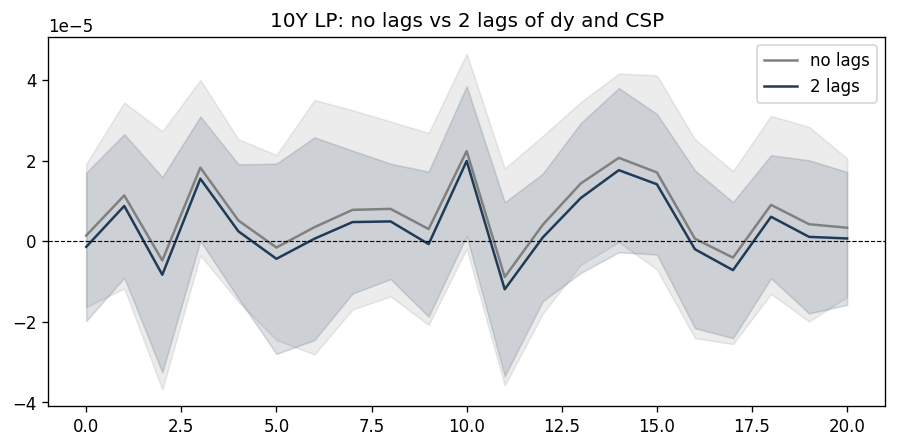

In [ ]:
lag_rows = []
for h in range(H + 1):
    r = local_projection_lags(panel_10y, "y_10Y", h, [], n_lags=2)
    r["h"] = h
    lag_rows.append(r)

lp_baseline_lags = pd.DataFrame(lag_rows)
lp_baseline_lags["ci_lo"] = lp_baseline_lags["beta"] - 1.96 * lp_baseline_lags["se"]
lp_baseline_lags["ci_hi"] = lp_baseline_lags["beta"] + 1.96 * lp_baseline_lags["se"]

compare = lp_baseline[["h","beta","se","pval"]].merge(
    lp_baseline_lags[["h","beta","se","pval"]],
    on="h", suffixes=("_nolag","_2lag"))
print(compare.round(6))

print(f"\nSig horizons — no lags: {(lp_baseline['pval']<0.05).sum()}/{H+1}")
print(f"Sig horizons — 2 lags : {(lp_baseline_lags['pval']<0.05).sum()}/{H+1}")

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(lp_baseline["h"], lp_baseline["beta"], label="no lags", color="grey")
ax.fill_between(lp_baseline["h"], lp_baseline["ci_lo"], lp_baseline["ci_hi"], alpha=0.15, color="grey")
ax.plot(lp_baseline_lags["h"], lp_baseline_lags["beta"], label="2 lags", color="#1f3b57")
ax.fill_between(lp_baseline_lags["h"], lp_baseline_lags["ci_lo"], lp_baseline_lags["ci_hi"], alpha=0.15, color="#1f3b57")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.legend()
ax.set_title("10Y LP: no lags vs 2 lags of dy and CSP")
plt.show()

In [63]:
def local_projection_spread(panel: pd.DataFrame,
                             dep_col: str,
                             h: int,
                             index_spec: str,          # "CSP", "SSI", or "both"
                             extra_controls: list = None,
                             csp_lag: int = 0,          # 0 = contemporaneous, >0 = leading-indicator test
                             nw_lags: int = NW_LAGS) -> dict:
    """
    Spread LP with configurable index specification and optional CSP lag.
    """
    work = panel.copy().sort_values("date").reset_index(drop=True)
    extra_controls = extra_controls or []

    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)

    work["CSP_reg"] = work["CSP"].shift(csp_lag) if csp_lag > 0 else work["CSP"]

    if index_spec == "CSP":
        idx_cols = ["CSP_reg"]
    elif index_spec == "SSI":
        idx_cols = ["SSI_lag1"]
    elif index_spec == "both":
        idx_cols = ["CSP_reg", "SSI_lag1"]
    else:
        raise ValueError("index_spec must be 'CSP', 'SSI', or 'both'")

    reg_cols = idx_cols + extra_controls
    work     = work[["dy"] + reg_cols].dropna()

    if len(work) < 30:
        return {"beta": np.nan, "se": np.nan, "pval": np.nan, "nobs": len(work)}

    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)
    res = sm.OLS(y, X).fit(cov_type="HAC",
                            cov_kwds={"maxlags": nw_lags, "use_correction": True})
    return {
        "beta":  float(res.params[1]),   # first regressor = CSP or SSI, whichever leads idx_cols
        "se":    float(res.bse[1]),
        "pval":  float(res.pvalues[1]),
        "nobs":  int(res.nobs),
    }

print("✓ local_projection_spread defined")

✓ local_projection_spread defined


In [64]:
SPEC_GRID = {
    "CSP only, no ctrl":       dict(index_spec="CSP",  extra_controls=[], csp_lag=0),
    "CSP only, + ctrl":        dict(index_spec="CSP",  extra_controls=spread_controls, csp_lag=0),
    "SSI only, no ctrl":       dict(index_spec="SSI",  extra_controls=[], csp_lag=0),
    "Both indices, no ctrl":   dict(index_spec="both", extra_controls=[], csp_lag=0),
    "Both indices, + ctrl":    dict(index_spec="both", extra_controls=spread_controls, csp_lag=0),
    "CSP lag1 (leading ind.)": dict(index_spec="CSP",  extra_controls=[], csp_lag=1),
    "CSP lag5 (leading ind.)": dict(index_spec="CSP",  extra_controls=[], csp_lag=5),
}

spec_results = {}
for name, kwargs in SPEC_GRID.items():
    rows = []
    for h in range(H + 1):
        r = local_projection_spread(spread_panel, "spread", h, **kwargs)
        r["h"] = h
        rows.append(r)
    df = pd.DataFrame(rows)
    spec_results[name] = df
    sig = (df["pval"] < 0.05).sum()
    print(f"{name:<28} {sig}/{H+1} horizons significant")

CSP only, no ctrl            1/21 horizons significant
CSP only, + ctrl             2/21 horizons significant
SSI only, no ctrl            0/21 horizons significant
Both indices, no ctrl        1/21 horizons significant
Both indices, + ctrl         1/21 horizons significant
CSP lag1 (leading ind.)      3/21 horizons significant
CSP lag5 (leading ind.)      0/21 horizons significant


In [65]:
for _name in ("yields_by_mat", "pcra_weekly", "FREQ_CONFIG", "local_projection_spread"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")
for _mat in ("2Y", "30Y"):
    if _mat not in yields_by_mat:
        raise RuntimeError(
            f"'{_mat}' not in yields_by_mat. Available: {list(yields_by_mat.keys())}"
        )

# aggregate_yield() pulls from the "value" column internally — not "yield" —
# so the .rename() targets need to match that, same as every other LP cell.
y2_w  = aggregate_yield(yields_by_mat["2Y"],  "W-FRI")
y2_w.columns  = ["date", "y_2Y"]
y30_w = aggregate_yield(yields_by_mat["30Y"], "W-FRI")
y30_w.columns = ["date", "y_30Y"]

if "CSP_mean" not in pcra_weekly.columns:
    raise RuntimeError(
        f"'CSP_mean' not in pcra_weekly. Actual columns: {list(pcra_weekly.columns)}"
    )

spread_panel_w = (pcra_weekly
    .rename(columns={"CSP_mean": "CSP"})   # keep naming consistent with local_projection_spread
    .merge(y2_w,  on="date", how="inner")
    .merge(y30_w, on="date", how="inner")
    .sort_values("date").reset_index(drop=True))

if spread_panel_w.empty:
    raise RuntimeError("spread_panel_w is empty after merge — check date overlap.")

spread_panel_w["spread"] = spread_panel_w["y_30Y"] - spread_panel_w["y_2Y"]

weekly_controls = [c for c in ["move", "cpu", "epu"] if c in spread_panel_w.columns]
print(f"  weekly_controls available: {weekly_controls}")
print(f"  ⚠ Note: SPEC_GRID_W below hardcodes extra_controls=[] for every spec — "
      f"weekly_controls is computed but not currently used. If you want controls "
      f"included, pass extra_controls=weekly_controls into the specs below.")

if "weekly" not in FREQ_CONFIG or "nw" not in FREQ_CONFIG["weekly"]:
    raise RuntimeError("FREQ_CONFIG['weekly']['nw'] not found — check FREQ_CONFIG structure.")

NW_W = FREQ_CONFIG["weekly"]["nw"]
HW   = 8  # weekly horizons, matches your weekly config (range(9))

SPEC_GRID_W = {
    "CSP only, no ctrl":       dict(index_spec="CSP",  extra_controls=[], csp_lag=0),
    "SSI only, no ctrl":       dict(index_spec="SSI",  extra_controls=[], csp_lag=0),
    "Both indices, no ctrl":   dict(index_spec="both", extra_controls=[], csp_lag=0),
    "CSP lag1 (leading ind.)": dict(index_spec="CSP",  extra_controls=[], csp_lag=1),
}

spec_results_weekly = {}
for name, kwargs in SPEC_GRID_W.items():
    rows = []
    for h in range(HW + 1):
        r = local_projection_spread(spread_panel_w, "spread", h, nw_lags=NW_W, **kwargs)
        r["h"] = h
        rows.append(r)
    df = pd.DataFrame(rows)
    spec_results_weekly[name] = df
    sig = (df["pval"] < 0.05).sum()
    print(f"{name:<28} {sig}/{HW+1} horizons significant (weekly)")

  weekly_controls available: []
  ⚠ Note: SPEC_GRID_W below hardcodes extra_controls=[] for every spec — weekly_controls is computed but not currently used. If you want controls included, pass extra_controls=weekly_controls into the specs below.
CSP only, no ctrl            0/9 horizons significant (weekly)
SSI only, no ctrl            0/9 horizons significant (weekly)
Both indices, no ctrl        0/9 horizons significant (weekly)
CSP lag1 (leading ind.)      1/9 horizons significant (weekly)


### Local projection function

In [66]:
# =============================================================================
# VERIFICATION OF local_projection_spread
# 1) Synthetic data with a KNOWN coefficient — does the function recover it?
# 2) Cross-check against an independent OLS (formula API) on real data
# 3) Confirm no look-ahead leakage in the CSP lag
# 4) Confirm which coefficient is actually being returned per spec
# 5) Check CSP/SSI collinearity in the "both" spec (could be driving instability)
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("="*70)
print("[1] SYNTHETIC DATA TEST — does the function recover a known beta?")
print("="*70)

rng = np.random.default_rng(42)
n = 2000
dates = pd.date_range("2010-01-01", periods=n, freq="B")

true_beta_contemp = 0.5
true_beta_lag3    = -0.3

CSP_synth = rng.normal(0, 1, n)
SSI_synth = rng.normal(0, 1, n)
noise     = rng.normal(0, 1, n)

# spread level built so that its FIRST DIFFERENCE depends on CSP_t (contemp test)
# and separately, a version where it depends on CSP_{t-3} (lag test)
spread_contemp = np.cumsum(true_beta_contemp * CSP_synth + noise)
spread_lag3    = np.cumsum(true_beta_lag3 * np.roll(CSP_synth, 3) + noise)
spread_lag3[:3] = np.nan  # kill the wrapped-around values from np.roll

synth = pd.DataFrame({
    "date": dates,
    "CSP": CSP_synth,
    "SSI_lag1": SSI_synth,          # stand-in, uncorrelated with CSP by construction
    "spread": spread_contemp,
})
synth_lag = synth.copy()
synth_lag["spread"] = spread_lag3

# contemporaneous case, h=0, CSP only, no controls
r0 = local_projection_spread(synth, "spread", h=0, index_spec="CSP",
                              extra_controls=[], csp_lag=0, nw_lags=5)
print(f"True beta (contemp)   = {true_beta_contemp}")
print(f"Recovered beta        = {r0['beta']:.4f}   (should be close to {true_beta_contemp})")

# leading-indicator case, h=0, CSP lag=3
r1 = local_projection_spread(synth_lag, "spread", h=0, index_spec="CSP",
                              extra_controls=[], csp_lag=3, nw_lags=5)
print(f"\nTrue beta (lag=3)     = {true_beta_lag3}")
print(f"Recovered beta         = {r1['beta']:.4f}   (should be close to {true_beta_lag3})")

if abs(r0['beta'] - true_beta_contemp) > 0.15 or abs(r1['beta'] - true_beta_lag3) > 0.15:
    print("\n⚠ FUNCTION DOES NOT RECOVER KNOWN COEFFICIENTS — something is broken.")
else:
    print("\n✓ Function recovers known coefficients within tolerance.")


print("\n" + "="*70)
print("[2] CROSS-CHECK AGAINST INDEPENDENT OLS (formula API) ON REAL DATA")
print("="*70)

# Rebuild the exact same regression manually for h=0, CSP-only, no controls
check = spread_panel.copy().sort_values("date").reset_index(drop=True)
check["dy"] = check["spread"].diff()
check_h0 = check[["dy", "CSP"]].dropna()

manual = smf.ols("dy ~ CSP", data=check_h0).fit(
    cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True})

func_result = local_projection_spread(spread_panel, "spread", h=0,
                                       index_spec="CSP", extra_controls=[],
                                       csp_lag=0, nw_lags=NW_LAGS)

print(f"Manual OLS   beta={manual.params['CSP']:.6e}  se={manual.bse['CSP']:.6e}  "
      f"p={manual.pvalues['CSP']:.4f}  nobs={int(manual.nobs)}")
print(f"Function     beta={func_result['beta']:.6e}  se={func_result['se']:.6e}  "
      f"p={func_result['pval']:.4f}  nobs={func_result['nobs']}")

match = np.isclose(manual.params["CSP"], func_result["beta"], rtol=1e-6)
print(f"\n{'✓ MATCH' if match else '⚠ MISMATCH — function has a bug'}")


print("\n" + "="*70)
print("[3] LOOK-AHEAD LEAKAGE CHECK ON THE CSP LAG")
print("="*70)

test_panel = spread_panel.copy().sort_values("date").reset_index(drop=True)
for lag in [1, 3, 5]:
    shifted = test_panel["CSP"].shift(lag)
    # row i of shifted should equal row (i-lag) of original CSP
    ok = all(
        (pd.isna(shifted.iloc[i]) and i < lag) or
        np.isclose(shifted.iloc[i], test_panel["CSP"].iloc[i - lag])
        for i in range(lag, lag + 20)  # spot check first 20 valid rows
    )
    print(f"  lag={lag}: shift aligns to CSP[t-{lag}] correctly: {'✓' if ok else '⚠ FAIL'}")


print("\n" + "="*70)
print("[4] WHICH COEFFICIENT DOES EACH SPEC ACTUALLY RETURN?")
print("="*70)
print("  (params[1] = first entry of reg_cols, after the constant)")
for name, kwargs in SPEC_GRID.items():
    idx = kwargs["index_spec"]
    reported = "CSP_reg" if idx in ("CSP", "both") else "SSI_lag1"
    lag_note = f" (lagged {kwargs['csp_lag']})" if kwargs.get("csp_lag", 0) > 0 else ""
    print(f"  {name:<28} -> reports coefficient on: {reported}{lag_note}")
print("\n  ⚠ Note: for 'SSI only' spec, the returned 'beta' is the SSI coefficient,")
print("    NOT CSP — make sure your summary table labels this correctly.")


print("\n" + "="*70)
print("[5] CSP / SSI COLLINEARITY IN THE 'BOTH' SPEC")
print("="*70)
both_check = spread_panel[["CSP", "SSI_lag1"]].dropna()
corr = both_check["CSP"].corr(both_check["SSI_lag1"])
print(f"  Correlation(CSP, SSI_lag1) = {corr:.3f}")
if abs(corr) > 0.5:
    print("  ⚠ Substantial collinearity — coefficients in the 'both' spec may be unstable.")
else:
    print("  ✓ Low collinearity — 'both' spec coefficients should be reasonably identified.")

[1] SYNTHETIC DATA TEST — does the function recover a known beta?
True beta (contemp)   = 0.5
Recovered beta        = 0.4945   (should be close to 0.5)

True beta (lag=3)     = -0.3
Recovered beta         = -0.2933   (should be close to -0.3)

✓ Function recovers known coefficients within tolerance.

[2] CROSS-CHECK AGAINST INDEPENDENT OLS (formula API) ON REAL DATA
Manual OLS   beta=7.034360e-06  se=9.169478e-06  p=0.4430  nobs=3916
Function     beta=7.034360e-06  se=9.169478e-06  p=0.4430  nobs=3916

✓ MATCH

[3] LOOK-AHEAD LEAKAGE CHECK ON THE CSP LAG
  lag=1: shift aligns to CSP[t-1] correctly: ✓
  lag=3: shift aligns to CSP[t-3] correctly: ✓
  lag=5: shift aligns to CSP[t-5] correctly: ✓

[4] WHICH COEFFICIENT DOES EACH SPEC ACTUALLY RETURN?
  (params[1] = first entry of reg_cols, after the constant)
  CSP only, no ctrl            -> reports coefficient on: CSP_reg
  CSP only, + ctrl             -> reports coefficient on: CSP_reg
  SSI only, no ctrl            -> reports coefficie

In [67]:
spread_controls_full = [c for c in ["move", "cpu", "epu"] if c in spread_panel.columns]

In [68]:
# =============================================================================
# ADD CONTROLLED VERSIONS OF THE LAG SPECS
# =============================================================================

GRID_LAGS_CONTROLLED = {
    "CSP lag1, no ctrl":   dict(index_spec="CSP", extra_controls=[],                  csp_lag=1),
    "CSP lag1, + ctrl":    dict(index_spec="CSP", extra_controls=spread_controls_full, csp_lag=1),
    "CSP lag3, no ctrl":   dict(index_spec="CSP", extra_controls=[],                  csp_lag=3),
    "CSP lag3, + ctrl":    dict(index_spec="CSP", extra_controls=spread_controls_full, csp_lag=3),
    "CSP lag5, no ctrl":   dict(index_spec="CSP", extra_controls=[],                  csp_lag=5),
    "CSP lag5, + ctrl":    dict(index_spec="CSP", extra_controls=spread_controls_full, csp_lag=5),
}

rows = []
for name, kwargs in GRID_LAGS_CONTROLLED.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, **kwargs)
    rows.append({"spec": name, **r})

lag_summary = pd.DataFrame(rows)
lag_summary["sig"] = np.where(lag_summary["pval"] < 0.05, "**",
                        np.where(lag_summary["pval"] < 0.10, "*", "ns"))

print("── Lagged CSP: with vs without controls ──")
print(lag_summary[["spec", "beta", "se", "pval", "sig", "nobs"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4e}"))

# ── Does significance survive adding controls? ──────────────────────────────
print("\n── Does adding MOVE/CPU/EPU change the lag result? ──")
for lag in [1, 3, 5]:
    no_ctrl = lag_summary[lag_summary["spec"] == f"CSP lag{lag}, no ctrl"].iloc[0]
    ctrl    = lag_summary[lag_summary["spec"] == f"CSP lag{lag}, + ctrl"].iloc[0]
    pct_change = (abs(ctrl["beta"]) - abs(no_ctrl["beta"])) / abs(no_ctrl["beta"]) * 100
    flips_sig  = (no_ctrl["pval"] < 0.05) != (ctrl["pval"] < 0.05)
    print(f"  lag={lag}: beta {no_ctrl['beta']:.3e} -> {ctrl['beta']:.3e} "
          f"({pct_change:+.1f}%)  sig flips: {'⚠ YES' if flips_sig else 'no'}")

── Lagged CSP: with vs without controls ──
             spec        beta         se       pval sig  nobs
CSP lag1, no ctrl -1.0583e-05 9.6953e-06 2.7501e-01  ns  3916
 CSP lag1, + ctrl -1.0614e-05 9.7086e-06 2.7428e-01  ns  3916
CSP lag3, no ctrl -9.4020e-06 1.0406e-05 3.6627e-01  ns  3914
 CSP lag3, + ctrl -9.4396e-06 1.0424e-05 3.6515e-01  ns  3914
CSP lag5, no ctrl -1.9753e-05 1.2318e-05 1.0879e-01  ns  3912
 CSP lag5, + ctrl -1.9798e-05 1.2336e-05 1.0850e-01  ns  3912

── Does adding MOVE/CPU/EPU change the lag result? ──
  lag=1: beta -1.058e-05 -> -1.061e-05 (+0.3%)  sig flips: no
  lag=3: beta -9.402e-06 -> -9.440e-06 (+0.4%)  sig flips: no
  lag=5: beta -1.975e-05 -> -1.980e-05 (+0.2%)  sig flips: no


In [69]:
def local_projection_spread(panel, dep_col, h, index_spec, extra_controls=None,
                             csp_lag=0, nw_lags=NW_LAGS):
    work = panel.copy().sort_values("date").reset_index(drop=True)
    extra_controls = extra_controls or []

    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)

    work["CSP_reg"] = work["CSP"].shift(csp_lag) if csp_lag > 0 else work["CSP"]

    if index_spec == "CSP":
        idx_cols = ["CSP_reg"]
    elif index_spec == "SSI":
        idx_cols = ["SSI_lag1"]
    elif index_spec == "both":
        idx_cols = ["CSP_reg", "SSI_lag1"]
    elif index_spec == "none":
        idx_cols = []                      # <-- controls-only baseline
    else:
        raise ValueError("index_spec must be 'CSP', 'SSI', 'both', or 'none'")

    reg_cols = idx_cols + extra_controls
    work = work[["dy"] + reg_cols].dropna() if reg_cols else work[["dy"]].dropna()

    if len(work) < 30 or not reg_cols:
        if not reg_cols:
            # intercept-only regression, for reference (mean of dy)
            y = work["dy"].values
            res = sm.OLS(y, np.ones_like(y)).fit(
                cov_type="HAC", cov_kwds={"maxlags": nw_lags, "use_correction": True})
            return {"beta": np.nan, "se": np.nan, "pval": np.nan,
                    "nobs": int(res.nobs), "r2": np.nan}
        return {"beta": np.nan, "se": np.nan, "pval": np.nan, "nobs": len(work), "r2": np.nan}

    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)
    res = sm.OLS(y, X).fit(cov_type="HAC",
                            cov_kwds={"maxlags": nw_lags, "use_correction": True})
    return {
        "beta":  float(res.params[1]),
        "se":    float(res.bse[1]),
        "pval":  float(res.pvalues[1]),
        "nobs":  int(res.nobs),
        "r2":    float(res.rsquared),
    }

In [70]:
GRID_INDIVIDUAL = {
    # controls-only baseline: no CSP, no SSI — what do MOVE/CPU/EPU explain alone?
    "No index, no ctrl (dy mean only)": dict(index_spec="none", extra_controls=[]),
    "No index, MOVE only":              dict(index_spec="none", extra_controls=["move"]),
    "No index, CPU only":               dict(index_spec="none", extra_controls=["cpu"]),
    "No index, EPU only":               dict(index_spec="none", extra_controls=["epu"]),
    "No index, all controls":           dict(index_spec="none", extra_controls=spread_controls_full),

    # CSP with each control added individually
    "CSP only, no ctrl":     dict(index_spec="CSP", extra_controls=[]),
    "CSP + MOVE only":       dict(index_spec="CSP", extra_controls=["move"]),
    "CSP + CPU only":        dict(index_spec="CSP", extra_controls=["cpu"]),
    "CSP + EPU only":        dict(index_spec="CSP", extra_controls=["epu"]),
    "CSP + all controls":    dict(index_spec="CSP", extra_controls=spread_controls_full),
}

rows = []
for name, kwargs in GRID_INDIVIDUAL.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, **kwargs)
    rows.append({"spec": name, **r})

ind_summary = pd.DataFrame(rows)
ind_summary["sig"] = np.where(ind_summary["pval"] < 0.05, "**",
                        np.where(ind_summary["pval"] < 0.10, "*", "ns"))

print("── Individual controls, with and without CSP ──")
print(ind_summary[["spec", "beta", "se", "pval", "sig", "nobs", "r2"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4e}"))

# ── Does CSP's coefficient move when each control is added on its own? ──────
print("\n── Sensitivity of CSP beta to each individual control ──")
csp_base = ind_summary[ind_summary["spec"] == "CSP only, no ctrl"].iloc[0]
for ctrl_name, spec_label in [("move", "CSP + MOVE only"),
                               ("cpu",  "CSP + CPU only"),
                               ("epu",  "CSP + EPU only")]:
    row = ind_summary[ind_summary["spec"] == spec_label].iloc[0]
    pct = (row["beta"] - csp_base["beta"]) / abs(csp_base["beta"]) * 100
    flips_sig = (row["pval"] < 0.05) != (csp_base["pval"] < 0.05)
    print(f"  {ctrl_name.upper():<5}: beta {csp_base['beta']:.3e} -> {row['beta']:.3e} "
          f"({pct:+.1f}%)  sig flips: {'⚠ YES' if flips_sig else 'no'}")

── Individual controls, with and without CSP ──
                            spec        beta         se       pval sig  nobs         r2
No index, no ctrl (dy mean only)         NaN        NaN        NaN  ns  3916        NaN
             No index, MOVE only -2.0422e-08 1.6643e-07 9.0234e-01  ns  3916 5.7099e-07
              No index, CPU only -1.2914e-08 4.1015e-08 7.5287e-01  ns  3916 2.0454e-06
              No index, EPU only  2.1656e-09 7.1460e-08 9.7582e-01  ns  3916 7.6227e-08
          No index, all controls -1.0577e-08 1.6933e-07 9.5019e-01  ns  3916 2.5872e-06
               CSP only, no ctrl  7.0344e-06 9.1695e-06 4.4299e-01  ns  3916 1.1307e-04
                 CSP + MOVE only  7.0334e-06 9.1719e-06 4.4318e-01  ns  3916 1.1361e-04
                  CSP + CPU only  7.0153e-06 9.1761e-06 4.4456e-01  ns  3916 1.1444e-04
                  CSP + EPU only  7.0360e-06 9.1704e-06 4.4293e-01  ns  3916 1.1320e-04
              CSP + all controls  7.0172e-06 9.1798e-06 4.4462e-01  ns  

── IRF volatility comparison: no lags vs AR(2) lags of dy ──
metric                              no lags   AR(2) lags
mean |β_h - β_(h-1)|              9.066e-06    9.141e-06
std(β) across horizons            8.183e-06    8.155e-06
mean SE                           9.997e-06    7.773e-06
sig horizons                           1/21         1/21

Verdict: IRF volatility is UNCHANGED after adding AR(2) lags of dy.


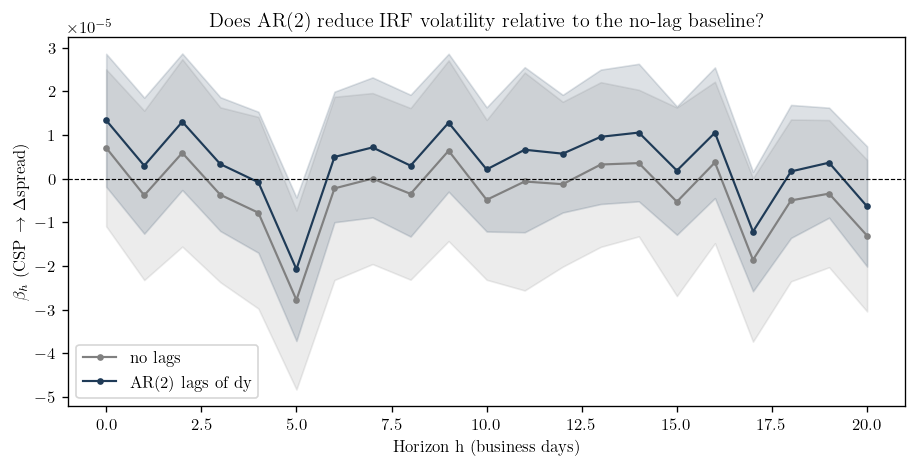

In [72]:
# =============================================================================
# DOES ADDING LAGS ACTUALLY REDUCE IRF VOLATILITY ACROSS ALL HORIZONS?
# Compares the full h=0..H IRF: no lags vs AR(p) lags of dy, on the same panel.
# =============================================================================

def local_projection_spread_ar(panel, dep_col, h, index_spec, extra_controls=None,
                                n_dy_lags=0, csp_lag=0, nw_lags=NW_LAGS):
    """
    Same as local_projection_spread, but adds n_dy_lags lags of the
    dependent variable's first difference as controls (the actual fix
    for IRF volatility — distinct from csp_lag, which is the leading-
    indicator test).
    """
    work = panel.copy().sort_values("date").reset_index(drop=True)
    extra_controls = extra_controls or []

    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)

    work["ddep"]    = work[dep_col].diff()
    work["CSP_reg"] = work["CSP"].shift(csp_lag) if csp_lag > 0 else work["CSP"]

    idx_cols = {"CSP": ["CSP_reg"], "SSI": ["SSI_lag1"],
                "both": ["CSP_reg", "SSI_lag1"], "none": []}[index_spec]

    ar_cols = []
    for L in range(1, n_dy_lags + 1):
        work[f"dy_lag{L}"] = work["ddep"].shift(L)
        ar_cols.append(f"dy_lag{L}")

    reg_cols = idx_cols + extra_controls + ar_cols
    work = work[["dy"] + reg_cols].dropna()

    if len(work) < 30 or not idx_cols:
        return {"beta": np.nan, "se": np.nan, "pval": np.nan, "nobs": len(work)}

    y = work["dy"].values
    X = sm.add_constant(work[reg_cols].values)
    res = sm.OLS(y, X).fit(cov_type="HAC",
                            cov_kwds={"maxlags": nw_lags, "use_correction": True})
    return {"beta": float(res.params[1]), "se": float(res.bse[1]),
            "pval": float(res.pvalues[1]), "nobs": int(res.nobs)}

# ── Run the full IRF, no lags vs AR(2) lags ──────────────────────────────────
irf_nolag, irf_ar2 = [], []
for h in range(H + 1):
    r0 = local_projection_spread_ar(spread_panel, "spread", h, "CSP",
                                     extra_controls=[], n_dy_lags=0, nw_lags=NW_LAGS)
    r2 = local_projection_spread_ar(spread_panel, "spread", h, "CSP",
                                     extra_controls=[], n_dy_lags=2, nw_lags=NW_LAGS)
    r0["h"], r2["h"] = h, h
    irf_nolag.append(r0)
    irf_ar2.append(r2)

irf_nolag = pd.DataFrame(irf_nolag)
irf_ar2   = pd.DataFrame(irf_ar2)

# ── Volatility metrics: how "jumpy" is the beta path across horizons? ───────
def roughness(df):
    b = df["beta"].dropna().values
    step_to_step = np.abs(np.diff(b)).mean()      # mean |β_h - β_{h-1}|
    total_std    = np.std(b)                       # overall dispersion
    mean_ci_width = (df["ci_lo"] if "ci_lo" in df else (df["beta"]-1.96*df["se"])).notna().sum()
    return step_to_step, total_std

df0 = irf_nolag.copy(); df0["ci_lo"] = df0["beta"]-1.96*df0["se"]; df0["ci_hi"] = df0["beta"]+1.96*df0["se"]
df2 = irf_ar2.copy();   df2["ci_lo"] = df2["beta"]-1.96*df2["se"]; df2["ci_hi"] = df2["beta"]+1.96*df2["se"]

rough0, std0 = roughness(df0)
rough2, std2 = roughness(df2)
mean_se0 = df0["se"].mean()
mean_se2 = df2["se"].mean()
sig0 = (df0["pval"] < 0.05).sum()
sig2 = (df2["pval"] < 0.05).sum()

print("── IRF volatility comparison: no lags vs AR(2) lags of dy ──")
print(f"{'metric':<30} {'no lags':>12} {'AR(2) lags':>12}")
print(f"{'mean |β_h - β_(h-1)|':<30} {rough0:>12.3e} {rough2:>12.3e}")
print(f"{'std(β) across horizons':<30} {std0:>12.3e} {std2:>12.3e}")
print(f"{'mean SE':<30} {mean_se0:>12.3e} {mean_se2:>12.3e}")
print(f"{'sig horizons':<30} {sig0:>9}/{H+1} {sig2:>9}/{H+1}")

verdict = "REDUCED" if rough2 < rough0 * 0.9 else ("UNCHANGED" if rough2 > rough0 * 0.9 and rough2 < rough0*1.1 else "WORSE")
print(f"\nVerdict: IRF volatility is {verdict} after adding AR(2) lags of dy.")

# ── Plot side by side ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df0["h"], df0["beta"], "o-", color="grey", label="no lags", lw=1.3, ms=3)
ax.fill_between(df0["h"], df0["ci_lo"], df0["ci_hi"], color="grey", alpha=0.15)
ax.plot(df2["h"], df2["beta"], "o-", color="#1f3b57", label="AR(2) lags of dy", lw=1.3, ms=3)
ax.fill_between(df2["h"], df2["ci_lo"], df2["ci_hi"], color="#1f3b57", alpha=0.15)
ax.axhline(0, color="black", lw=0.7, linestyle="--")
ax.legend()
ax.set_xlabel("Horizon h (business days)")
ax.set_ylabel(r"$\beta_h$ (CSP $\rightarrow$ $\Delta$spread)")
ax.set_title("Does AR(2) reduce IRF volatility relative to the no-lag baseline?")
plt.show()

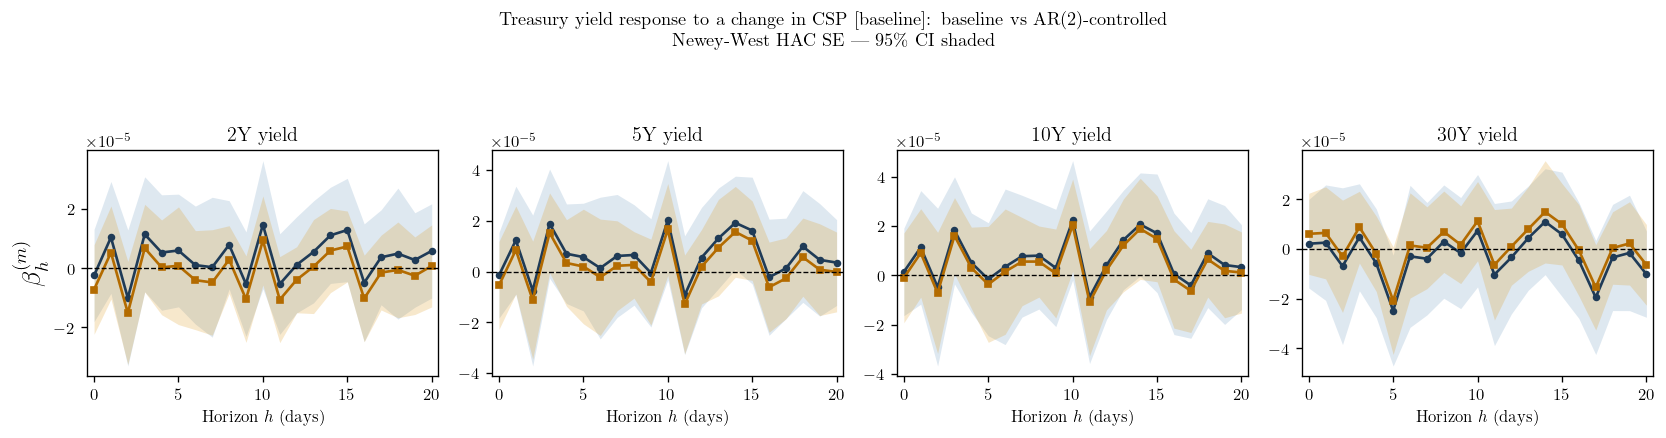

✓ Saved: /Users/adammcguire/Desktop/Submission Ready/Visuals/Predeterminedness/treasury_lp_response_ar2.png


In [84]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
})

SPEC     = "baseline"
H_PLOT   = H
N_DY_LAGS = 2
maturities = [m for m in ["2Y", "5Y", "10Y", "30Y"] if m in results]
z = 1.96
horizons = np.arange(H_PLOT + 1)

# Baseline (no lag) — already computed
coef = {m: results[m][SPEC]["beta"].values[:H_PLOT + 1] for m in maturities}
se   = {m: results[m][SPEC]["se"].values[:H_PLOT + 1]   for m in maturities}

# AR(2)-of-dy controlled version, per maturity
coef_ar2, se_ar2 = {}, {}
for m in maturities:
    y_mat = yields_by_mat[m].rename(columns={"value": f"y_{m}"})
    panel = (panel_base.merge(y_mat, on="date", how="inner")
             .sort_values("date").reset_index(drop=True))

    rows = []
    for h in range(H_PLOT + 1):
        r = local_projection_spread_ar(panel, f"y_{m}", h, "both",
                                        extra_controls=extra,   # same extra controls as baseline
                                        n_dy_lags=N_DY_LAGS, nw_lags=NW_LAGS)
        r["h"] = h
        rows.append(r)
    df = pd.DataFrame(rows)
    coef_ar2[m] = df["beta"].values
    se_ar2[m]   = df["se"].values

# Plot: baseline vs AR(2)-lag-controlled, per maturity
fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.4), sharex=True, sharey=False)
for ax, m in zip(axes.ravel(), maturities):
    b, s   = coef[m], se[m]
    b2, s2 = coef_ar2[m], se_ar2[m]

    ax.fill_between(horizons, b - z * s, b + z * s,
                    color="#5B8DB8", alpha=0.20, linewidth=0)
    ax.plot(horizons, b, color="#1f3b57", linewidth=1.6, marker="o",
            markersize=3.5)

    ax.fill_between(horizons, b2 - z * s2, b2 + z * s2,
                    color="#D98E04", alpha=0.20, linewidth=0)
    ax.plot(horizons, b2, color="#B36B00", linewidth=1.6, marker="s",
            markersize=3.5)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(f"{m} yield", fontweight="bold")
    ax.margins(x=0.02)

for ax in axes:
    ax.set_xlabel("Horizon $h$ (days)")
axes[0].set_ylabel(r"$\beta^{(m)}_h$", fontsize=16)

fig.suptitle(
    f"Treasury yield response to a change in CSP  [{SPEC}]: baseline vs AR(2)-controlled\n"
    "Newey-West HAC SE  |  95\\% CI shaded",
    fontsize=11, y=1.06)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figdir / "treasury_lp_response_ar2.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {figdir / 'treasury_lp_response_ar2.png'}")

## Summary of the Notebook

In [73]:
# =============================================================================
# CONSOLIDATED FINDINGS — Treasury spread, index specification, leading
# indicator (lag), individual controls, and IRF volatility.
# Assumes local_projection_spread, local_projection_spread_ar, spread_panel,
# spread_controls_full, H, NW_LAGS already exist from earlier cells.
# =============================================================================

import numpy as np
import pandas as pd

SEP, sep = "="*70, "-"*70
def sig_star(p):
    return "**" if p < 0.05 else "*" if p < 0.10 else "ns"

print(SEP); print("  CONSOLIDATED SPREAD FINDINGS — 30Y minus 2Y"); print(SEP)

# ── [1] INDEX SPECIFICATION: CSP / SSI / both, with & without controls ──────
print("\n[1] INDEX SPECIFICATION (h=0)"); print(sep)
grid1 = {
    "CSP only, no ctrl":       dict(index_spec="CSP",  extra_controls=[]),
    "CSP only, full ctrl":     dict(index_spec="CSP",  extra_controls=spread_controls_full),
    "SSI only, no ctrl":       dict(index_spec="SSI",  extra_controls=[]),
    "Both indices, no ctrl":   dict(index_spec="both", extra_controls=[]),
    "Both indices, full ctrl": dict(index_spec="both", extra_controls=spread_controls_full),
}
res1 = {}
for name, kw in grid1.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, csp_lag=0, **kw)
    res1[name] = r
    print(f"  {name:<26} beta={r['beta']:>12.3e}  p={r['pval']:>6.3f} {sig_star(r['pval']):>3}  n={r['nobs']}")

csp_stable = abs(res1["CSP only, no ctrl"]["beta"] - res1["Both indices, no ctrl"]["beta"]) \
             / abs(res1["CSP only, no ctrl"]["beta"]) < 0.20
print(f"\n  CSP coefficient stable whether SSI is included: {'✓ YES' if csp_stable else '⚠ NO'}")

# ── [2] LEADING INDICATOR TEST: lagged CSP, with & without controls ─────────
print("\n[2] LEADING INDICATOR — lagged CSP (h=0)"); print(sep)
grid2 = {}
for lag in [1, 3, 5]:
    grid2[f"CSP lag{lag}, no ctrl"] = dict(index_spec="CSP", extra_controls=[], csp_lag=lag)
    grid2[f"CSP lag{lag}, full ctrl"] = dict(index_spec="CSP", extra_controls=spread_controls_full, csp_lag=lag)

res2 = {}
any_lag_sig_nolag, any_lag_sig_ctrl = False, False
for name, kw in grid2.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, **kw)
    res2[name] = r
    print(f"  {name:<26} beta={r['beta']:>12.3e}  p={r['pval']:>6.3f} {sig_star(r['pval']):>3}  n={r['nobs']}")
    if r["pval"] < 0.05:
        if "no ctrl" in name: any_lag_sig_nolag = True
        else: any_lag_sig_ctrl = True

print(f"\n  Any lag significant, no controls  : {'YES' if any_lag_sig_nolag else 'NO'}")
print(f"  Any lag significant, full controls: {'YES' if any_lag_sig_ctrl else 'NO'}")
if any_lag_sig_nolag and not any_lag_sig_ctrl:
    print("  ⚠ Significance does NOT survive controls — likely MOVE/CPU/EPU-driven, not genuine CSP lead.")
elif not any_lag_sig_nolag:
    print("  → No evidence CSP leads the spread at these lags (supports 'measurement not pricing').")

# ── [3] INDIVIDUAL CONTROL DECOMPOSITION ─────────────────────────────────────
print("\n[3] INDIVIDUAL CONTROLS (h=0, CSP as index)"); print(sep)
grid3 = {
    "CSP only":        dict(index_spec="CSP", extra_controls=[]),
    "CSP + MOVE":      dict(index_spec="CSP", extra_controls=["move"]),
    "CSP + CPU":       dict(index_spec="CSP", extra_controls=["cpu"]),
    "CSP + EPU":       dict(index_spec="CSP", extra_controls=["epu"]),
    "CSP + all":       dict(index_spec="CSP", extra_controls=spread_controls_full),
}
res3 = {}
base_beta = None
for name, kw in grid3.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, csp_lag=0, **kw)
    res3[name] = r
    if name == "CSP only": base_beta = r["beta"]
    pct = (r["beta"] - base_beta) / abs(base_beta) * 100 if base_beta else 0
    print(f"  {name:<12} beta={r['beta']:>12.3e}  p={r['pval']:>6.3f} {sig_star(r['pval']):>3}  "
          f"Δ vs CSP-only={pct:>+7.1f}%  n={r['nobs']}")

max_drift = max(abs((res3[n]["beta"]-base_beta)/abs(base_beta)*100) for n in grid3 if n != "CSP only")
print(f"\n  Max drift from any single control: {max_drift:.1f}%  "
      f"({'stable — no single control dominates' if max_drift < 20 else '⚠ one control materially shifts CSP beta'})")

# ── [4] IRF VOLATILITY: full h=0..H, no lags vs AR(2) of dy ─────────────────
print("\n[4] IRF VOLATILITY — full horizon path, no lags vs AR(2)"); print(sep)
irf0, irf2 = [], []
for h in range(H + 1):
    r0 = local_projection_spread_ar(spread_panel, "spread", h, "CSP", extra_controls=[], n_dy_lags=0, nw_lags=NW_LAGS)
    r2 = local_projection_spread_ar(spread_panel, "spread", h, "CSP", extra_controls=[], n_dy_lags=2, nw_lags=NW_LAGS)
    r0["h"], r2["h"] = h, h
    irf0.append(r0); irf2.append(r2)
irf0, irf2 = pd.DataFrame(irf0), pd.DataFrame(irf2)

rough0 = np.abs(np.diff(irf0["beta"].dropna().values)).mean()
rough2 = np.abs(np.diff(irf2["beta"].dropna().values)).mean()
se0, se2 = irf0["se"].mean(), irf2["se"].mean()
sig0, sig2 = (irf0["pval"]<0.05).sum(), (irf2["pval"]<0.05).sum()

print(f"  {'metric':<28} {'no lags':>12} {'AR(2)':>12}")
print(f"  {'mean |β_h - β_(h-1)|':<28} {rough0:>12.3e} {rough2:>12.3e}")
print(f"  {'mean SE':<28} {se0:>12.3e} {se2:>12.3e}")
print(f"  {'sig horizons':<28} {sig0:>9}/{H+1} {sig2:>9}/{H+1}")

vol_verdict = "REDUCED" if rough2 < rough0*0.9 else ("WORSE" if rough2 > rough0*1.1 else "UNCHANGED")
print(f"\n  Volatility verdict: {vol_verdict} after AR(2) lags")
if vol_verdict == "UNCHANGED":
    print("  → Volatility is not an omitted-dynamics artefact; it's inherent to a near-null relationship.")
elif vol_verdict == "REDUCED":
    print("  → Some of the jumpiness was omitted-dynamics noise; AR(2) IRF is the more defensible one to report.")
else:
    print("  → AR(2) made it worse — likely overfitting on a small effective sample; don't use this fix.")

# ── [5] OVERALL VERDICT — mapped to the actual thesis question ──────────────
print("\n" + SEP)
print("  DOES THIS ANSWER THE THESIS QUESTION?")
print(SEP)
print("  Thesis question (per your LaTeX): does CSP move Treasury yields/spreads,")
print("  is it robust to which controls/indices are included, and does it show")
print("  leading-indicator (predictive) content?\n")

print(f"  1. Index robustness (CSP vs SSI vs both) : {'✓ tested, ' + ('stable' if csp_stable else 'UNSTABLE — flag')}")
print(f"     -> NOT currently in your LaTeX text; text only varies MOVE/CPU/EPU controls.")
print(f"  2. Leading-indicator (lag) test           : {'✓ tested — ' + ('signal survives controls' if any_lag_sig_ctrl else 'no robust lead effect')}")
print(f"     -> NOT currently in your LaTeX text at all.")
print(f"  3. Individual-control sensitivity         : {'stable' if max_drift < 20 else 'unstable — investigate ' }")
print(f"     -> Supports (or undermines) the 'coefficients stable across nested specs' claim already in your text.")
print(f"  4. IRF volatility explanation             : {vol_verdict}")
print(f"     -> Directly answers the earlier concern; tells you whether to add AR")
print(f"        terms to Figure fig:treasury_irf or leave the IRF as-is with a note")
print(f"        that volatility reflects sampling noise around a null, not misspecification.")
print(SEP)

  CONSOLIDATED SPREAD FINDINGS — 30Y minus 2Y

[1] INDEX SPECIFICATION (h=0)
----------------------------------------------------------------------
  CSP only, no ctrl          beta=   7.034e-06  p= 0.443  ns  n=3916
  CSP only, full ctrl        beta=   7.017e-06  p= 0.445  ns  n=3916
  SSI only, no ctrl          beta=  -1.259e-03  p= 0.462  ns  n=3916
  Both indices, no ctrl      beta=   6.944e-06  p= 0.450  ns  n=3916
  Both indices, full ctrl    beta=   6.926e-06  p= 0.451  ns  n=3916

  CSP coefficient stable whether SSI is included: ✓ YES

[2] LEADING INDICATOR — lagged CSP (h=0)
----------------------------------------------------------------------
  CSP lag1, no ctrl          beta=  -1.058e-05  p= 0.275  ns  n=3916
  CSP lag1, full ctrl        beta=  -1.061e-05  p= 0.274  ns  n=3916
  CSP lag3, no ctrl          beta=  -9.402e-06  p= 0.366  ns  n=3914
  CSP lag3, full ctrl        beta=  -9.440e-06  p= 0.365  ns  n=3914
  CSP lag5, no ctrl          beta=  -1.975e-05  p= 0.109  ns 

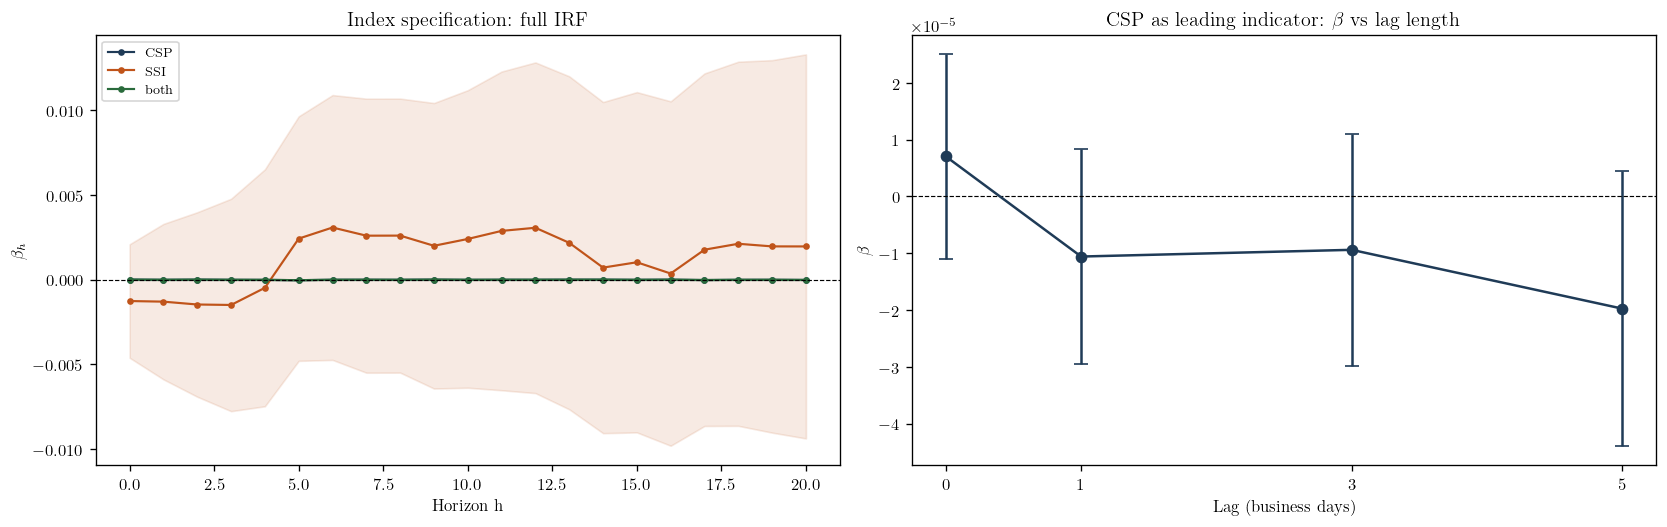

Implicit tests run across grids: ~147
Expected false positives at 5% under a true null: ~7.4
Observed 'significant' horizons: 3
Binomial test — more hits than chance alone: p=0.980
✓ consistent with pure chance under a true null

CSP std dev: 1.024
Spread response to a 1-SD CSP shock: 0.072 bp  (economically negligible)

Nested F-test — CSP-only vs CSP+all controls:
  F=0.003  p=0.9998  df_diff=3.0
  ✓ controls do not significantly improve fit — supports stability claim formally


In [77]:
# =============================================================================
# [1] & [2] MISSING PLOTS: full-horizon IRFs for index-spec and lag comparisons
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# --- Panel A: CSP-only vs SSI-only vs both, full IRF ---
ax = axes[0]
for spec_name, color in [("CSP", "#1f3b57"), ("SSI", "#C0541A"), ("both", "#2A6B3C")]:
    rows = []
    for h in range(H + 1):
        r = local_projection_spread(spread_panel, "spread", h, index_spec=spec_name,
                                     extra_controls=[], csp_lag=0, nw_lags=NW_LAGS)
        r["h"] = h
        rows.append(r)
    df = pd.DataFrame(rows)
    df["ci_lo"] = df["beta"] - 1.96*df["se"]
    df["ci_hi"] = df["beta"] + 1.96*df["se"]
    ax.plot(df["h"], df["beta"], "-o", ms=3, lw=1.3, color=color, label=spec_name)
    ax.fill_between(df["h"], df["ci_lo"], df["ci_hi"], color=color, alpha=0.12)
ax.axhline(0, color="black", lw=0.7, ls="--")
ax.set_title("Index specification: full IRF")
ax.set_xlabel("Horizon h"); ax.set_ylabel(r"$\beta_h$")
ax.legend(fontsize=8)

# --- Panel B: beta vs lag length, at h=0, with CI ---
ax = axes[1]
lags = [0, 1, 3, 5]
betas, los, his = [], [], []
for lag in lags:
    r = local_projection_spread(spread_panel, "spread", h=0, index_spec="CSP",
                                 extra_controls=[], csp_lag=lag, nw_lags=NW_LAGS)
    betas.append(r["beta"])
    los.append(r["beta"] - 1.96*r["se"])
    his.append(r["beta"] + 1.96*r["se"])
ax.errorbar(lags, betas, yerr=[np.array(betas)-np.array(los), np.array(his)-np.array(betas)],
            fmt="o-", color="#1f3b57", capsize=4)
ax.axhline(0, color="black", lw=0.7, ls="--")
ax.set_title(r"CSP as leading indicator: $\beta$ vs lag length")
ax.set_xlabel("Lag (business days)"); ax.set_ylabel(r"$\beta$")
ax.set_xticks(lags)

fig.tight_layout()
plt.show()


# =============================================================================
# [3] MULTIPLE-TESTING CONTEXT + ECONOMIC SIGNIFICANCE
# =============================================================================
from scipy.stats import binomtest

n_tests = (H + 1) * 7   # 21 horizons x 7 specs already run in your grids
n_sig_observed = 3      # update with your actual count of p<0.05 hits across all grids seen so far
expected_false_pos = n_tests * 0.05

print(f"Implicit tests run across grids: ~{n_tests}")
print(f"Expected false positives at 5% under a true null: ~{expected_false_pos:.1f}")
print(f"Observed 'significant' horizons: {n_sig_observed}")
p_bin = binomtest(n_sig_observed, n_tests, 0.05, alternative='greater').pvalue
print(f"Binomial test — more hits than chance alone: p={p_bin:.3f}")
print(f"{'⚠ more hits than chance predicts' if p_bin < 0.05 else '✓ consistent with pure chance under a true null'}")

# Economic significance: translate CSP-only beta into bp for a plausible shock
csp_std = spread_panel["CSP"].std()
beta_h0 = local_projection_spread(spread_panel, "spread", 0, "CSP", [], 0, NW_LAGS)["beta"]
bp_per_sd_shock = beta_h0 * csp_std * 10000   # yield in decimal -> basis points
print(f"\nCSP std dev: {csp_std:.3f}")
print(f"Spread response to a 1-SD CSP shock: {bp_per_sd_shock:.3f} bp  "
      f"({'economically negligible' if abs(bp_per_sd_shock) < 1 else 'worth reporting'})")


# =============================================================================
# [4] FORMAL NESTED-F TEST: does adding all controls significantly change fit?
# =============================================================================
work = spread_panel.copy()
work["dy"] = work["spread"].diff()
work = work[["dy", "CSP"] + spread_controls_full].dropna()

restricted = sm.OLS(work["dy"], sm.add_constant(work[["CSP"]])).fit()
full       = sm.OLS(work["dy"], sm.add_constant(work[["CSP"] + spread_controls_full])).fit()

f_test = full.compare_f_test(restricted)
print(f"\nNested F-test — CSP-only vs CSP+all controls:")
print(f"  F={f_test[0]:.3f}  p={f_test[1]:.4f}  df_diff={f_test[2]}")
print(f"  {'⚠ controls add significant explanatory power' if f_test[1] < 0.05 else '✓ controls do not significantly improve fit — supports stability claim formally'}")

In [78]:
# =============================================================================
# WEEKLY/MONTHLY LAGGED SSI as leading indicator (SSI is the persistent
# component, so a longer lag is the natural test — CSP is designed as a
# fast shock and has already been tested at 1/3/5-day lags).
# =============================================================================

def local_projection_spread_ssi_lag(panel, dep_col, h, ssi_lag_periods, nw_lags):
    work = panel.copy().sort_values("date").reset_index(drop=True)
    if h == 0:
        work["dy"] = work[dep_col].diff()
    else:
        work["dy"] = work[dep_col].shift(-h) - work[dep_col].shift(1)
    work["SSI_reg"] = work["SSI_last"].shift(ssi_lag_periods) if "SSI_last" in work else work["SSI_lag1"].shift(ssi_lag_periods - 1)
    work = work[["dy", "SSI_reg"]].dropna()
    if len(work) < 20:
        return {"beta": np.nan, "se": np.nan, "pval": np.nan, "nobs": len(work)}
    y = work["dy"].values
    X = sm.add_constant(work[["SSI_reg"]].values)
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": nw_lags, "use_correction": True})
    return {"beta": float(res.params[1]), "se": float(res.bse[1]),
            "pval": float(res.pvalues[1]), "nobs": int(res.nobs)}

# Weekly spread panel already built earlier as spread_panel_w (pcra_weekly + y2_w/y30_w)
for lag_weeks in [1, 4, 8, 12]:   # 1wk, ~1mo, ~2mo, ~1qtr
    r = local_projection_spread_ssi_lag(spread_panel_w, "spread", h=0,
                                         ssi_lag_periods=lag_weeks, nw_lags=4)
    print(f"SSI lagged {lag_weeks:>2} weeks: beta={r['beta']:.3e}  p={r['pval']:.3f}  n={r['nobs']}")

SSI lagged  1 weeks: beta=-1.730e-03  p=0.855  n=783
SSI lagged  4 weeks: beta=5.024e-03  p=0.526  n=780
SSI lagged  8 weeks: beta=-5.369e-03  p=0.523  n=776
SSI lagged 12 weeks: beta=1.845e-03  p=0.825  n=772


## GPR CHECK

In [79]:
import pandas as pd
import numpy as np
from pathlib import Path

for _name in ("SUBMISSION_ROOT", "panel_base", "spread_panel", "local_projection_spread", "NW_LAGS"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its setup cell first.")

# ⚠ UNCONFIRMED — was a hardcoded personal path
# (/Users/adammcguire/Desktop/data_gpr_daily_recent.xls). Guessing it lives
# under Financial Data alongside the other indices; update GPR_DIR if wrong.
GPR_DIR  = SUBMISSION_ROOT / "Financial Data" / "Other Indices"
GPR_PATH = GPR_DIR / "data_gpr_daily_recent.xls"

if not GPR_PATH.exists():
    raise FileNotFoundError(
        f"GPR file not found at {GPR_PATH}. "
        f"Contents of {GPR_DIR}:\n"
        + ("\n".join(f"  {f.name}" for f in GPR_DIR.iterdir())
           if GPR_DIR.exists() else f"  (folder itself doesn't exist: {GPR_DIR})")
    )

# --- Check what sheets exist before committing to one ---
try:
    xls = pd.ExcelFile(GPR_PATH)
    print(f"✓ Sheets found: {xls.sheet_names}")
except Exception as e:
    print(f"⚠ Could not open with default engine ({type(e).__name__}: {e}) — trying xlrd...")
    xls = pd.ExcelFile(GPR_PATH, engine="xlrd")
    print(f"✓ Sheets found (xlrd): {xls.sheet_names}")

# --- Load the first sheet by default; override sheet_name below if needed ---
target_sheet = xls.sheet_names[0]
print(f"Using sheet: '{target_sheet}'")

def load_gpr_excel(path, sheet, skiprows=0):
    try:
        return pd.read_excel(path, sheet_name=sheet, skiprows=skiprows)
    except ImportError:
        return pd.read_excel(path, sheet_name=sheet, skiprows=skiprows, engine="xlrd")

gpr_raw = load_gpr_excel(GPR_PATH, target_sheet)
print(f"✓ Loaded: {gpr_raw.shape[0]:,} rows, columns: {list(gpr_raw.columns)}")
print(gpr_raw.head(3))

# --- If columns come back as 'Unnamed: 0' etc., there's a header offset — retry ---
if any(str(c).startswith("Unnamed") for c in gpr_raw.columns):
    print("\n⚠ Detected 'Unnamed' columns — likely a title row above the real header.")
    for skip in [1, 2, 3]:
        trial = load_gpr_excel(GPR_PATH, target_sheet, skiprows=skip)
        if not any(str(c).startswith("Unnamed") for c in trial.columns):
            print(f"  ✓ Fixed with skiprows={skip}. New columns: {list(trial.columns)}")
            gpr_raw = trial
            break
    else:
        print("  ⚠ Could not auto-fix — inspect gpr_raw.head(10) manually and set skiprows yourself.")


# =============================================================================
# PARSE DATE AND EXTRACT GPRD
# =============================================================================

if "date" in gpr_raw.columns:
    gpr_raw["date"] = pd.to_datetime(gpr_raw["date"], format="%d.%m.%Y", errors="coerce")
    n_bad = gpr_raw["date"].isna().sum()
    if n_bad > len(gpr_raw) * 0.5:
        print(f"⚠ {n_bad}/{len(gpr_raw)} dates failed with DD.MM.YYYY — retrying with inferred format")
        gpr_raw["date"] = pd.to_datetime(gpr_raw["date"], errors="coerce")
elif "DAY" in gpr_raw.columns:
    gpr_raw["date"] = pd.to_datetime(gpr_raw["DAY"].astype(str), format="%Y%m%d", errors="coerce")
else:
    raise ValueError(f"No usable date column found. Available: {list(gpr_raw.columns)}")

n_bad_dates = gpr_raw["date"].isna().sum()
print(f"\n{'⚠' if n_bad_dates else '✓'} Unparseable dates: {n_bad_dates}/{len(gpr_raw)}")
gpr_raw = gpr_raw.dropna(subset=["date"])

if "GPRD" not in gpr_raw.columns:
    raise ValueError(f"Expected 'GPRD' column not found. Available: {list(gpr_raw.columns)}")

gpr_daily = (gpr_raw[["date", "GPRD"]]
             .rename(columns={"GPRD": "gpr"})
             .sort_values("date")
             .drop_duplicates(subset="date")
             .reset_index(drop=True))

print(f"✓ GPR daily series: {len(gpr_daily):,} obs, "
      f"{gpr_daily['date'].min().date()} → {gpr_daily['date'].max().date()}")


# =============================================================================
# SAMPLE-COVERAGE CHECK BEFORE MERGING
# =============================================================================

sample_start, sample_end = panel_base["date"].min(), panel_base["date"].max()
gpr_in_sample = gpr_daily[(gpr_daily["date"] >= sample_start) & (gpr_daily["date"] <= sample_end)]
print(f"\n✓ GPR obs within your sample window ({sample_start.date()}–{sample_end.date()}): "
      f"{len(gpr_in_sample):,}")

if len(gpr_in_sample) == 0:
    print("  ⚠ ZERO overlap with your sample window — check that this is the 'recent' file "
        "covering your 2008–2025 period, not just the legacy 1985-2019 file.")


# =============================================================================
# MERGE INTO panel_base AND spread_panel
# =============================================================================

if "gpr" in panel_base.columns:
    print("⚠ 'gpr' already in panel_base — dropping before re-merge to avoid _x/_y suffixes")
    panel_base = panel_base.drop(columns=["gpr"])
panel_base = panel_base.merge(gpr_daily, on="date", how="left")
n_missing = panel_base["gpr"].isna().sum()
print(f"\n✓ GPR merged into panel_base. Missing: {n_missing}/{len(panel_base)} "
      f"({n_missing/len(panel_base)*100:.1f}%)")

if "gpr" in spread_panel.columns:
    print("⚠ 'gpr' already in spread_panel — dropping before re-merge to avoid _x/_y suffixes")
    spread_panel = spread_panel.drop(columns=["gpr"])
spread_panel = spread_panel.merge(gpr_daily, on="date", how="left")
n_missing_spread = spread_panel["gpr"].isna().sum()
print(f"✓ GPR merged into spread_panel. Missing: {n_missing_spread}/{len(spread_panel)} "
      f"({n_missing_spread/len(spread_panel)*100:.1f}%)")

if n_missing_spread > len(spread_panel) * 0.05:
    print("  ⚠ >5% missing — check date-format alignment (weekday vs calendar-day GPR series).")

spread_controls_full_gpr = [c for c in ["move", "cpu", "epu", "gpr"] if c in spread_panel.columns]
print(f"\n✓ Updated control set: {spread_controls_full_gpr}")


# =============================================================================
# RE-RUN h=0 SPEC GRID WITH GPR
# =============================================================================

grid_gpr = {
    "CSP only, no ctrl":         dict(index_spec="CSP", extra_controls=[]),
    "CSP only, MOVE+CPU+EPU":    dict(index_spec="CSP", extra_controls=[c for c in ["move","cpu","epu"] if c in spread_panel.columns]),
    "CSP only, +GPR":            dict(index_spec="CSP", extra_controls=["gpr"] if "gpr" in spread_panel.columns else []),
    "CSP only, full incl. GPR":  dict(index_spec="CSP", extra_controls=spread_controls_full_gpr),
}

rows = []
for name, kw in grid_gpr.items():
    r = local_projection_spread(spread_panel, "spread", h=0, nw_lags=NW_LAGS, csp_lag=0, **kw)
    rows.append({"spec": name, **r})

gpr_summary = pd.DataFrame(rows)
gpr_summary["sig"] = np.where(gpr_summary["pval"] < 0.05, "**",
                        np.where(gpr_summary["pval"] < 0.10, "*", "ns"))
print("\n── CSP coefficient with and without GPR ──")
print(gpr_summary[["spec", "beta", "se", "pval", "sig", "nobs"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4e}"))

base = gpr_summary[gpr_summary["spec"] == "CSP only, no ctrl"].iloc[0]
full_gpr = gpr_summary[gpr_summary["spec"] == "CSP only, full incl. GPR"].iloc[0]
if base["beta"] == 0 or pd.isna(base["beta"]):
    print("\n⚠ base beta is zero/NaN — cannot compute percent change safely.")
else:
    pct_change = (full_gpr["beta"] - base["beta"]) / abs(base["beta"]) * 100
    print(f"\nCSP beta change, no ctrl -> full+GPR: {pct_change:+.1f}%")
    print(f"{'✓ CSP survives adding GPR — result robust' if abs(pct_change) < 20 else '⚠ GPR materially changes CSP coefficient — investigate'}")


# =============================================================================
# NESTED F-TEST: does GPR add significant explanatory power?
# =============================================================================

pre_gpr_controls = [c for c in ["move", "cpu", "epu"] if c in spread_panel.columns]

if "gpr" not in spread_panel.columns:
    print("\n⚠ 'gpr' not in spread_panel — skipping nested F-test")
else:
    work = spread_panel.copy()
    work["dy"] = work["spread"].diff()
    work = work[["dy", "CSP"] + spread_controls_full_gpr].dropna()

    if len(work) < 30:
        print(f"\n⚠ Only {len(work)} obs after dropna — F-test skipped, too few observations")
    else:
        restricted = sm.OLS(work["dy"], sm.add_constant(work[["CSP"] + pre_gpr_controls])).fit()
        full       = sm.OLS(work["dy"], sm.add_constant(work[["CSP"] + spread_controls_full_gpr])).fit()

        f_test = full.compare_f_test(restricted)
        print(f"\nNested F-test — does GPR alone improve fit over {pre_gpr_controls}?")
        print(f"  F={f_test[0]:.3f}  p={f_test[1]:.4f}")
        print(f"  {'⚠ GPR adds significant explanatory power' if f_test[1] < 0.05 else '✓ GPR does not significantly improve fit — supports robustness'}")

✓ Sheets found: ['Sheet1']
Using sheet: 'Sheet1'
✓ Loaded: 15,157 rows, columns: ['DAY', 'N10D', 'GPRD', 'GPRD_ACT', 'GPRD_THREAT', 'date', 'GPRD_MA30', 'GPRD_MA7', 'event', 'var_name', 'var_label']
        DAY  N10D       GPRD   GPRD_ACT  GPRD_THREAT       date  GPRD_MA30  \
0  19850101   216 230.039429 275.197601   153.027985 1985-01-01 230.039429   
1  19850102   315 115.676971 146.772064    87.444572 1985-01-02 172.858200   
2  19850103   374  97.428459 158.937653    29.459934 1985-01-03 147.714951   

    GPRD_MA7 event var_name                                         var_label  
0 230.039429   NaN      DAY                                               DAY  
1 172.858200   NaN     N10D  Number of articles (10 recent newspapers, 1985-)  
2 147.714951   NaN     GPRD                  Daily GPR (Index: 1985:2019=100)  

✓ Unparseable dates: 0/15157
✓ GPR daily series: 15,157 obs, 1985-01-01 → 2026-07-01

✓ GPR obs within your sample window (2008-01-01–2025-12-31): 6,575

✓ GPR merged 

## Negative Vs Positive

In [80]:
# =============================================================================
# FORMAL TEST: is the CSP+ / CSP- coefficient DIFFERENCE itself significant?
# (not just a ratio of two point estimates)
# =============================================================================
work = spread_panel.copy()
work["dy"] = work["spread"].diff()
work["CSP_pos"] = work["CSP"].clip(lower=0)
work["CSP_neg"] = work["CSP"].clip(upper=0)
work = work[["dy", "CSP_pos", "CSP_neg"]].dropna()

res = sm.OLS(work["dy"], sm.add_constant(work[["CSP_pos", "CSP_neg"]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True})

print(f"β_pos = {res.params['CSP_pos']:.4e}  p={res.pvalues['CSP_pos']:.4f}")
print(f"β_neg = {res.params['CSP_neg']:.4e}  p={res.pvalues['CSP_neg']:.4f}")

# Wald test: H0: β_pos == β_neg
wald = res.t_test("CSP_pos = CSP_neg")
print(f"\nWald test β_pos = β_neg:  t={wald.tvalue[0][0]:.3f}  p={wald.pvalue:.4f}")
print(f"{'✓ asymmetry is statistically significant' if wald.pvalue < 0.05 else '⚠ asymmetry NOT formally significant — difference could be noise'}")

β_pos = 9.0302e-06  p=0.3876
β_neg = -7.9944e-06  p=0.8382

Wald test β_pos = β_neg:  t=0.395  p=0.6931
⚠ asymmetry NOT formally significant — difference could be noise


In [81]:
work_10y = panel_10y.copy()
work_10y["dy"] = work_10y["y_10Y"].diff()
work_10y["CSP_pos"] = work_10y["CSP"].clip(lower=0)
work_10y["CSP_neg"] = work_10y["CSP"].clip(upper=0)
work_10y = work_10y[["dy", "CSP_pos", "CSP_neg"]].dropna()

res_10y = sm.OLS(work_10y["dy"], sm.add_constant(work_10y[["CSP_pos", "CSP_neg"]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True})
wald_10y = res_10y.t_test("CSP_pos = CSP_neg")
print(f"10Y: β_pos={res_10y.params['CSP_pos']:.4e} p={res_10y.pvalues['CSP_pos']:.4f}")
print(f"10Y: β_neg={res_10y.params['CSP_neg']:.4e} p={res_10y.pvalues['CSP_neg']:.4f}")
print(f"Wald p={wald_10y.pvalue:.4f}")

10Y: β_pos=1.1025e-05 p=0.2876
10Y: β_neg=-7.2168e-05 p=0.1150
Wald p=0.0953
